In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os # Make sure os is imported at the top of your script
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from scipy.stats import rankdata
warnings.filterwarnings('ignore', category=UserWarning)

In [2]:
DATA_PATH = '/home/amir/Ados_lab/lab/features_matrix_no_correlation.csv'

In [5]:
def prepare_data(df):
    """
    Prepares the dataset by:
    - Dropping non-predictive metadata (IDs)
    - Encoding categorical variables (Gender)
    - Imputing missing values with column means
    - Normalizing all features using StandardScaler
    - Separating features (X) from the target label (y)
    """
    print("Preparing data...")
    
    # Isolate target variable and drop it from features alongside the Subject ID
    y = df['Label']
    X = df.drop(columns=['Subject Number', 'Label'], errors='ignore')
        
    # One-Hot Encode categorical variables (e.g., 'Gender_M', 'Gender_F' -> 0/1)
    if 'Gender' in X.columns:
        X = pd.get_dummies(X, columns=['Gender'], drop_first=True).astype(float)
    
    
    # Normalize the entire dataset
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(
        scaler.fit_transform(X), 
        columns=X.columns, 
        index=X.index
    )
    
    print(f"Preparation complete: {len(X_scaled)} subjects processed.")
    
    return X_scaled, y

In [4]:
df = pd.read_csv(DATA_PATH)
X, Y = prepare_data(df)
X.shape, Y.shape

Preparing data...
Preparation complete: 70 subjects processed.


((70, 20), (70,))

# Method1

In [27]:
def abbreviate_feature_name(name):
    """Shortens long feature names so they don't overlap on the plot axis."""
    replacements = {
        # 1. Longest phrases first (to avoid partial replacement bugs)
        "% of Subject's smiles that were": "% Subj smiles were",
        "% of Interviewer's smiles that got a": "% Intv smiles got",
        "Simultaneous Smiles (Intersections)": "Simul Overlap",
        "Std Dev of": "Std",
        "Mean of": "Mean",
        
        # 2. Base entities 
        "Interviewer": "Intv", 
        "Subject": "Subj", 
        "Marisa": "Intv",  # Standardizes the specific name to match other Interviewer features
        
        # 3. Specific metrics & terms
        "Smile Duration": "Dur",
        "Smile Intensity": "Int",
        "Smile Rate": "Rate",
        "Simultaneous": "Simul",
        "Intersections": "Overlap", 
        "Reactions": "React", 
        "Reaction": "React",
        "fraction": "frac",
        "Average": "Avg",
        "Optimal": "Opt",
        "Cosines": "Cos",
        "(per min)": "(/min)"
    }
    
    for old, new in replacements.items():
        name = name.replace(old, new)
        
    return name

In [28]:
def plot_feature_rank_dashboard(rank_df, total_features, k_folds):
    """
    Plots a side-by-side dashboard of the feature rank matrix (Heatmap) 
    and the average rank (Bar Chart).
    """
    sns.set_theme(style="whitegrid")
    
    # Create a figure with 2 subplots side-by-side. 
    # width_ratios=[3, 1] means the heatmap gets 75% of the space, bar chart gets 25%
    fig, axes = plt.subplots(1, 2, figsize=(18, 10), gridspec_kw={'width_ratios': [3, 1], 'wspace': 0.05})
    
    # --- 1. Left Subplot: The Rank Matrix (Heatmap) ---
    sns.heatmap(rank_df, annot=True, fmt=".1f", cmap="viridis", 
                cbar_kws={'label': f'Feature Rank (1 = Worst, {total_features} = Best)'},
                linewidths=1, ax=axes[0], annot_kws={"size": 11, "weight": "bold"})
    
    axes[0].set_title(f'Feature Elimination Rank Matrix Across {k_folds} Folds', 
                      fontsize=18, fontweight='bold', pad=20)
    axes[0].set_ylabel('Features (Sorted by Avg Rank)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Validation Folds & Overall Average', fontsize=14, fontweight='bold')
    axes[0].tick_params(axis='y', rotation=0, labelsize=11)
    axes[0].tick_params(axis='x', labelsize=11)
    
    # --- 2. Right Subplot: Average Rank (Bar Chart) ---
    avg_ranks = rank_df['Average Rank'].values
    features = rank_df.index
    
    # Generate colors matching the 'viridis' colormap used in the heatmap
    norm = plt.Normalize(1, total_features)
    colors = plt.cm.viridis(norm(avg_ranks))
    
    sns.barplot(x=avg_ranks, y=features, ax=axes[1], palette=list(colors), hue=features, legend=False)
    
    axes[1].set_title('Average Rank', fontsize=18, fontweight='bold', pad=20)
    axes[1].set_xlabel('Rank Score', fontsize=14, fontweight='bold')
    axes[1].set_xlim(0, total_features + 1) # Give the bars a little breathing room on the right
    
    # Remove Y-axis labels and ticks to seamlessly attach it to the heatmap
    axes[1].set_ylabel('')
    axes[1].tick_params(axis='y', labelleft=False, left=False)
    axes[1].grid(axis='y', visible=False) # Remove horizontal grid lines behind bars
    
    # Annotate the exact value at the end of each bar
    for i, val in enumerate(avg_ranks):
        axes[1].text(val + 0.2, i, f'{val:.1f}', va='center', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()


def evaluate_kfold_pruning_rf(X, y, K_FOLDS=7):
    """
    Executes a K-Fold Recursive Feature Elimination using Random Forest.
    Extracts feature importances, drops the lowest, and saves the best performing subset per fold.
    """
    sns.set_theme(style="whitegrid", palette="muted")
    
    # Random Forest Configuration
    rf = RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=42)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    fold_best_features = {}
    
    # Dictionary to track the rank of each feature across folds
    feature_ranks = {feat: {} for feat in X.columns}
    total_features_count = len(X.columns)
    
    print(f"\n{'='*80}")
    print(f"STARTING RECURSIVE FEATURE PRUNING (Random Forest | {K_FOLDS}-Fold CV)")
    print(f"{'='*80}\n")

    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        print(f"Processing Fold {fold}/{K_FOLDS}...")
        
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        current_features = list(X.columns)
        
        pruning_history_x = []
        pruning_history_y = []
        dropped_history = [] 
        
        best_acc = -1
        best_features = []
        best_cm = None
        best_importances_df = None
        
        last_dropped = "All Features" 
        
        # --- The Pruning Loop ---
        while len(current_features) > 0:
            rf.fit(X_tr[current_features], y_tr)
            y_te_pred = rf.predict(X_te[current_features])
            
            acc = accuracy_score(y_te, y_te_pred)
            
            pruning_history_x.append(len(current_features))
            pruning_history_y.append(acc)
            dropped_history.append(last_dropped) 
            
            if acc >= best_acc:
                best_acc = acc
                best_features = list(current_features)
                best_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
                
                # ---> THIS IS WHERE WE CAPTURE THE IMPORTANCES FOR THE BEST SET <---
                best_importances_df = pd.DataFrame({
                    'Feature': current_features,
                    'Importance': rf.feature_importances_
                }).sort_values(by='Importance', ascending=False)
                
                best_importances_df['Display_Feature'] = best_importances_df['Feature'].apply(abbreviate_feature_name)
            
            # Find the weakest feature to eliminate in the NEXT round based on Gini Importance
            current_importances = rf.feature_importances_
            weakest_feature_idx = np.argmin(current_importances)
            weakest_feature_name = current_features[weakest_feature_idx]
            
            # Assign the inverted rank
            current_rank = total_features_count - len(current_features) + 1
            feature_ranks[weakest_feature_name][f"Fold_{fold}"] = current_rank
            
            last_dropped = weakest_feature_name 
            current_features.remove(weakest_feature_name)
            
        fold_best_features[f"Fold_{fold}"] = best_features
            
        # --- Plotting the 2x2 Dashboard for the Fold ---
        fig = plt.figure(figsize=(18, 15))
        gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], wspace=0.25, hspace=0.5)
        
        fig.suptitle(f'Fold {fold} | Optimal Subset: {len(best_features)} Features (Acc: {best_acc:.3f})', 
                     fontsize=20, fontweight='bold', y=0.98)
        
        ax_curve = fig.add_subplot(gs[0, 0:2])
        ax_cm = fig.add_subplot(gs[1, 0])
        ax_weights = fig.add_subplot(gs[1, 1]) # THIS AXIS HOLDS YOUR IMPORTANCE PLOT
        
        sns.lineplot(x=pruning_history_x, y=pruning_history_y, marker='o', 
                     color='#3498db', linewidth=2.5, markersize=10, ax=ax_curve)
        
        ax_curve.plot(len(best_features), best_acc, marker='*', color='#e74c3c', markersize=20, 
                      label=f'Optimal Subset ({len(best_features)} Features)', zorder=5)
        
        ax_curve.invert_xaxis()
        ax_curve.set_title('Feature Pruning Accuracy Curve', fontsize=16, fontweight='bold', pad=10)
        ax_curve.set_xlabel('Number of Features Remaining', fontsize=14, fontweight='bold', labelpad=15)
        ax_curve.set_ylabel('Test Accuracy', fontsize=14, fontweight='bold')
        ax_curve.tick_params(axis='both', labelsize=12)
        ax_curve.legend(loc='lower left', fontsize=12)
        
        y_min, y_max = min(pruning_history_y), max(pruning_history_y)
        margin = max(0.15, (y_max - y_min) * 0.4) 
        ax_curve.set_ylim(y_min - margin, y_max + 0.05)
        
        for x_val, y_val, feat in zip(pruning_history_x, pruning_history_y, dropped_history):
            if feat == "All Features":
                text_label = "Full Set"
            else:
                text_label = f"- {abbreviate_feature_name(feat)}"
                
            ax_curve.annotate(
                text_label,
                xy=(x_val, y_val),
                xytext=(5, -12),
                textcoords="offset points",
                ha="left",
                va="top",
                fontsize=10,
                rotation=-90,
                color="#555555",
                fontweight='bold' if feat == "All Features" else 'normal'
            )
        
        sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm,
                    annot_kws={"size": 22, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        ax_cm.set_title(f'CM (Using Best {len(best_features)} Features)', fontsize=16, fontweight='bold', pad=15)
        ax_cm.set_xlabel('Predicted', fontsize=14, fontweight='bold')
        ax_cm.set_ylabel('Actual', fontsize=14, fontweight='bold')
        ax_cm.tick_params(axis='both', labelsize=13)
        
        # ---> THIS IS WHERE WE PLOT THE IMPORTANCES FOR THE BEST SET <---
        sns.barplot(x='Importance', y='Display_Feature', data=best_importances_df, ax=ax_weights, 
                    palette='mako', hue='Display_Feature', legend=False)
        
        ax_weights.set_title(f'Importances of Optimal Subset', fontsize=16, fontweight='bold', pad=15)
        ax_weights.set_ylabel('')
        ax_weights.set_xlabel('Feature Importance (Gini)', fontsize=14, fontweight='bold')
        ax_weights.tick_params(axis='y', labelsize=11)
        
        # ADDED: Add numeric labels directly on the bars so you can read the exact importance scores
        for container in ax_weights.containers:
            ax_weights.bar_label(container, fmt='%.3f', padding=4, size=11, weight='bold')
        
        sns.despine()
        plt.tight_layout(pad=2.0)
        plt.show()
        
        # Explicitly close the figure to free up system memory during the iterative visualization loop
        plt.close(fig)

    # =============================================================================
    # Call the Subplot Function
    # =============================================================================
    rank_df = pd.DataFrame(feature_ranks).T
    rank_df['Average Rank'] = rank_df.mean(axis=1)
    rank_df = rank_df.sort_values(by='Average Rank', ascending=False)
    rank_df.index = [abbreviate_feature_name(idx) for idx in rank_df.index]
    
    plot_feature_rank_dashboard(rank_df, total_features_count, K_FOLDS)

    return fold_best_features, rank_df

Preparing data...
Preparation complete: 70 subjects processed.

STARTING RECURSIVE FEATURE PRUNING (Random Forest | 7-Fold CV)

Processing Fold 1/7...


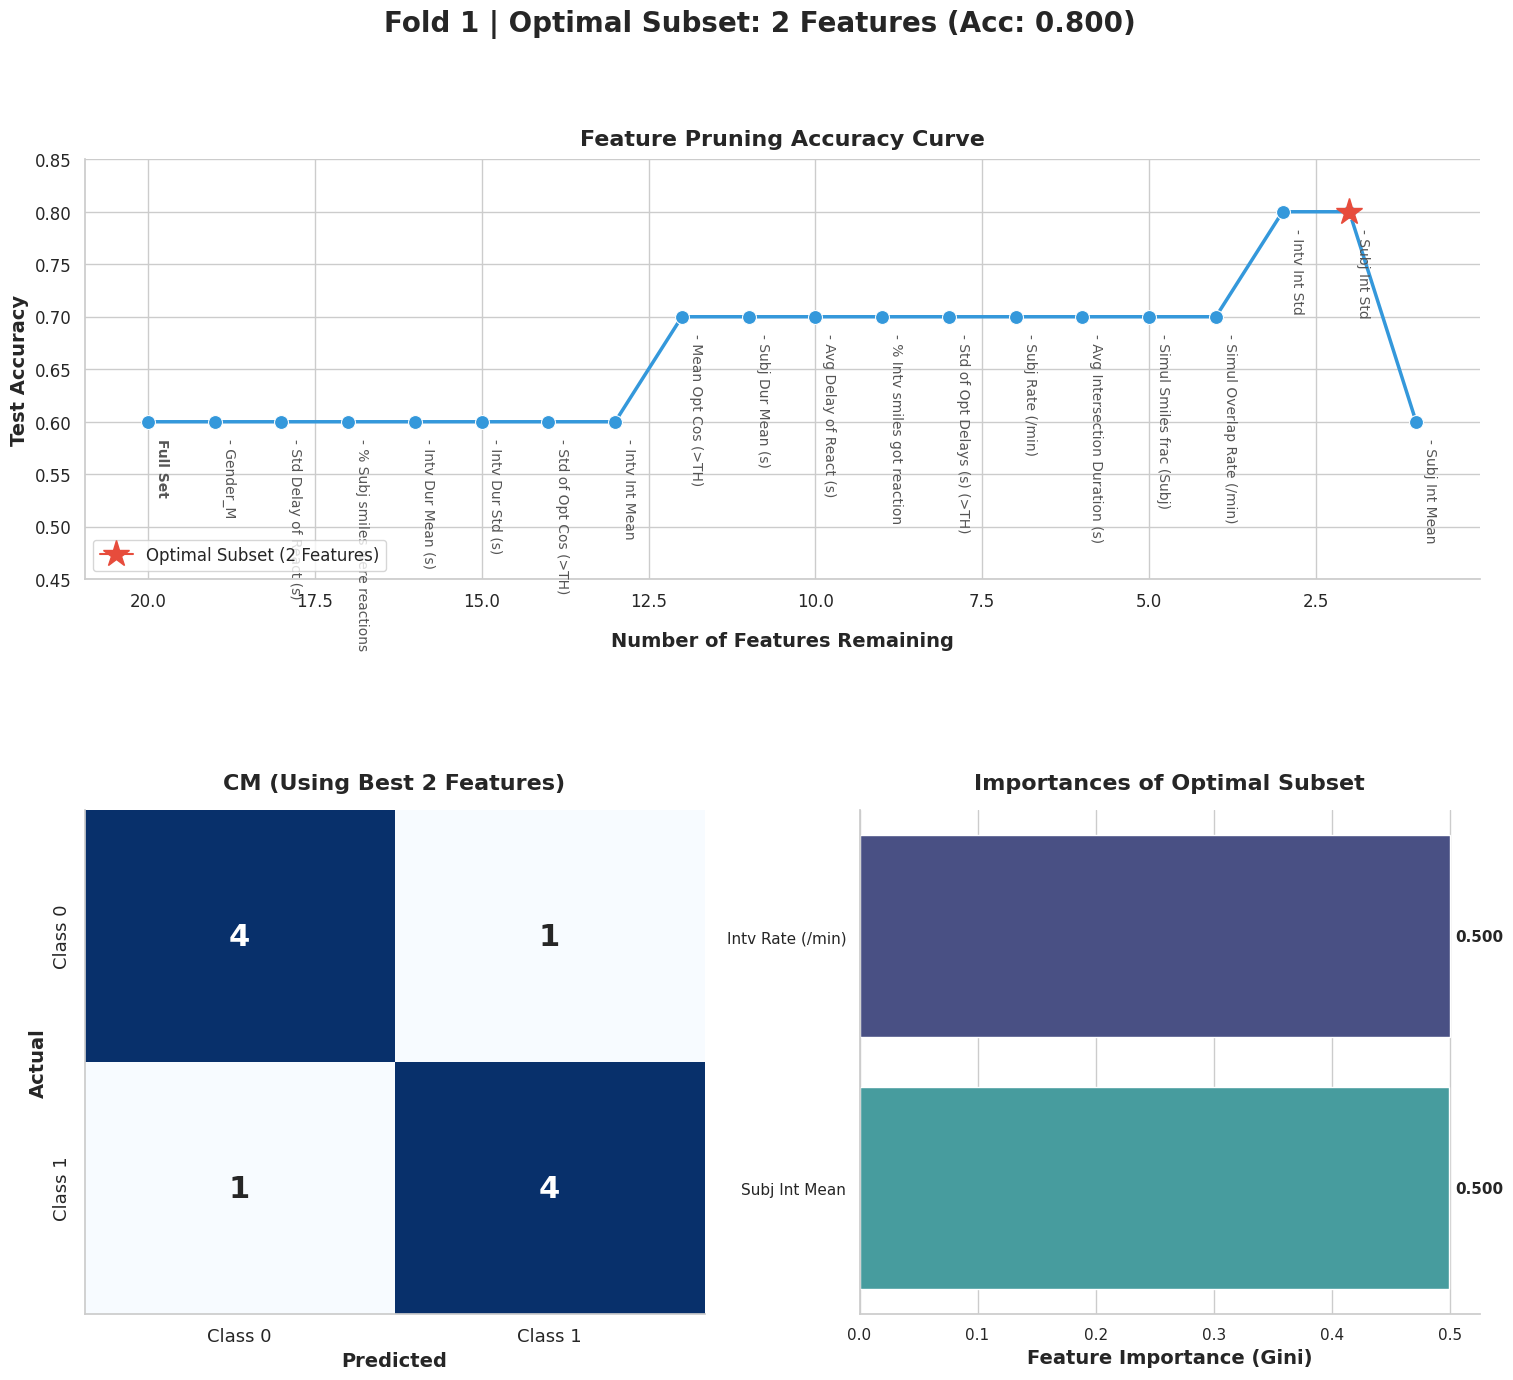

Processing Fold 2/7...


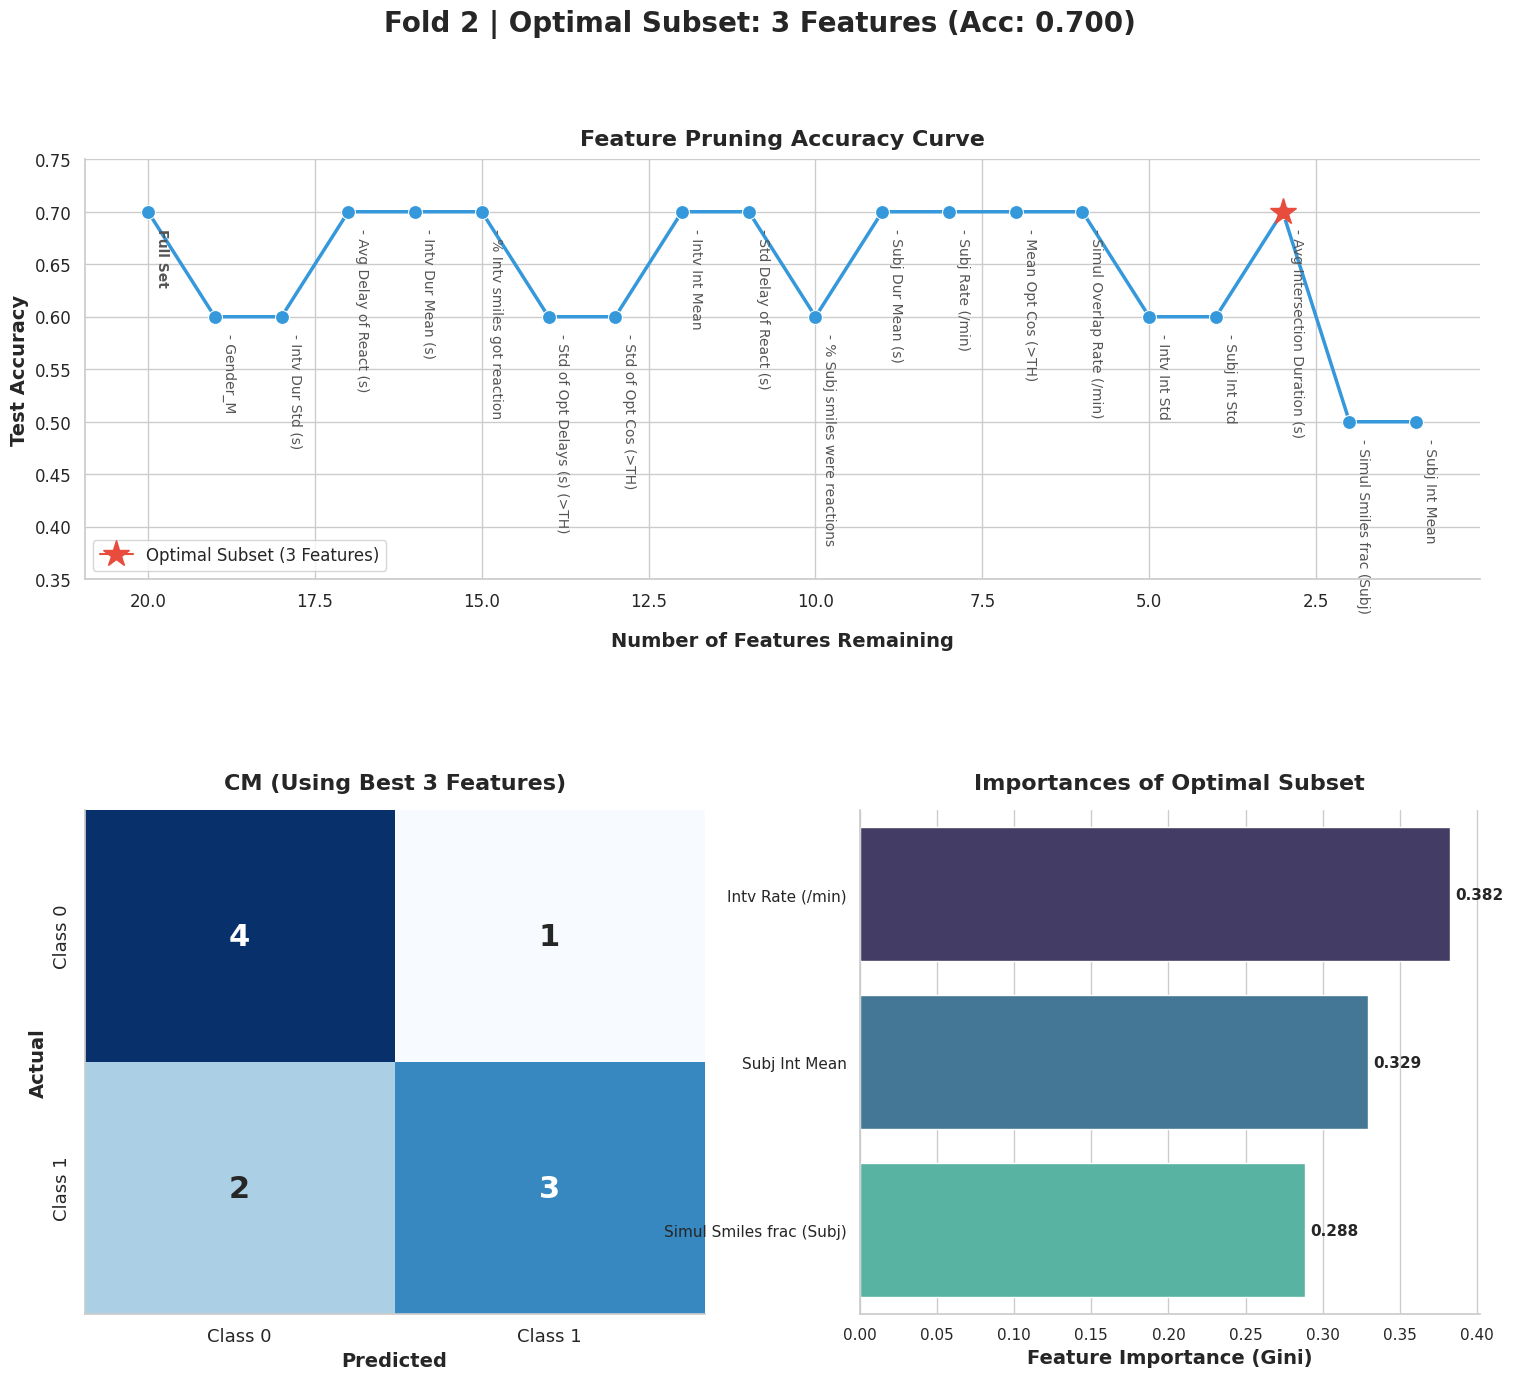

Processing Fold 3/7...


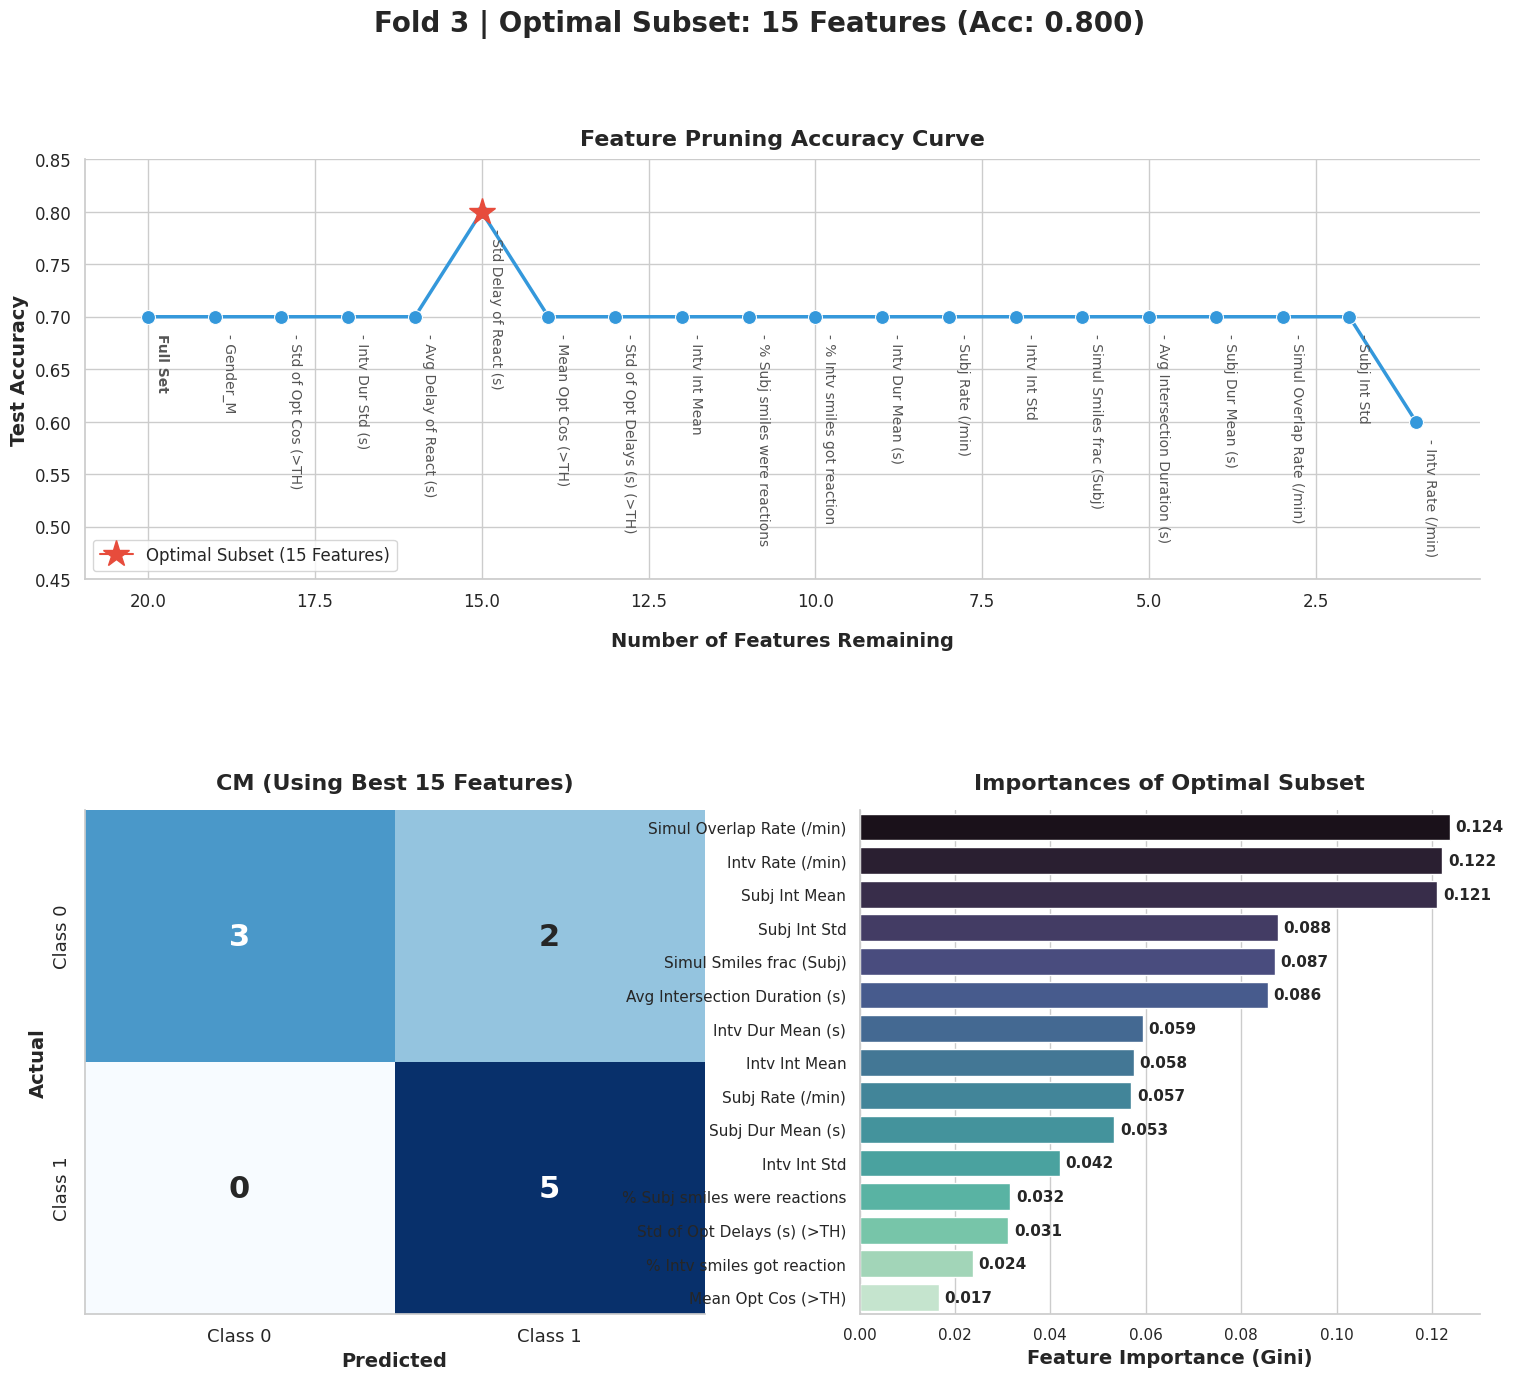

Processing Fold 4/7...


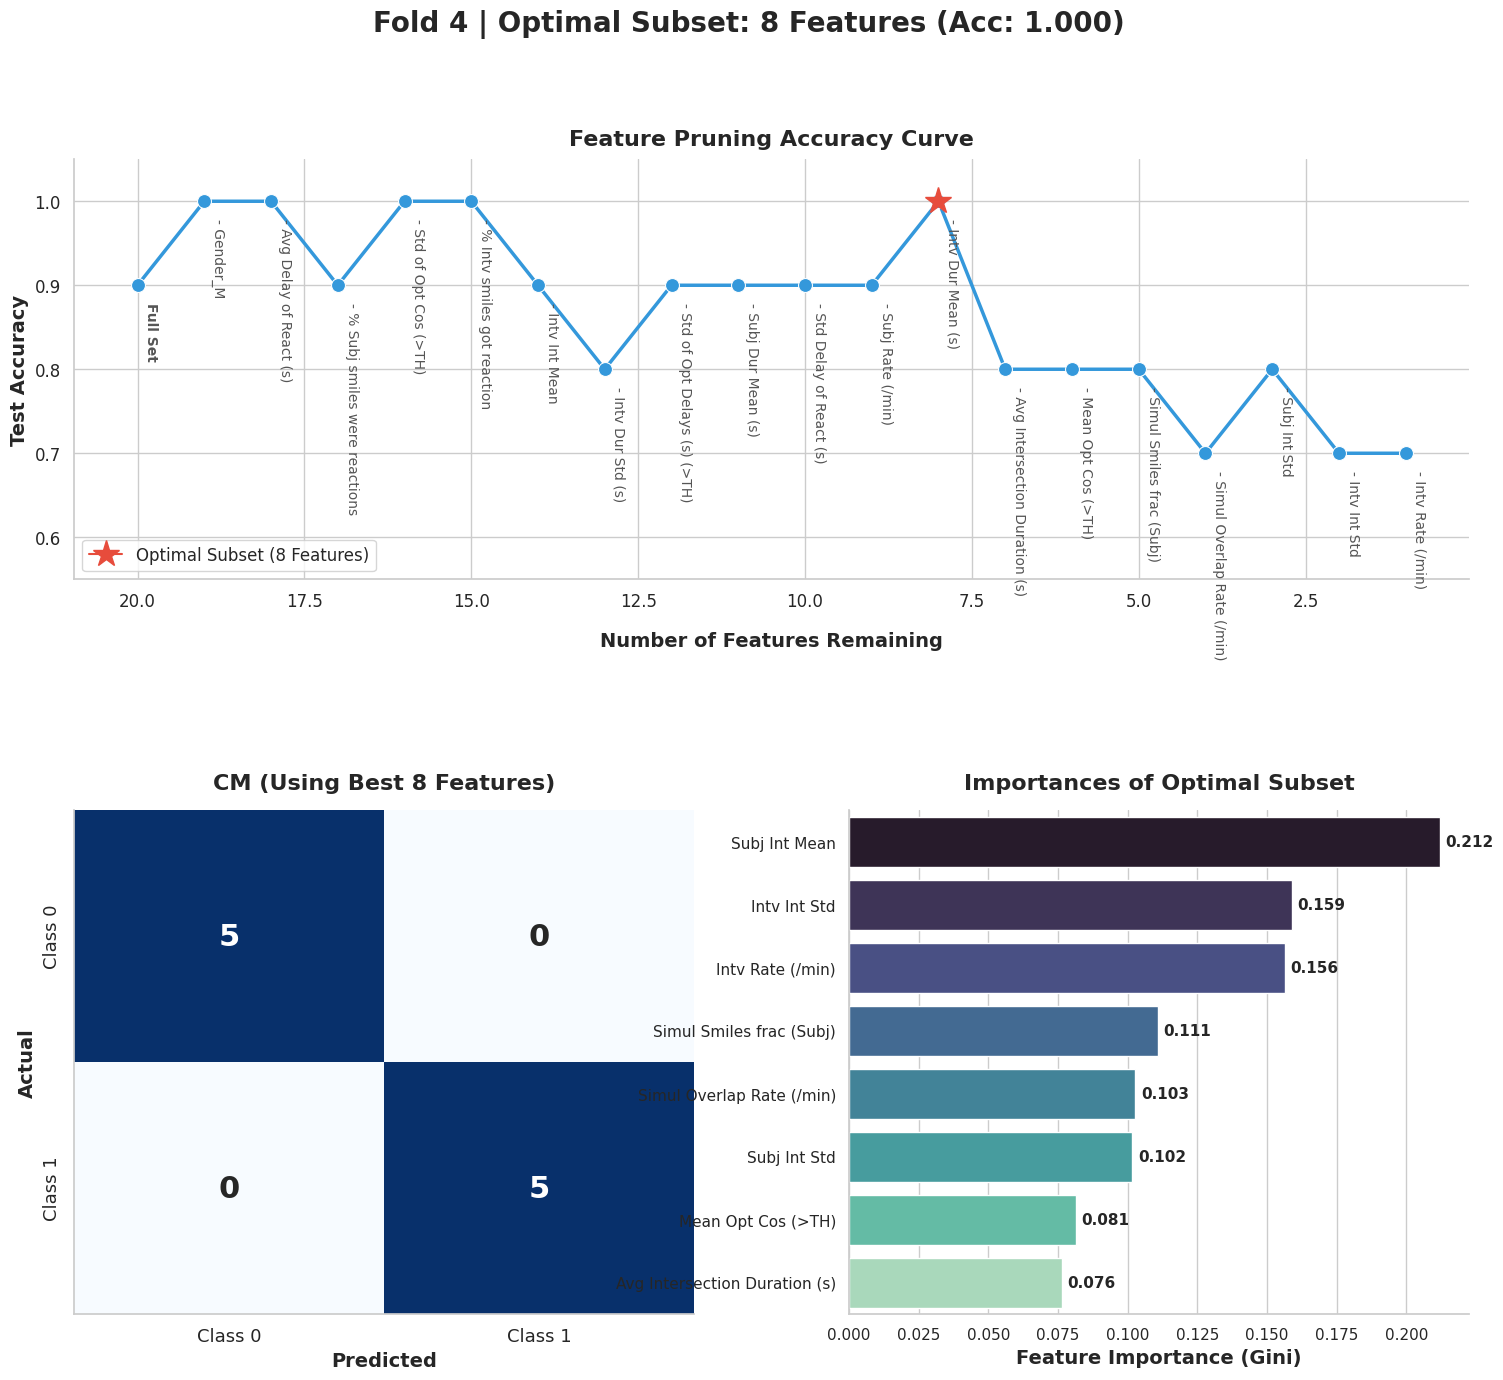

Processing Fold 5/7...


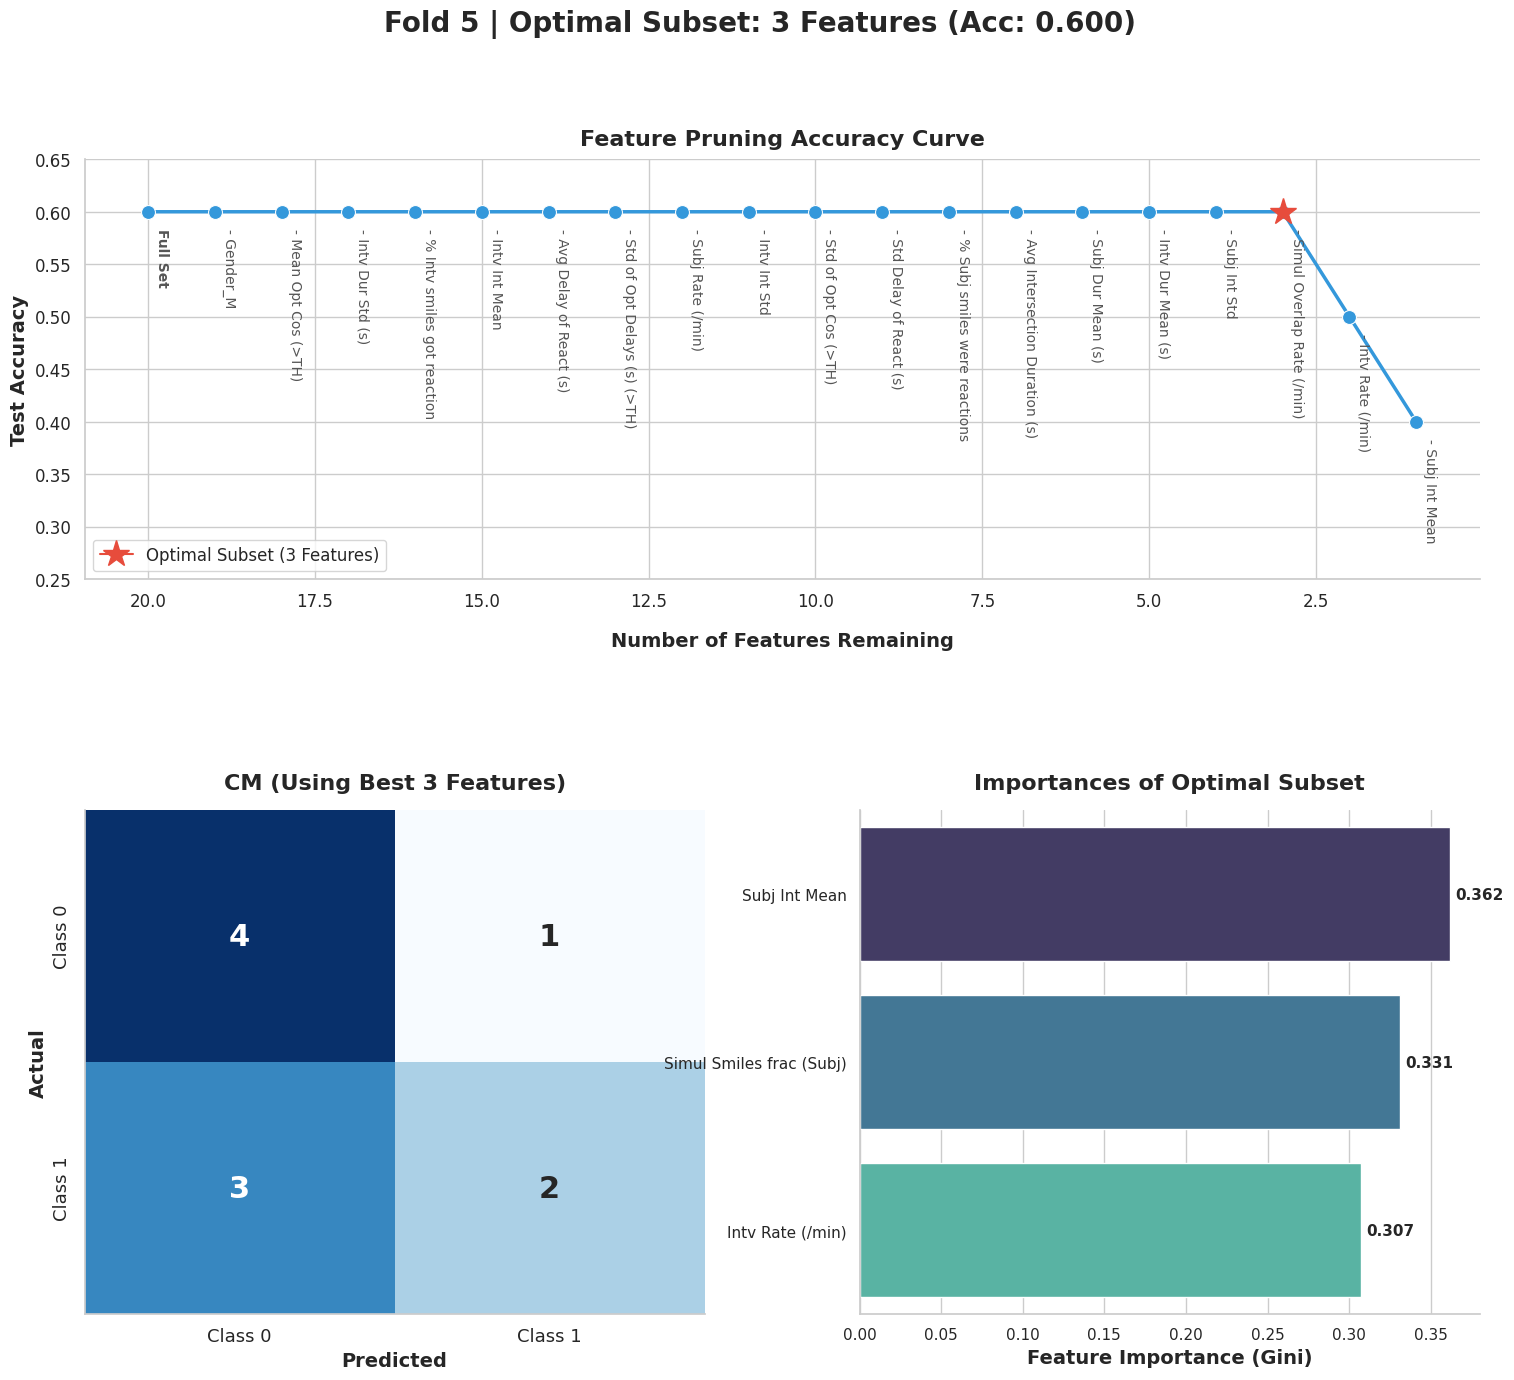

Processing Fold 6/7...


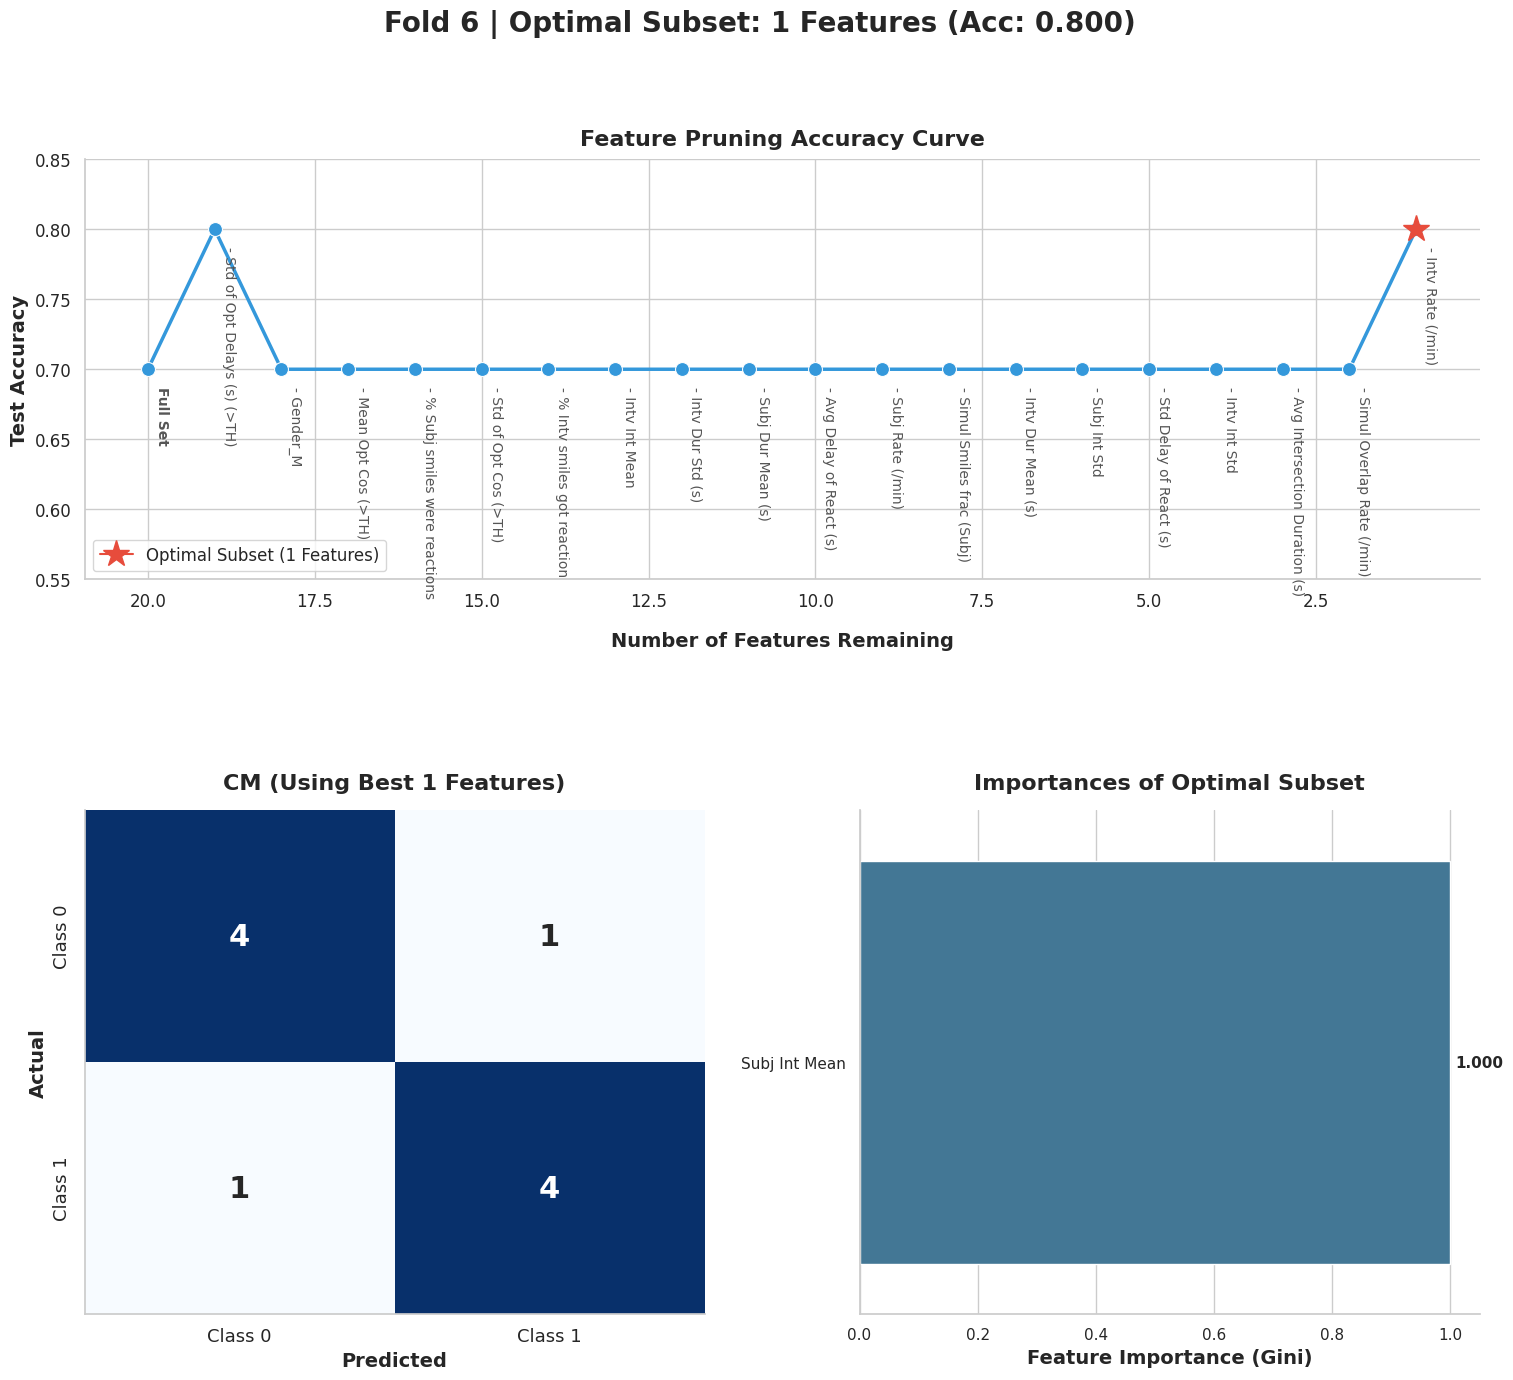

Processing Fold 7/7...


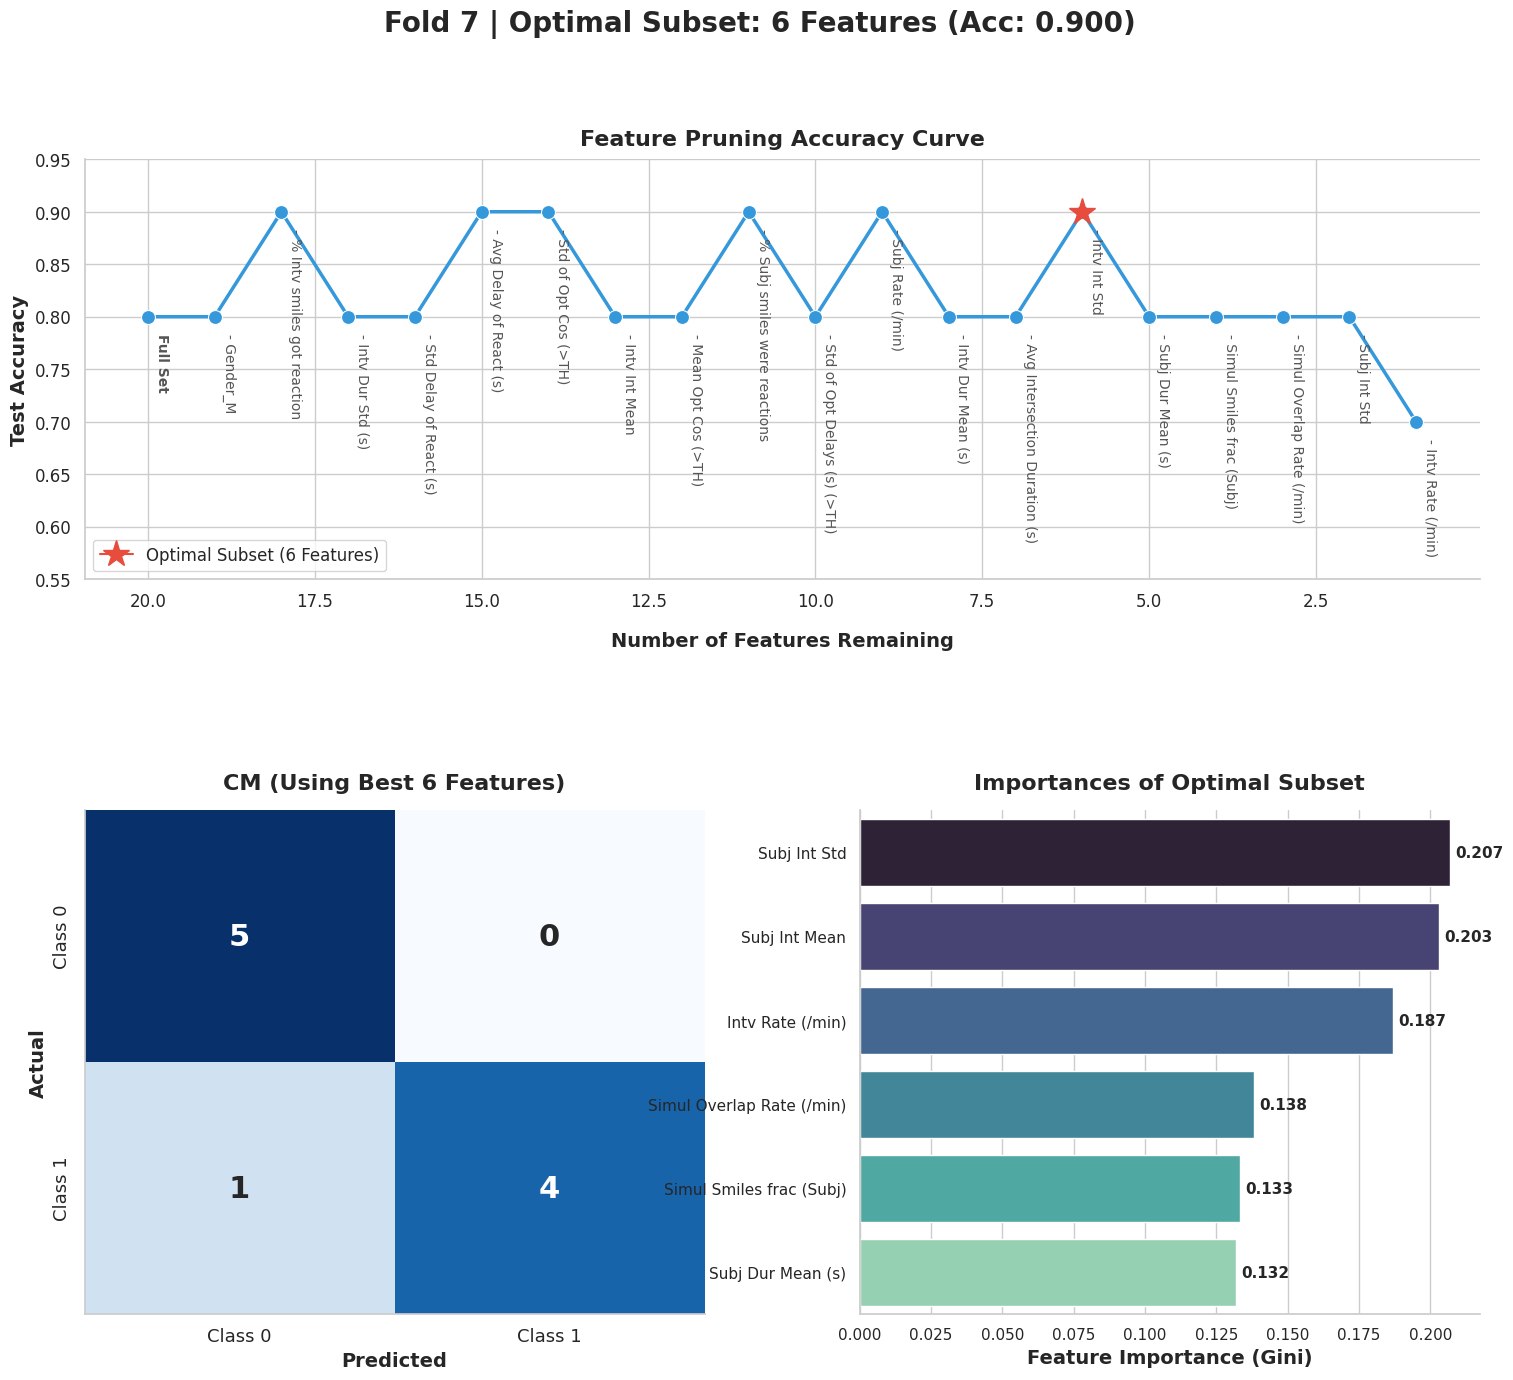

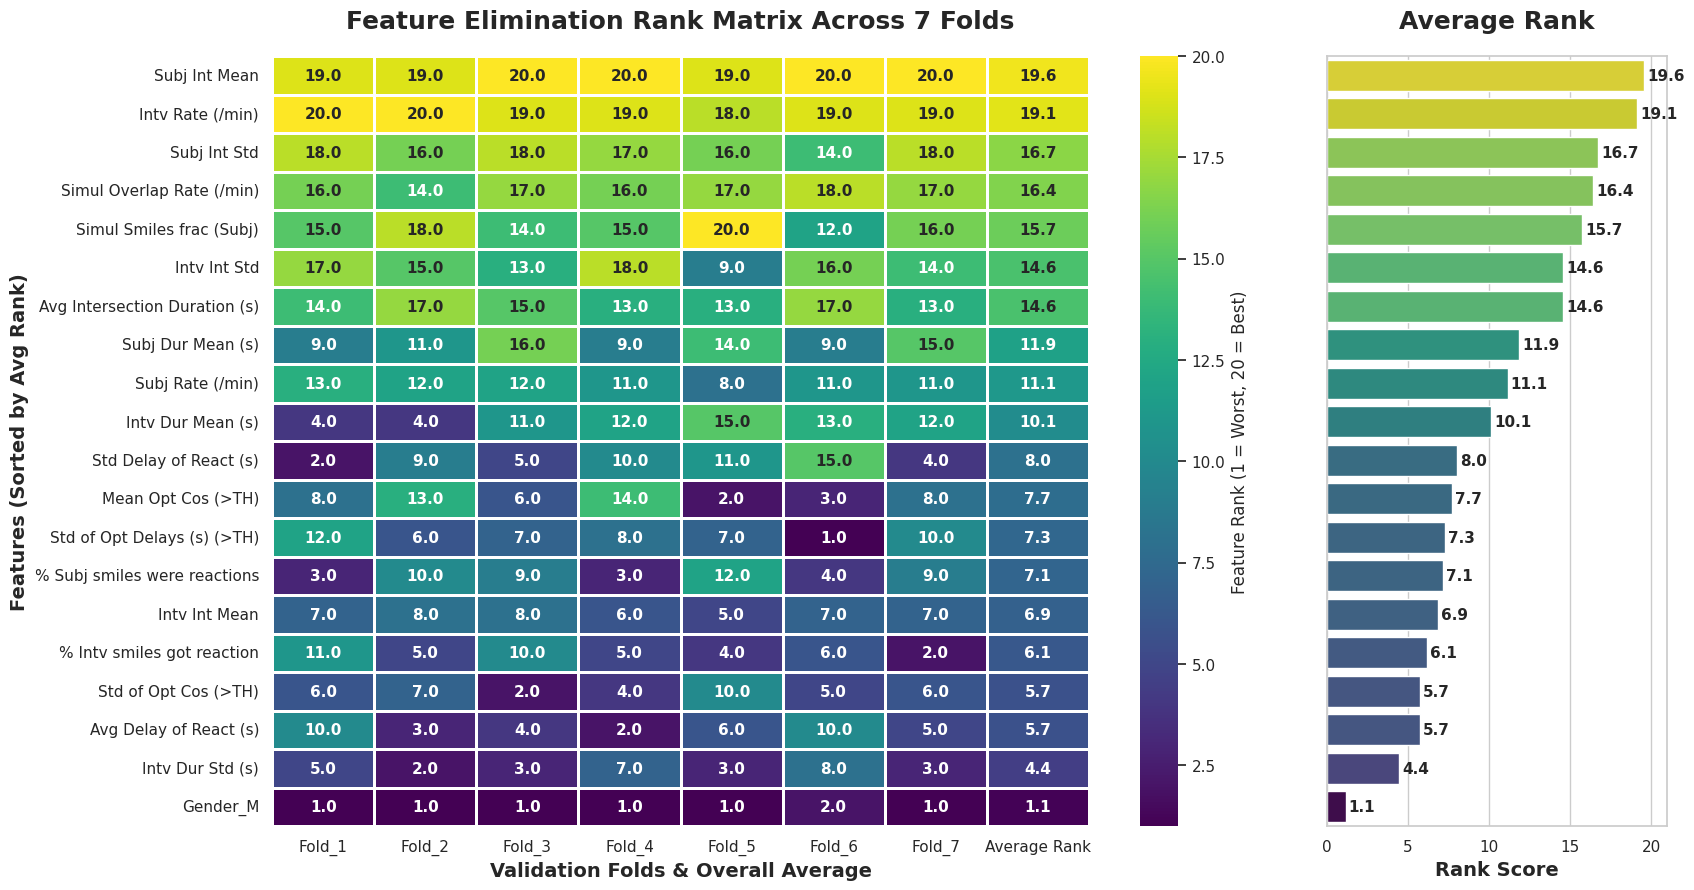


--- Final Top Features from Rank Matrix ---
                           Fold_1  Fold_2  Fold_3  Fold_4  Fold_5  Fold_6  \
Subj Int Mean                  19      19      20      20      19      20   
Intv Rate (/min)               20      20      19      19      18      19   
Subj Int Std                   18      16      18      17      16      14   
Simul Overlap Rate (/min)      16      14      17      16      17      18   
Simul Smiles frac (Subj)       15      18      14      15      20      12   

                           Fold_7  Average Rank  
Subj Int Mean                  20     19.571429  
Intv Rate (/min)               19     19.142857  
Subj Int Std                   18     16.714286  
Simul Overlap Rate (/min)      17     16.428571  
Simul Smiles frac (Subj)       16     15.714286  


In [29]:
if __name__ == "__main__":
    
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Call the new RF function. Notice C_value is removed!
        fold_best_features, rank_df = evaluate_kfold_pruning_rf(X=X_scaled, y=y, K_FOLDS=7)
        
        # Optional: Print out the final surviving features to the console
        print("\n--- Final Top Features from Rank Matrix ---")
        print(rank_df.head())
        
    else:
        print(f"File not found: {DATA_PATH}")

In [30]:
fold_best_features

{'Fold_1': ['Interviewer Smile Rate (per min)',
  'Subject Smile Intensity Mean'],
 'Fold_2': ['Interviewer Smile Rate (per min)',
  'Subject Smile Intensity Mean',
  'Simultaneous Smiles fraction (Subject)'],
 'Fold_3': ['Interviewer Smile Rate (per min)',
  'Subject Smile Rate (per min)',
  'Interviewer Smile Duration Mean (s)',
  'Subject Smile Duration Mean (s)',
  'Interviewer Smile Intensity Mean',
  'Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Subject Smile Intensity Std',
  'Simultaneous Smiles fraction (Subject)',
  'Simultaneous Smiles (Intersections) Rate (per min)',
  'Average Intersection Duration (s)',
  "% of Subject's smiles that were reactions",
  "% of Interviewer's smiles that got a reaction",
  'Mean of Optimal Cosines (>TH)',
  'Std of Optimal Delays (s) (>TH)'],
 'Fold_4': ['Interviewer Smile Rate (per min)',
  'Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Subject Smile Intensity Std',
  'Simultaneous Smiles fra

In [14]:
def evaluate_elected_features_loocv_rf(X, y, elected_features_dict, random_state=42):
    """
    Evaluates each set of elected features using Leave-One-Out Cross-Validation (LOOCV)
    with a Random Forest Classifier.
    Plots a grid where each elected subset gets its own sub-figure showing all metrics.
    """
    total_samples = len(X)
    print(f"\n{'='*80}")
    print(f"EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: {total_samples - 1}, Test: 1)")
    print(f"Model: Random Forest (n_estimators=100, max_depth=3, class_weight='balanced')")
    print(f"{'='*80}\n")
    
    # Initialize the Random Forest with your specified configuration
    rf = RandomForestClassifier(
        n_estimators=100, 
        max_depth=3, 
        class_weight='balanced', 
        random_state=random_state
    )
    
    loo = LeaveOneOut()
    results = []
    
    for fold_name, features in elected_features_dict.items():
        X_subset = X[features]
        
        y_true_all = []
        y_pred_all = []
        
        # The LOOCV Loop
        for train_index, test_index in loo.split(X_subset):
            X_tr, X_te = X_subset.iloc[train_index], X_subset.iloc[test_index]
            y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
            
            rf.fit(X_tr, y_tr)
            pred = rf.predict(X_te)[0]
            
            y_true_all.append(y_te.values[0])
            y_pred_all.append(pred)
            
        acc = accuracy_score(y_true_all, y_pred_all)
        prec = precision_score(y_true_all, y_pred_all, zero_division=0)
        rec = recall_score(y_true_all, y_pred_all, zero_division=0)
        f1 = f1_score(y_true_all, y_pred_all, zero_division=0)
        
        # Abbreviate and wrap the feature names for plotting
        # (Assuming abbreviate_feature_name is already defined in your script)
        short_feats = [abbreviate_feature_name(f) for f in features]
        feat_string = ", ".join(short_feats)
        wrapped_labels = textwrap.fill(feat_string, width=45) # Wrapped for sub-figure titles
        
        results.append({
            'Source': fold_name,
            'Features_Display': wrapped_labels, 
            'Num_Features': len(features),
            'LOO_Accuracy': acc,
            'LOO_Precision': prec,
            'LOO_Recall': rec,
            'LOO_F1_Score': f1
        })
        
    results_df = pd.DataFrame(results)
    
    # Sort by Accuracy, then F1 so the best sets appear first in the grid
    results_df = results_df.sort_values(by=['LOO_Accuracy', 'LOO_F1_Score'], ascending=False).reset_index(drop=True)
    
    # Print tabular summary
    print(results_df[['Source', 'Num_Features', 'LOO_Accuracy', 'LOO_Precision', 'LOO_Recall', 'LOO_F1_Score']].to_string(index=False))
    
    # --- Visualization: Sub-figure per Elected Feature Set ---
    sns.set_theme(style="whitegrid", palette="muted")
    
    num_plots = len(results_df)
    cols = 3
    rows = int(np.ceil(num_plots / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows))
    fig.suptitle('LOOCV Performance Profile by Elected Feature Set (Random Forest)', fontsize=22, fontweight='bold', y=1.02)
    
    axes_flat = axes.flatten() if num_plots > 1 else [axes]
    
    # Iterate through the results and plot each as a separate bar chart
    for i, row in results_df.iterrows():
        ax = axes_flat[i]
        
        # Prepare the 4 metrics for this specific feature set
        plot_data = pd.DataFrame({
            'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
            'Score': [row['LOO_Accuracy'], row['LOO_Precision'], row['LOO_Recall'], row['LOO_F1_Score']]
        })
        
        # Plot
        sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, hue='Metric', palette='mako', legend=False)
        
        # Formatting
        ax.set_ylim(0, 1.15) # Leave room for the labels on top of the bars
        ax.set_ylabel('Score', fontsize=12, fontweight='bold')
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=11, labelrotation=15)
        
        # Set a rich, descriptive title for the subplot
        title_text = f"{row['Source']} | {row['Num_Features']} Features\n{row['Features_Display']}"
        ax.set_title(title_text, fontsize=12, fontweight='bold', color='#2c3e50', pad=12)
        
        # Add numeric labels to bars
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4, size=11, weight='bold')
            
    # Remove any empty subplots if the number of sets doesn't divide evenly by 3
    for j in range(len(results_df), len(axes_flat)):
        fig.delaxes(axes_flat[j])

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return results_df

Preparing data...
Preparation complete: 70 subjects processed.

EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: 69, Test: 1)
Model: Random Forest (n_estimators=100, max_depth=3, class_weight='balanced')

Source  Num_Features  LOO_Accuracy  LOO_Precision  LOO_Recall  LOO_F1_Score
Fold_6             1      0.757143       0.764706    0.742857      0.753623
Fold_4             8      0.714286       0.727273    0.685714      0.705882
Fold_3            15      0.700000       0.705882    0.685714      0.695652
Fold_2             3      0.700000       0.718750    0.657143      0.686567
Fold_5             3      0.700000       0.718750    0.657143      0.686567
Fold_7             6      0.671429       0.676471    0.657143      0.666667
Fold_1             2      0.642857       0.656250    0.600000      0.626866


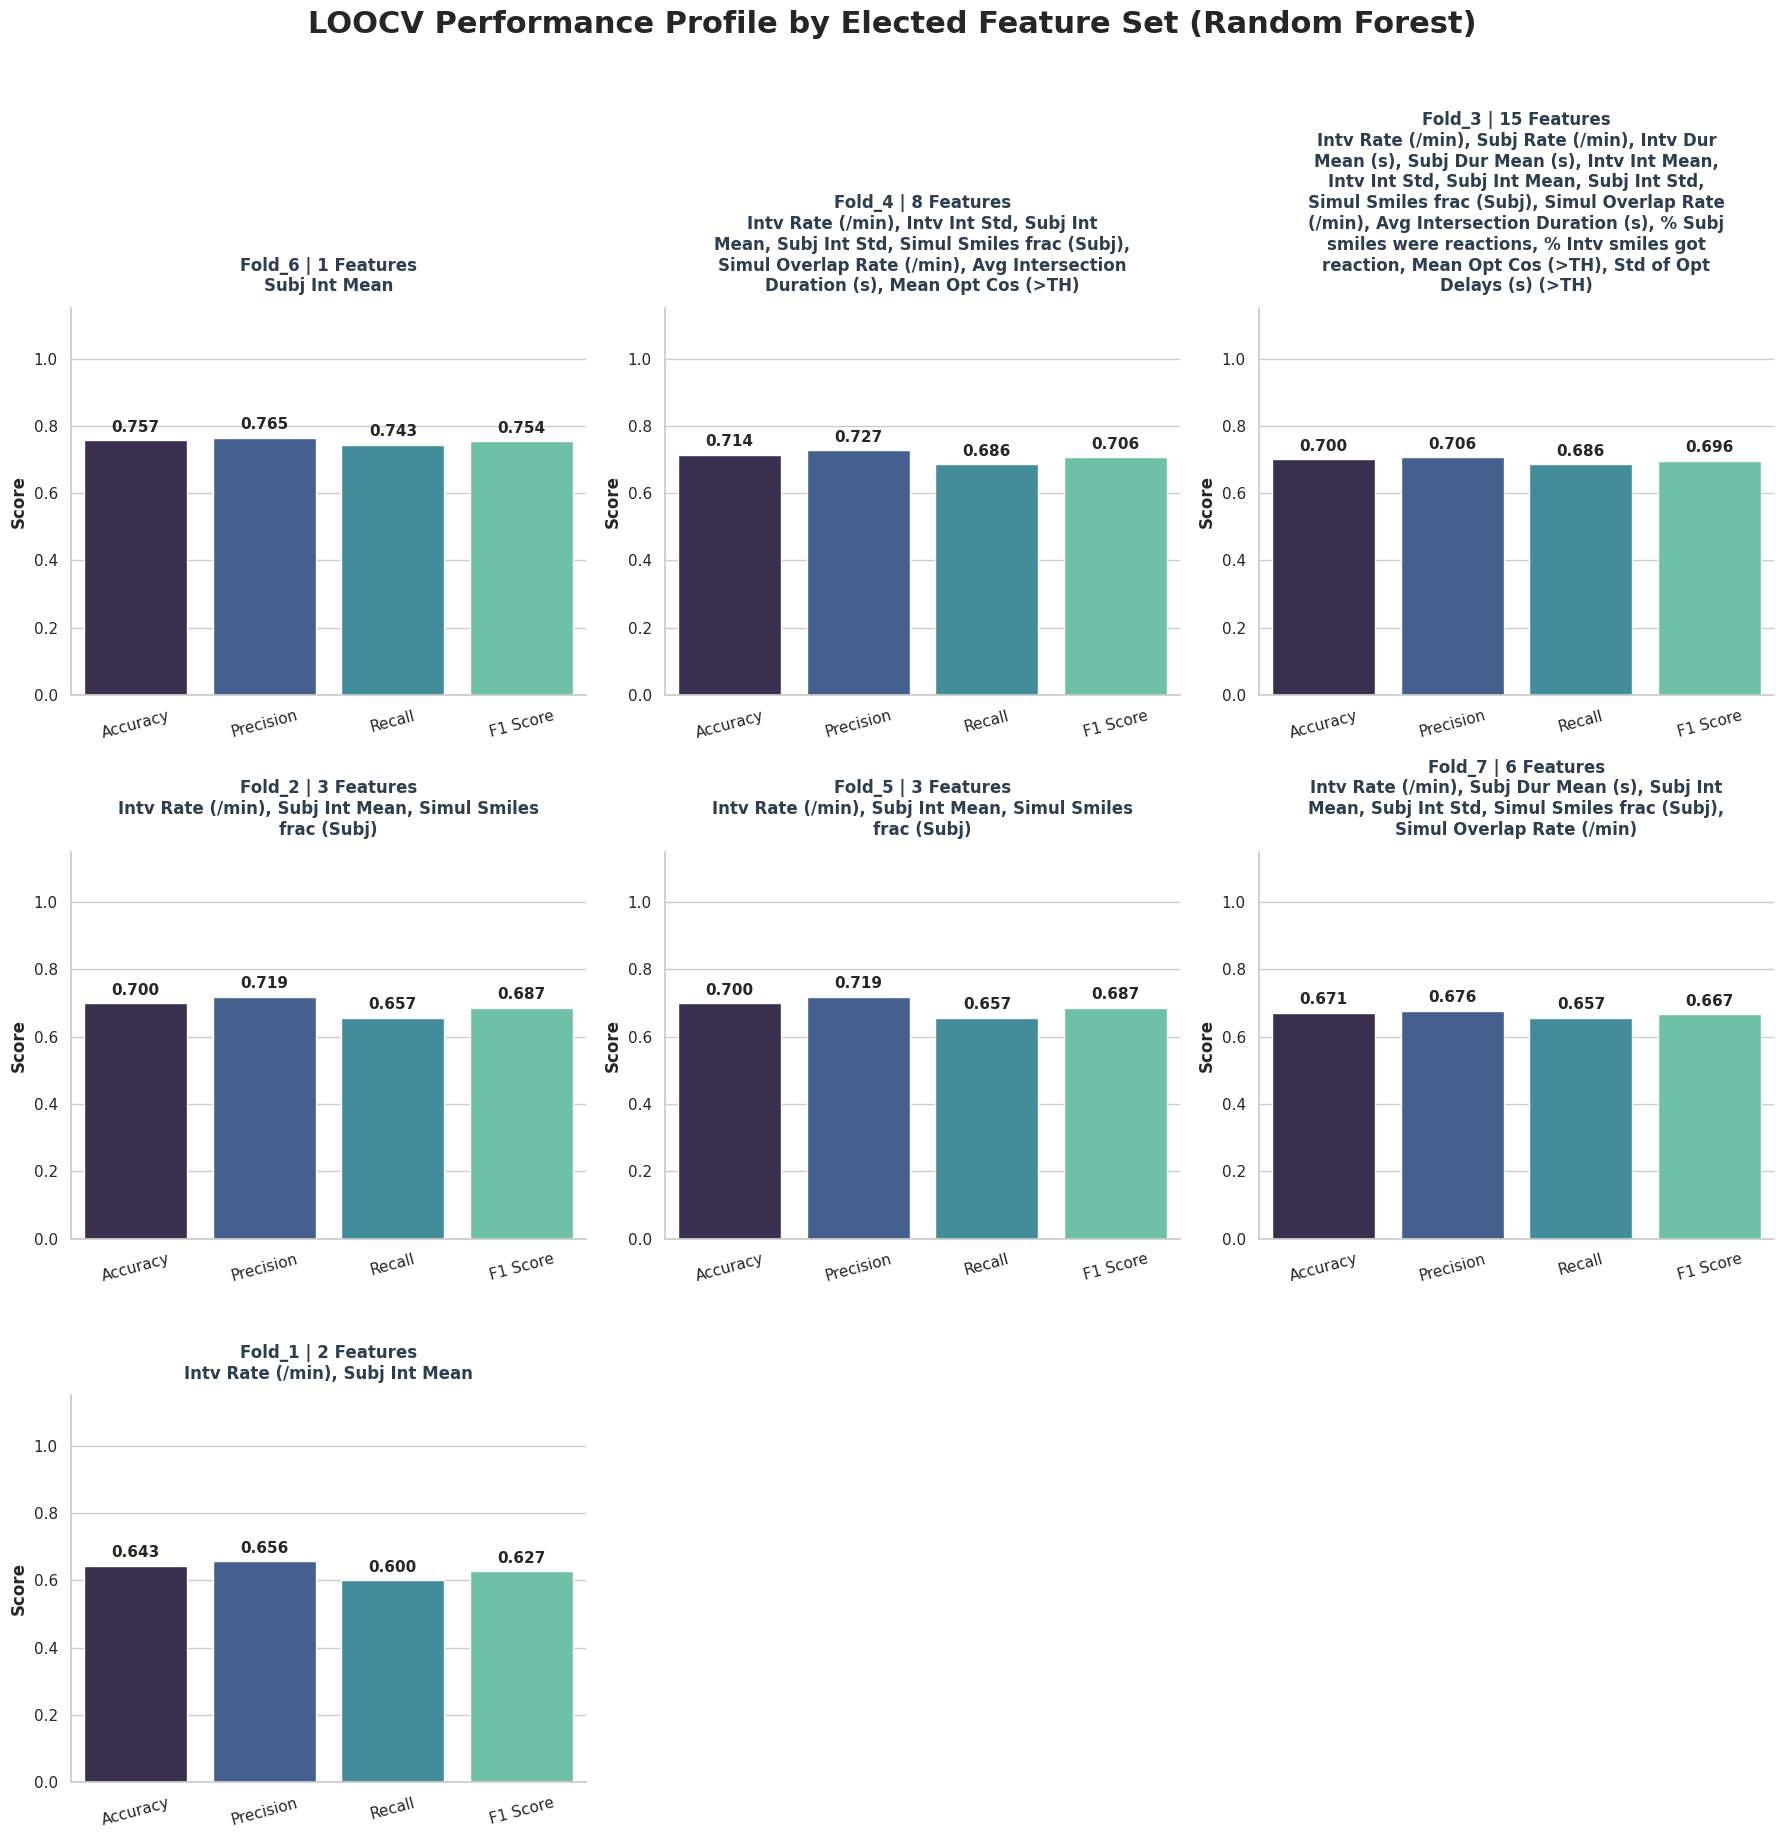

In [18]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # 2. Evaluate the winning feature sets with LOOCV
        loocv_results = evaluate_elected_features_loocv_rf(X=X_scaled, y=y, elected_features_dict=fold_best_features)
        
    else:
        print(f"File not found: {DATA_PATH}")

In [19]:
all_best_festures_set = set()
for i in range(1, 8):
    all_best_festures_set = all_best_festures_set.union(fold_best_features[f'Fold_{i}'])

In [20]:
all_best_festures_set

{"% of Interviewer's smiles that got a reaction",
 "% of Subject's smiles that were reactions",
 'Average Intersection Duration (s)',
 'Interviewer Smile Duration Mean (s)',
 'Interviewer Smile Intensity Mean',
 'Interviewer Smile Intensity Std',
 'Interviewer Smile Rate (per min)',
 'Mean of Optimal Cosines (>TH)',
 'Simultaneous Smiles (Intersections) Rate (per min)',
 'Simultaneous Smiles fraction (Subject)',
 'Std of Optimal Delays (s) (>TH)',
 'Subject Smile Duration Mean (s)',
 'Subject Smile Intensity Mean',
 'Subject Smile Intensity Std',
 'Subject Smile Rate (per min)'}

In [25]:
def plot_consensus_elimination_step_rf(rank_df, df_current_metrics, dropped_feature_display, iteration, total_features):
    """
    Plots the Rank Matrix and Average Rank Bar Chart.
    The bottom subplots now show the CV performance of the current global subset across folds.
    """
    sns.set_theme(style="whitegrid")
    
    fig_height = max(12, (total_features * 0.5) + 6)
    fig = plt.figure(figsize=(18, fig_height))
    gs = fig.add_gridspec(2, 4, height_ratios=[2.5, 1.5], wspace=0.3, hspace=0.4)
    
    ax_heatmap = fig.add_subplot(gs[0, 0:3]) 
    ax_bar = fig.add_subplot(gs[0, 3])       
    
    ax_acc = fig.add_subplot(gs[1, 0])
    ax_f1 = fig.add_subplot(gs[1, 1])
    ax_prec = fig.add_subplot(gs[1, 2])
    ax_rec = fig.add_subplot(gs[1, 3])
    
    metric_axes = {'Accuracy': ax_acc, 'F1-Score': ax_f1, 'Precision': ax_prec, 'Recall': ax_rec}
    
    # ---------------------------------------------------------
    # 1. Top-Left: The Rank Matrix (Heatmap)
    # ---------------------------------------------------------
    heatmap_data = rank_df.drop(columns=['Average Rank'])
    sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="viridis", 
                cbar_kws={'label': 'Survival Rank (1 = Eliminated First)'},
                linewidths=1, ax=ax_heatmap, annot_kws={"size": 11, "weight": "bold"})
    
    ax_heatmap.set_title(f'Iteration {iteration}: Survival Rank Matrix Across Folds', 
                         fontsize=16, fontweight='bold', pad=15)
    ax_heatmap.set_ylabel('Features (Sorted by Avg Rank)', fontsize=13, fontweight='bold')
    ax_heatmap.set_xlabel('Validation Folds', fontsize=13, fontweight='bold')
    ax_heatmap.tick_params(axis='y', rotation=0, labelsize=11)
    
    # ---------------------------------------------------------
    # 2. Top-Right: Average Rank (Bar Chart)
    # ---------------------------------------------------------
    avg_ranks = rank_df['Average Rank'].values
    features = rank_df.index
    
    colors = ['#e74c3c' if feat == dropped_feature_display else '#3498db' for feat in features]
    sns.barplot(x=avg_ranks, y=features, ax=ax_bar, palette=colors, hue=features, legend=False)
    
    ax_bar.set_title(f'Average Rank\nEliminating: {dropped_feature_display}', 
                     fontsize=15, fontweight='bold', color='#e74c3c', pad=15)
    ax_bar.set_xlabel('Average Score', fontsize=13, fontweight='bold')
    ax_bar.set_xlim(0, total_features + 1) 
    ax_bar.set_ylabel('')
    ax_bar.tick_params(axis='y', labelleft=False, left=False)
    ax_bar.grid(axis='y', visible=False)
    
    for i, val in enumerate(avg_ranks):
        is_dropped = (features[i] == dropped_feature_display)
        fw = 'bold' if is_dropped else 'normal'
        c = '#e74c3c' if is_dropped else 'black'
        ax_bar.text(val + 0.1, i, f'{val:.2f}', va='center', fontsize=11, fontweight=fw, color=c)

    # ---------------------------------------------------------
    # 3. Bottom: CV Metrics for the Current Feature Set
    # ---------------------------------------------------------
    for metric_name, ax in metric_axes.items():
        sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
        
        ax.set_title(f"{metric_name} ({total_features} Features)", fontsize=13, fontweight='bold')
        ax.set_ylim(0, 1.1)
        ax.set_xlabel("")
        ax.set_ylabel("")
        
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4, size=10, weight='bold')

    fig.suptitle(f"Global RFE Iteration {iteration} | Evaluating {total_features} Features", fontsize=18, fontweight='bold', y=0.98)
    
    sns.despine()
    plt.tight_layout()
    plt.show()
    plt.close(fig)

# =============================================================================
# Global Consensus RFE (Optimized for Random Forest)
# =============================================================================
def consensus_global_rfe_rf(X, y, initial_features, K_FOLDS=7):
    
    current_features = list(initial_features)
    iteration = 1
    elimination_history = []
    
    print(f"\n{'='*80}")
    print(f"STARTING CONSENSUS GLOBAL RFE (Random Forest | {len(current_features)} Initial Features)")
    print(f"{'='*80}\n")
    
    # n_jobs=-1 forces the RF to use all CPU cores, vastly speeding up execution
    rf = RandomForestClassifier(n_estimators=100, max_depth=3, class_weight='balanced', random_state=42, n_jobs=-1)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    while len(current_features) > 1:
        num_feats_this_round = len(current_features)
        print(f"--- Iteration {iteration} | Evaluating {num_feats_this_round} Features ---")
        
        feature_ranks = {feat: {} for feat in current_features}
        current_metrics_records = []
        
        # 1. Run K-Fold (Fit ONCE per fold)
        for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
            X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
            y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
            
            # A. Train model and Predict
            rf.fit(X_tr[current_features], y_tr)
            y_pred = rf.predict(X_te[current_features])
            
            # B. Record metrics for this fold
            current_metrics_records.append({
                'Fold': f"F{fold}",
                'Accuracy': accuracy_score(y_te, y_pred),
                'F1-Score': f1_score(y_te, y_pred, average='weighted', zero_division=0),
                'Precision': precision_score(y_te, y_pred, average='weighted', zero_division=0),
                'Recall': recall_score(y_te, y_pred, average='weighted', zero_division=0)
            })
            
            # C. Extract Importances and convert directly to Ranks (1 = Lowest/Worst, N = Highest/Best)
            importances = rf.feature_importances_
            ranks = rankdata(importances, method='average') 
            
            for feat, rank in zip(current_features, ranks):
                feature_ranks[feat][f"Fold_{fold}"] = rank
                
        # 2. Compile metrics DataFrame
        df_current_metrics = pd.DataFrame(current_metrics_records)
                
        # 3. Build the Rank Matrix and Calculate Global Averages
        rank_df = pd.DataFrame(feature_ranks).T
        rank_df['Average Rank'] = rank_df.mean(axis=1)
        
        # Sort so Best (Highest Avg Rank) is at the top, Worst is at the bottom
        rank_df = rank_df.sort_values(by='Average Rank', ascending=False)
        
        # 4. Identify the weakest feature across all folds
        feature_to_drop = rank_df.index[-1]
        
        # 5. Format Dataframe for Plotting
        plot_df = rank_df.copy()
        plot_df.index = [abbreviate_feature_name(idx) for idx in plot_df.index]
        dropped_display_name = abbreviate_feature_name(feature_to_drop)
        
        # 6. Plot the Dashboard
        plot_consensus_elimination_step_rf(plot_df, df_current_metrics, dropped_display_name, iteration, num_feats_this_round)
        
        # 7. Execute the Elimination
        print(f"> Eliminating weakest feature: {feature_to_drop} (Avg Rank: {rank_df['Average Rank'].iloc[-1]:.2f})\n")
        current_features.remove(feature_to_drop)
        
        base_acc = df_current_metrics['Accuracy'].mean()
        
        elimination_history.append({
            'Iteration': iteration,
            'Dropped_Feature': feature_to_drop,
            'Avg_Rank_At_Drop': rank_df['Average Rank'].iloc[-1],
            'Mean_CV_Accuracy': base_acc
        })
        
        iteration += 1

    print(f"{'='*80}")
    print(f"RFE COMPLETE. FINAL SURVIVING FEATURE: {current_features[0]}")
    print(f"{'='*80}")
    
    return current_features[0], pd.DataFrame(elimination_history)

Total Unique Best Features Extracted: 15

STARTING CONSENSUS GLOBAL RFE (Random Forest | 15 Initial Features)

--- Iteration 1 | Evaluating 15 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

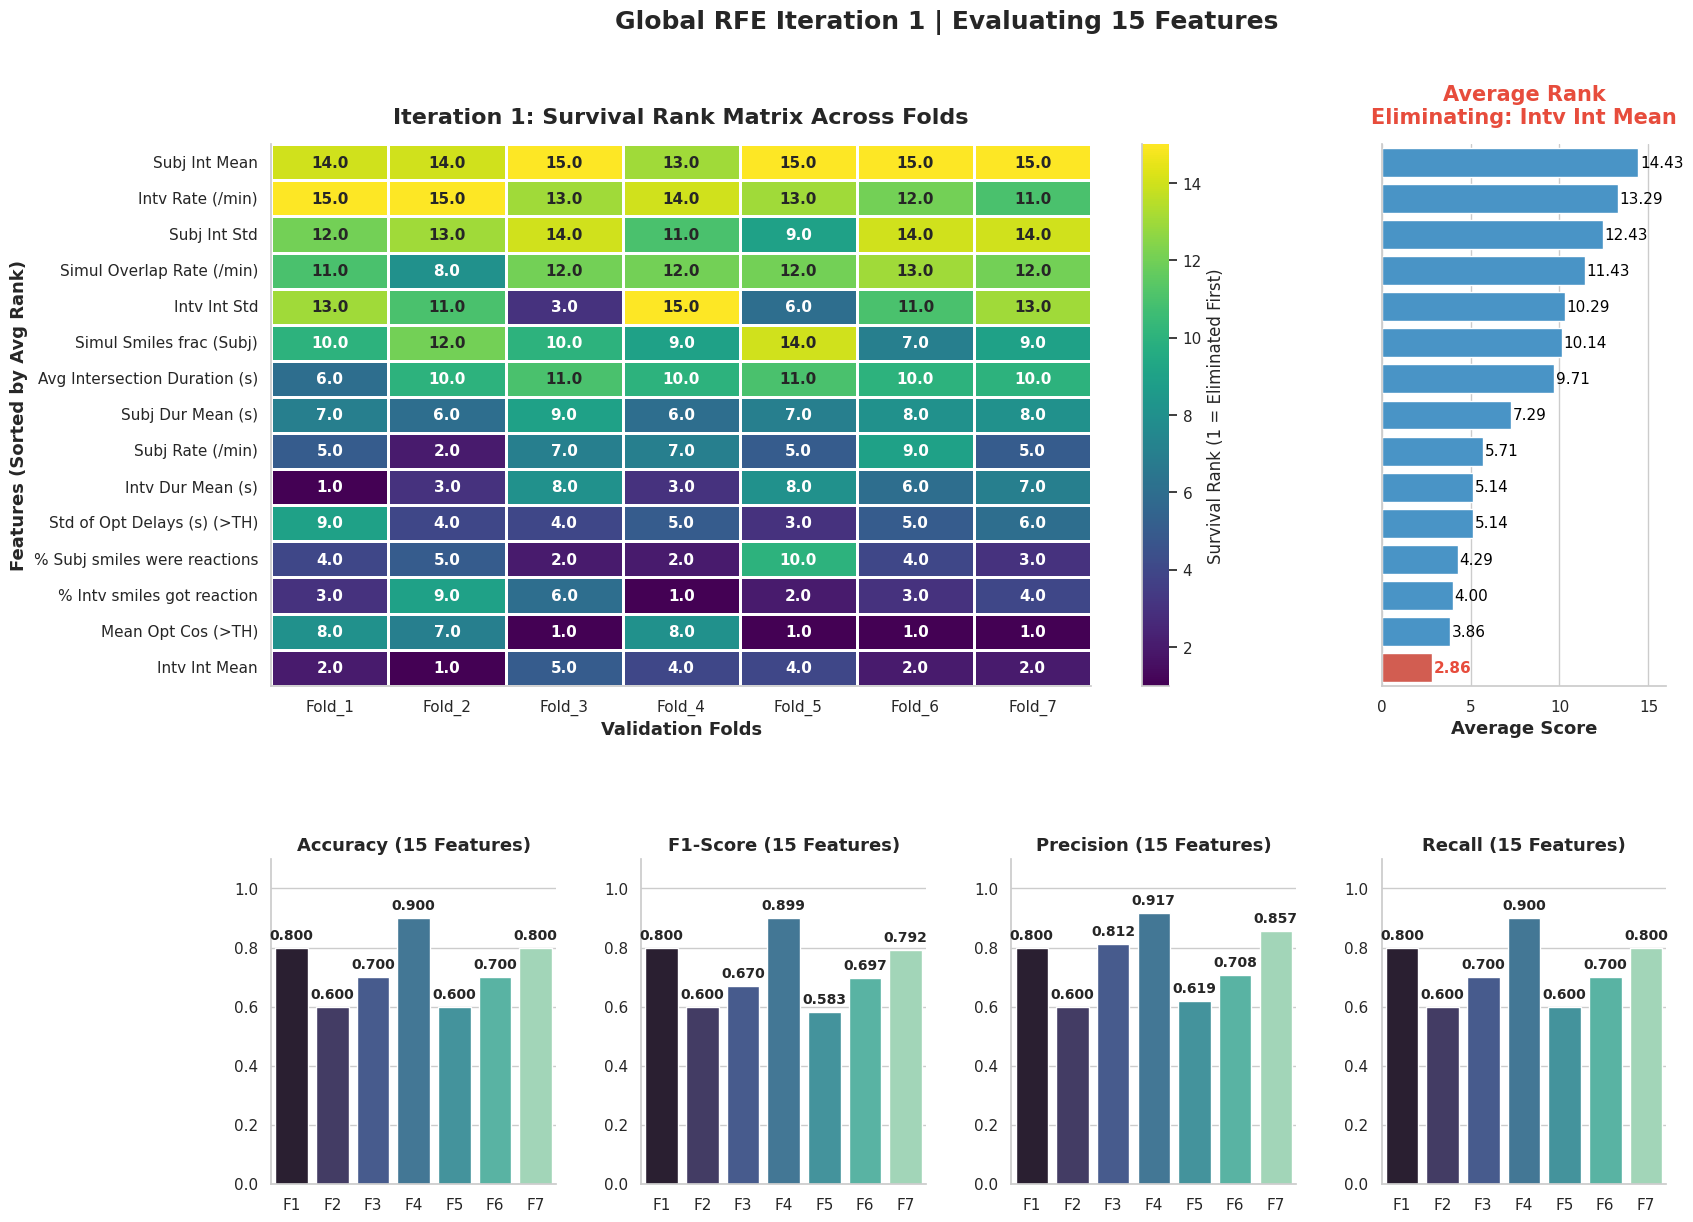

> Eliminating weakest feature: Interviewer Smile Intensity Mean (Avg Rank: 2.86)

--- Iteration 2 | Evaluating 14 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

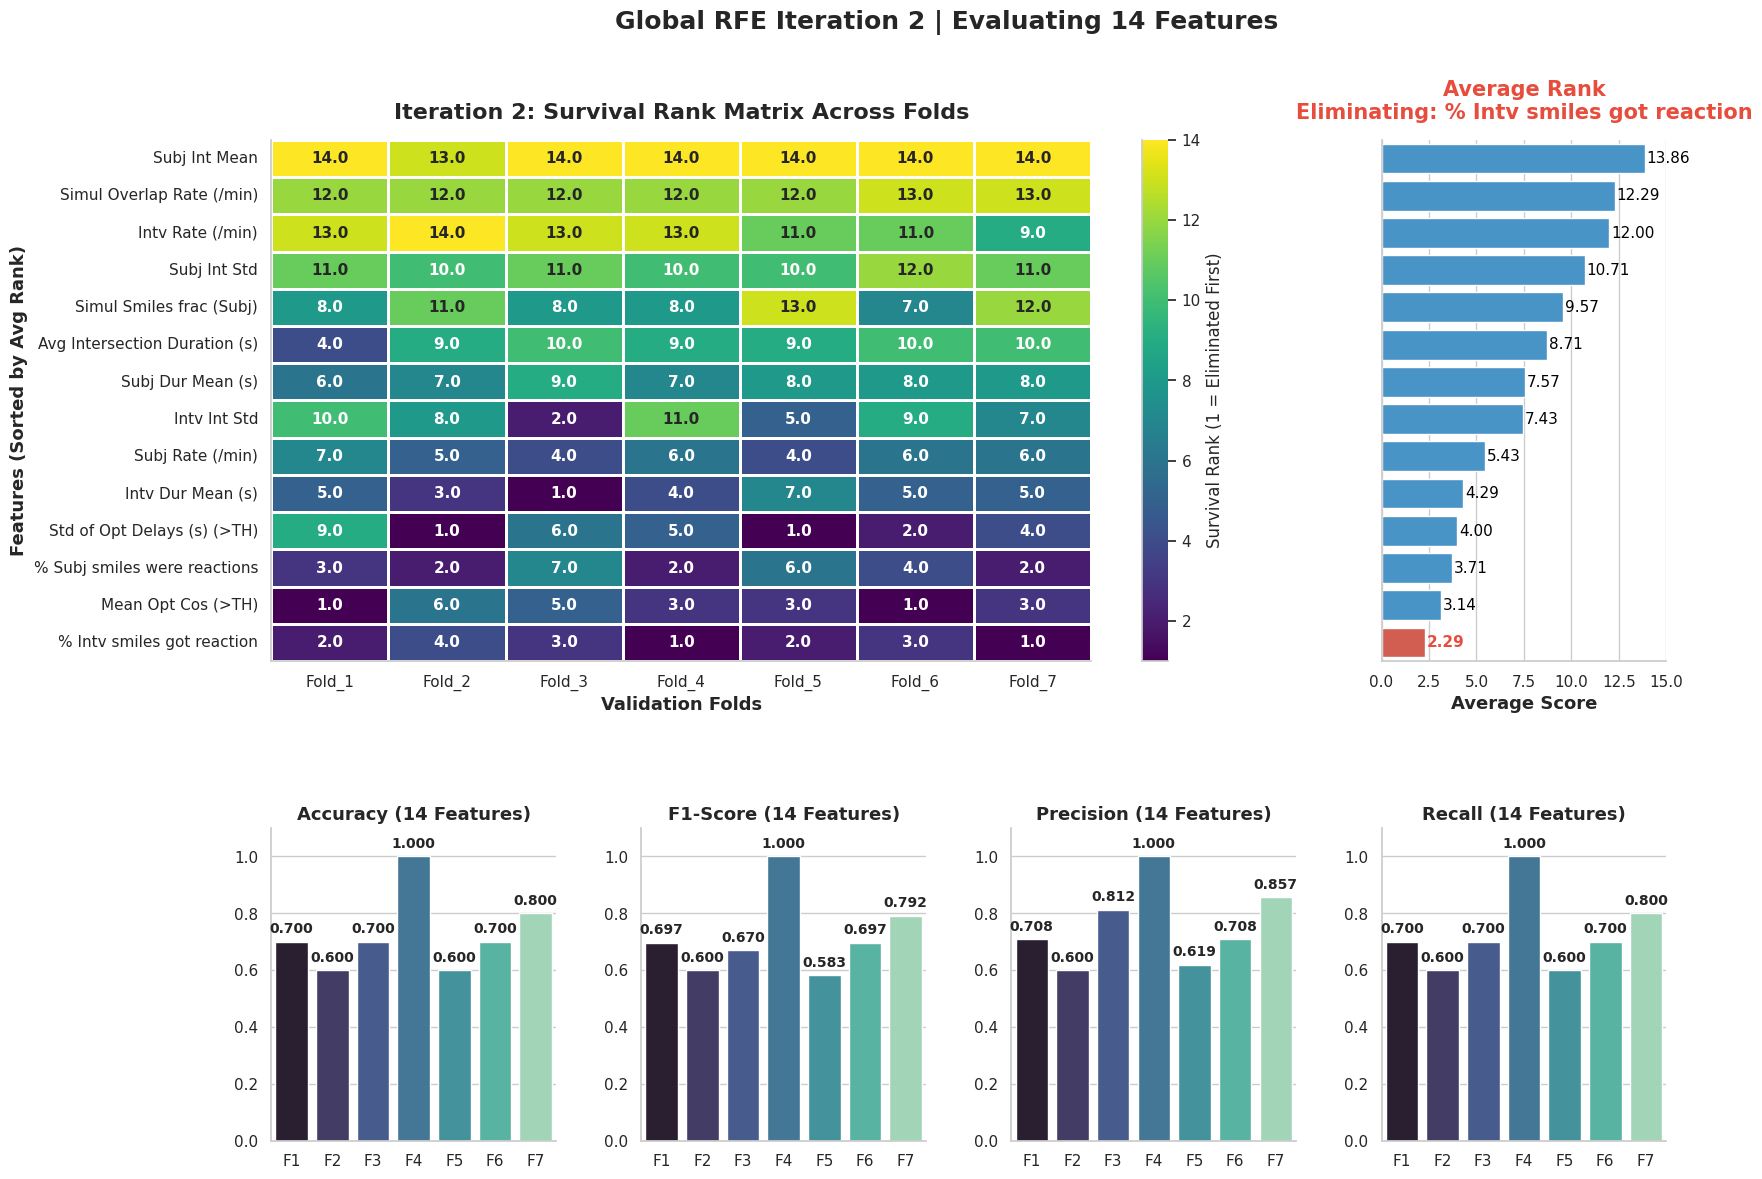

> Eliminating weakest feature: % of Interviewer's smiles that got a reaction (Avg Rank: 2.29)

--- Iteration 3 | Evaluating 13 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

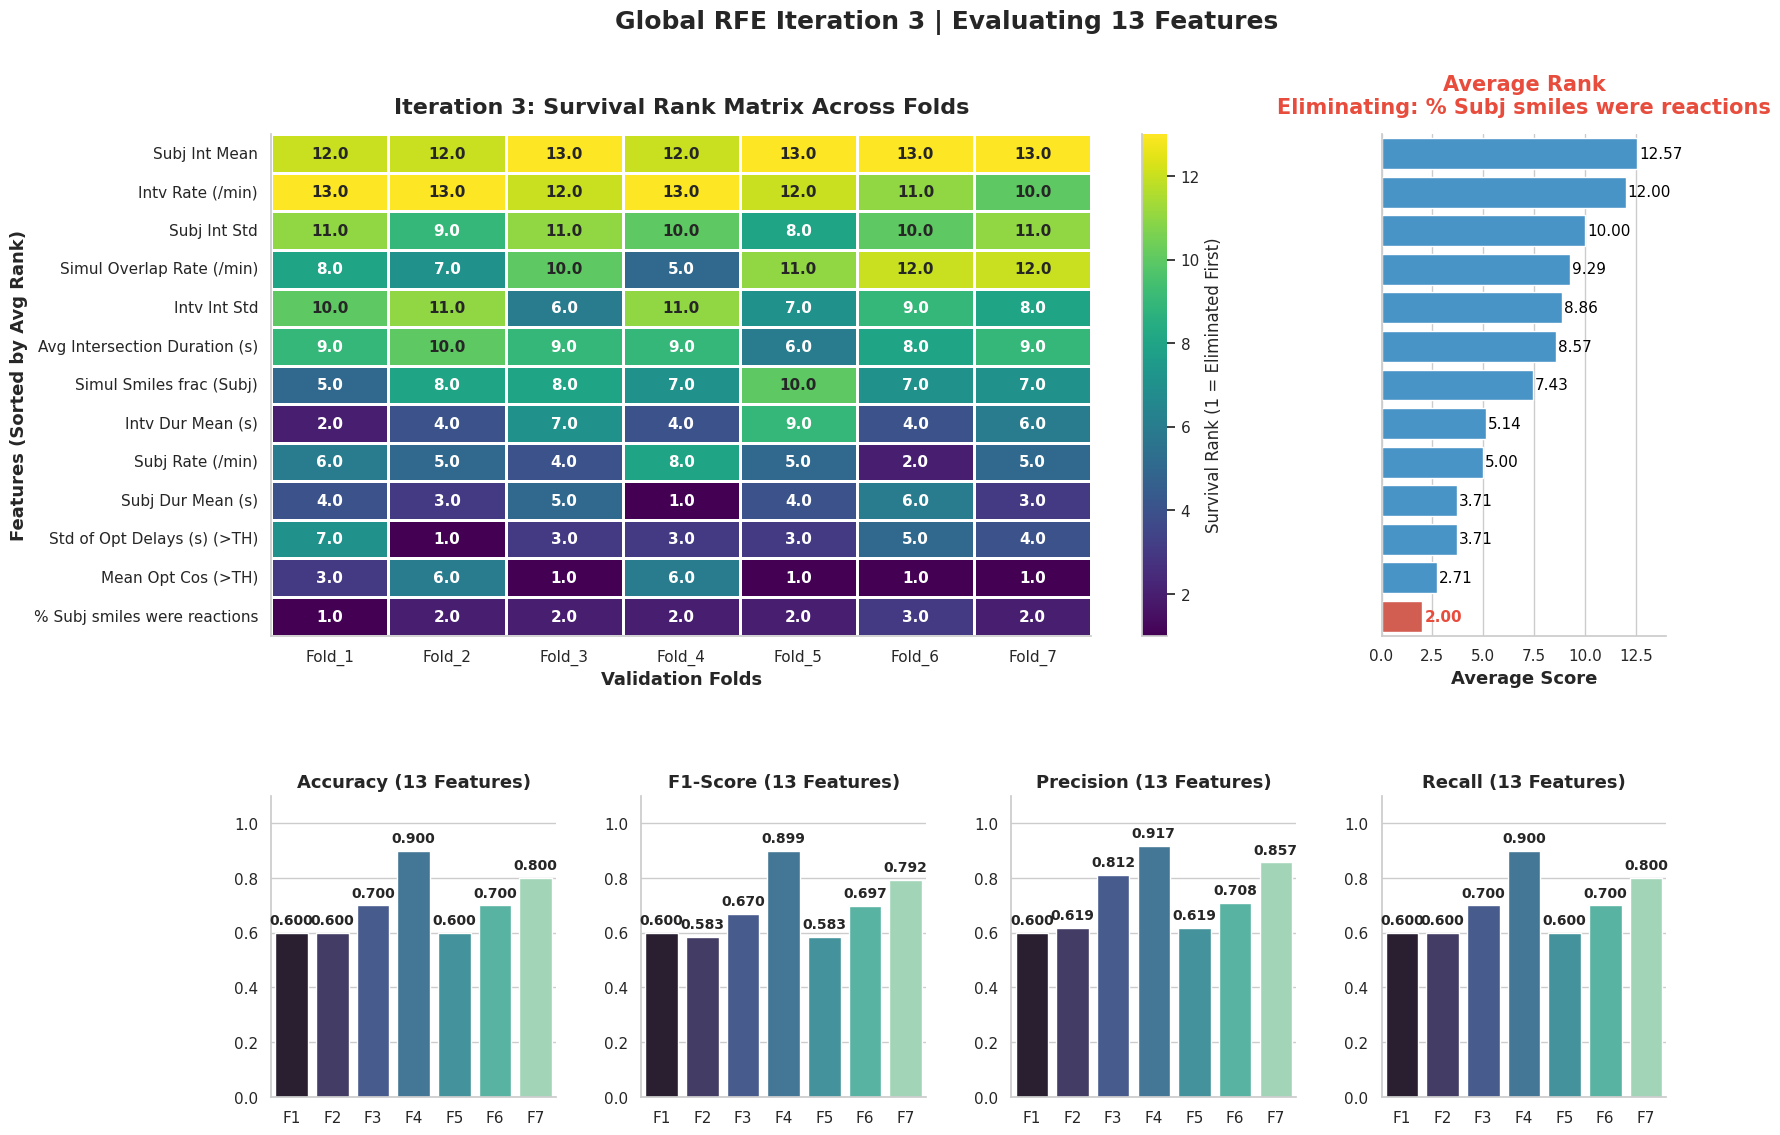

> Eliminating weakest feature: % of Subject's smiles that were reactions (Avg Rank: 2.00)

--- Iteration 4 | Evaluating 12 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

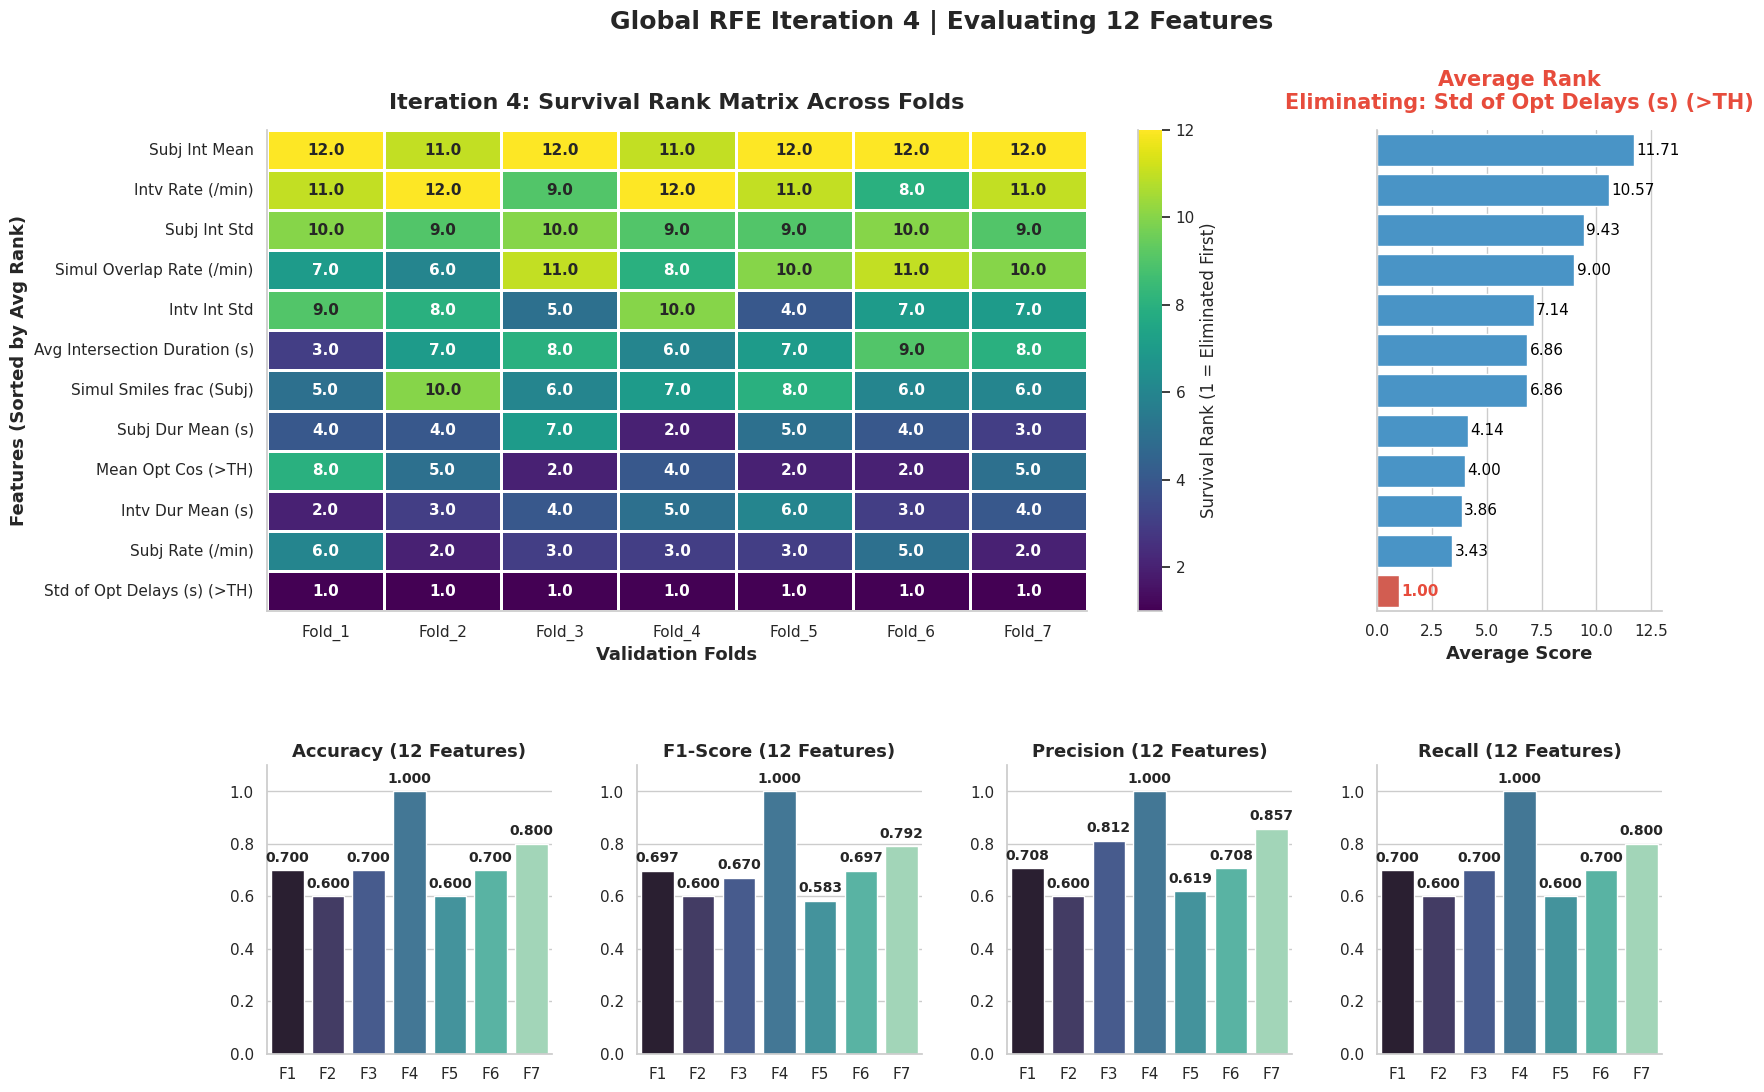

> Eliminating weakest feature: Std of Optimal Delays (s) (>TH) (Avg Rank: 1.00)

--- Iteration 5 | Evaluating 11 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

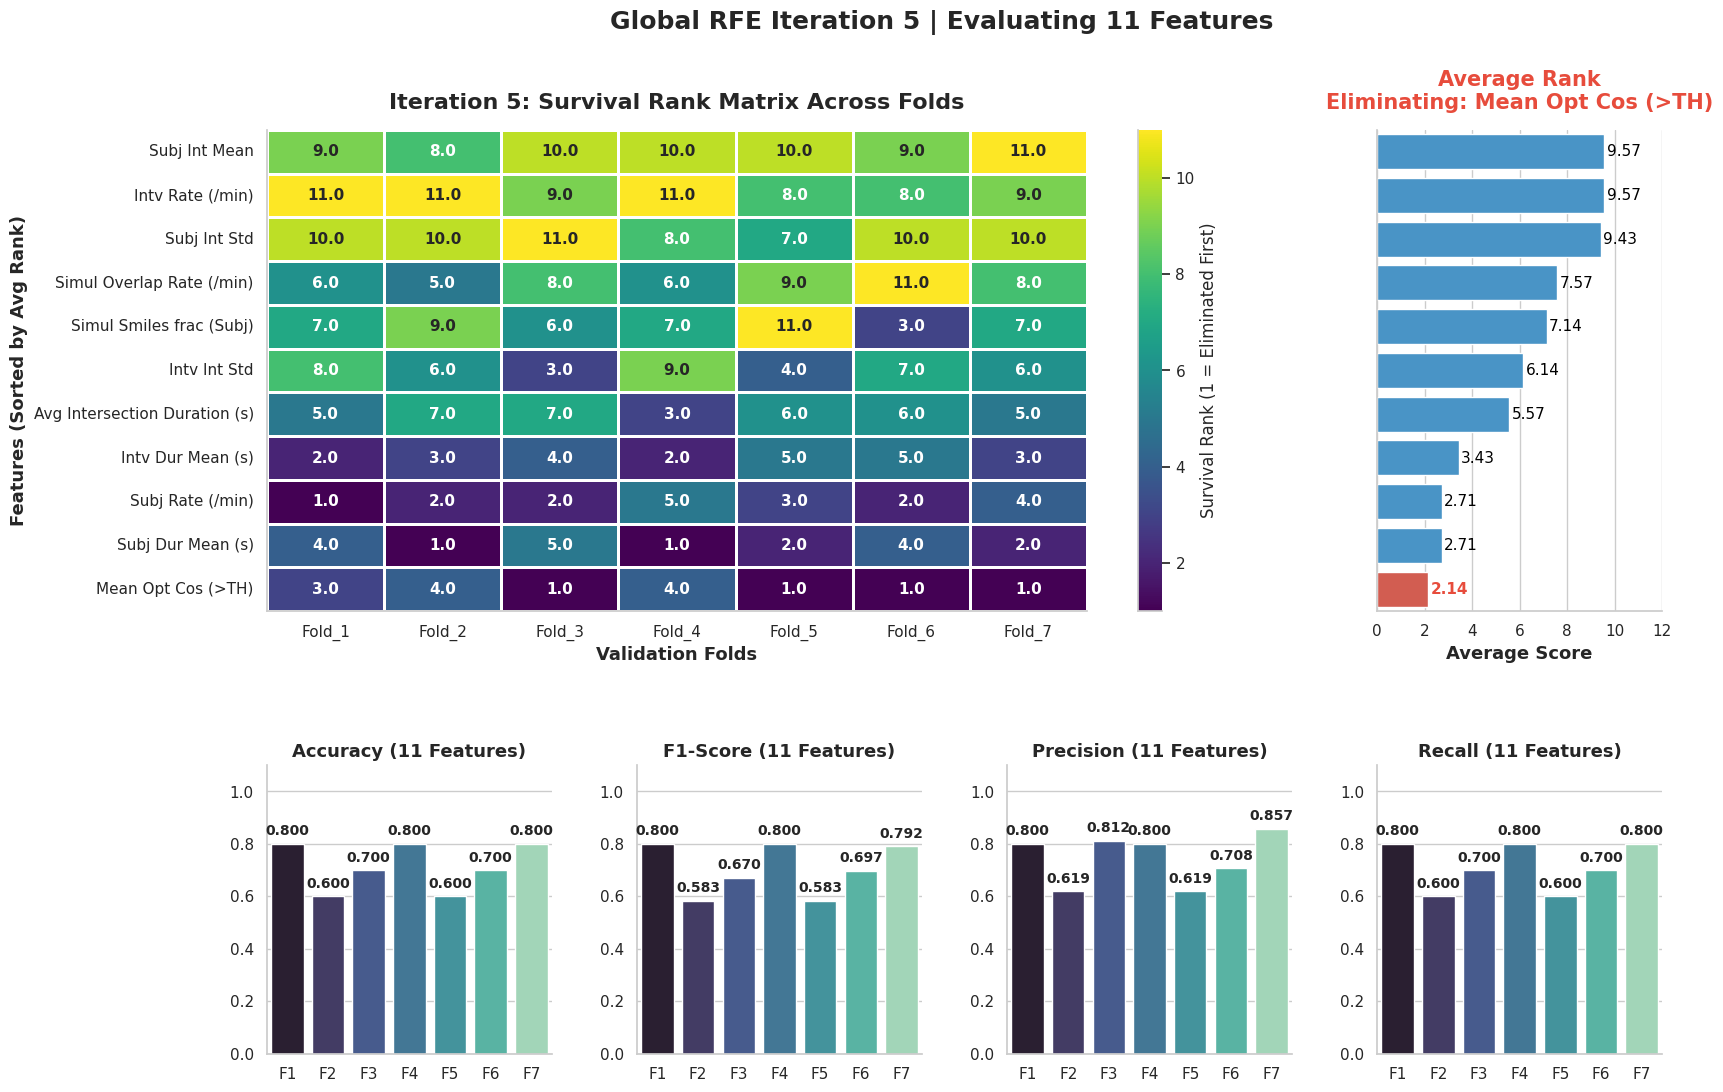

> Eliminating weakest feature: Mean of Optimal Cosines (>TH) (Avg Rank: 2.14)

--- Iteration 6 | Evaluating 10 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

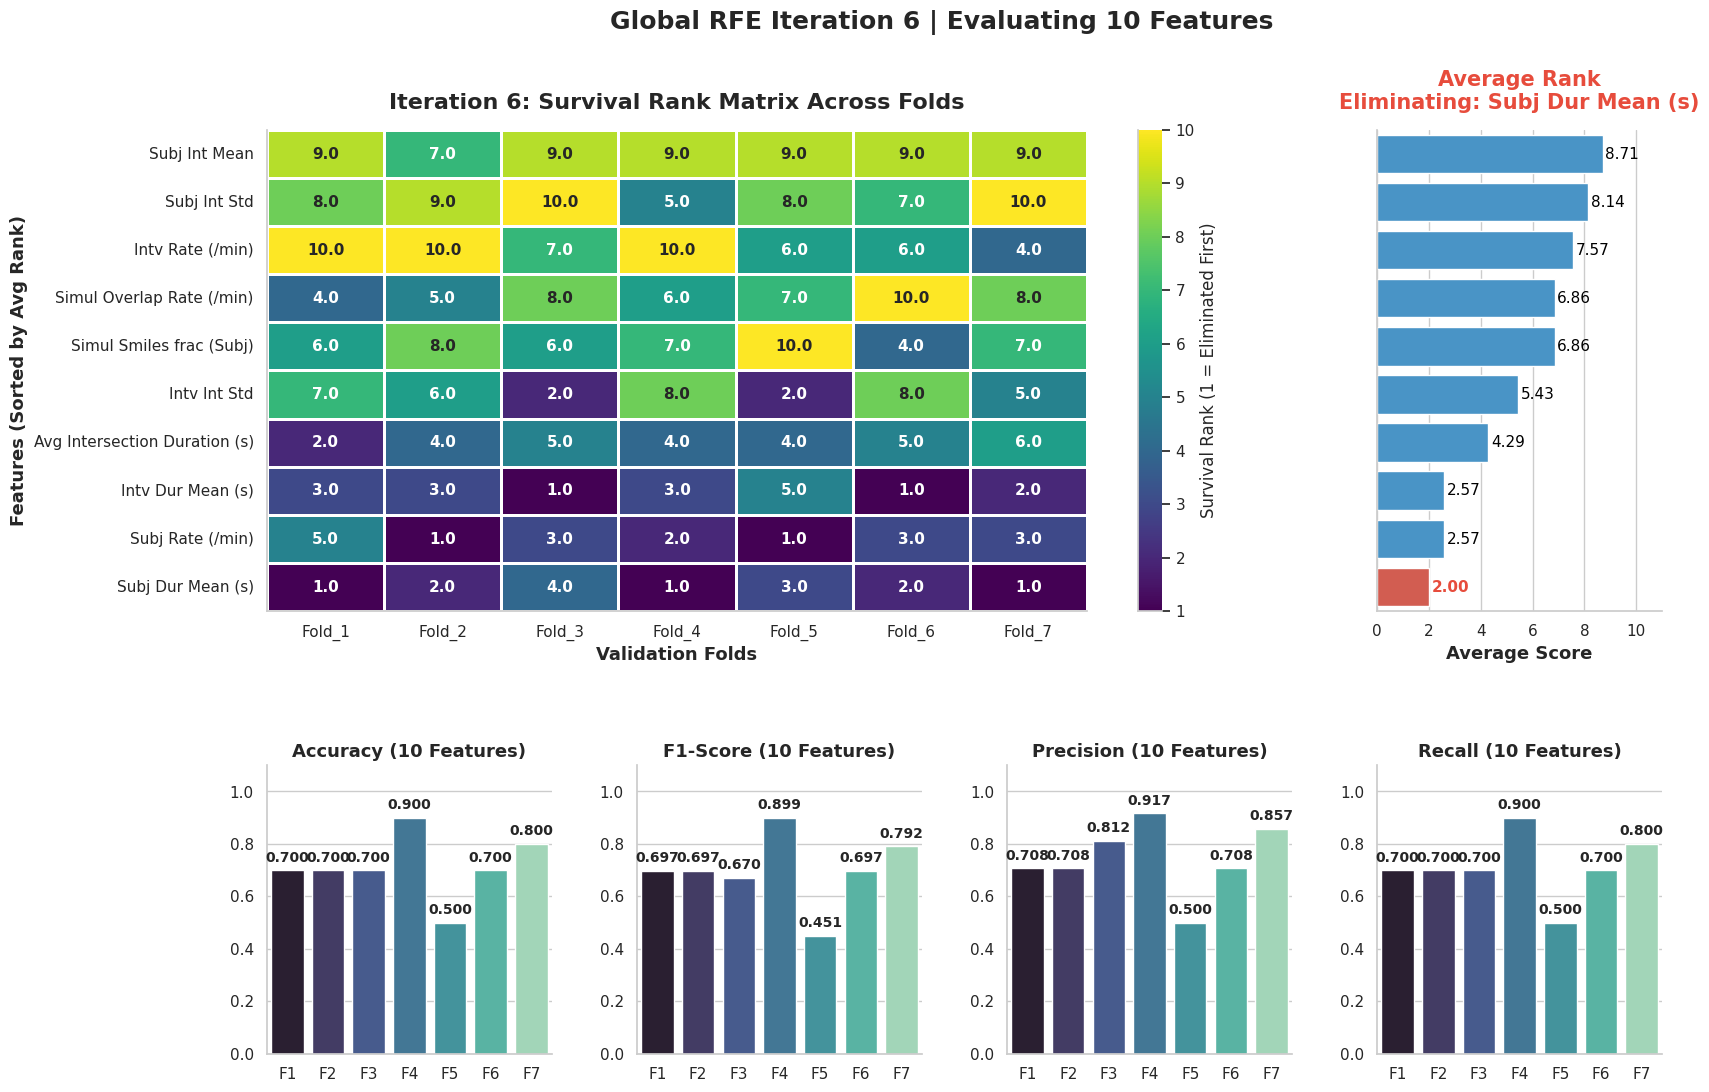

> Eliminating weakest feature: Subject Smile Duration Mean (s) (Avg Rank: 2.00)

--- Iteration 7 | Evaluating 9 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

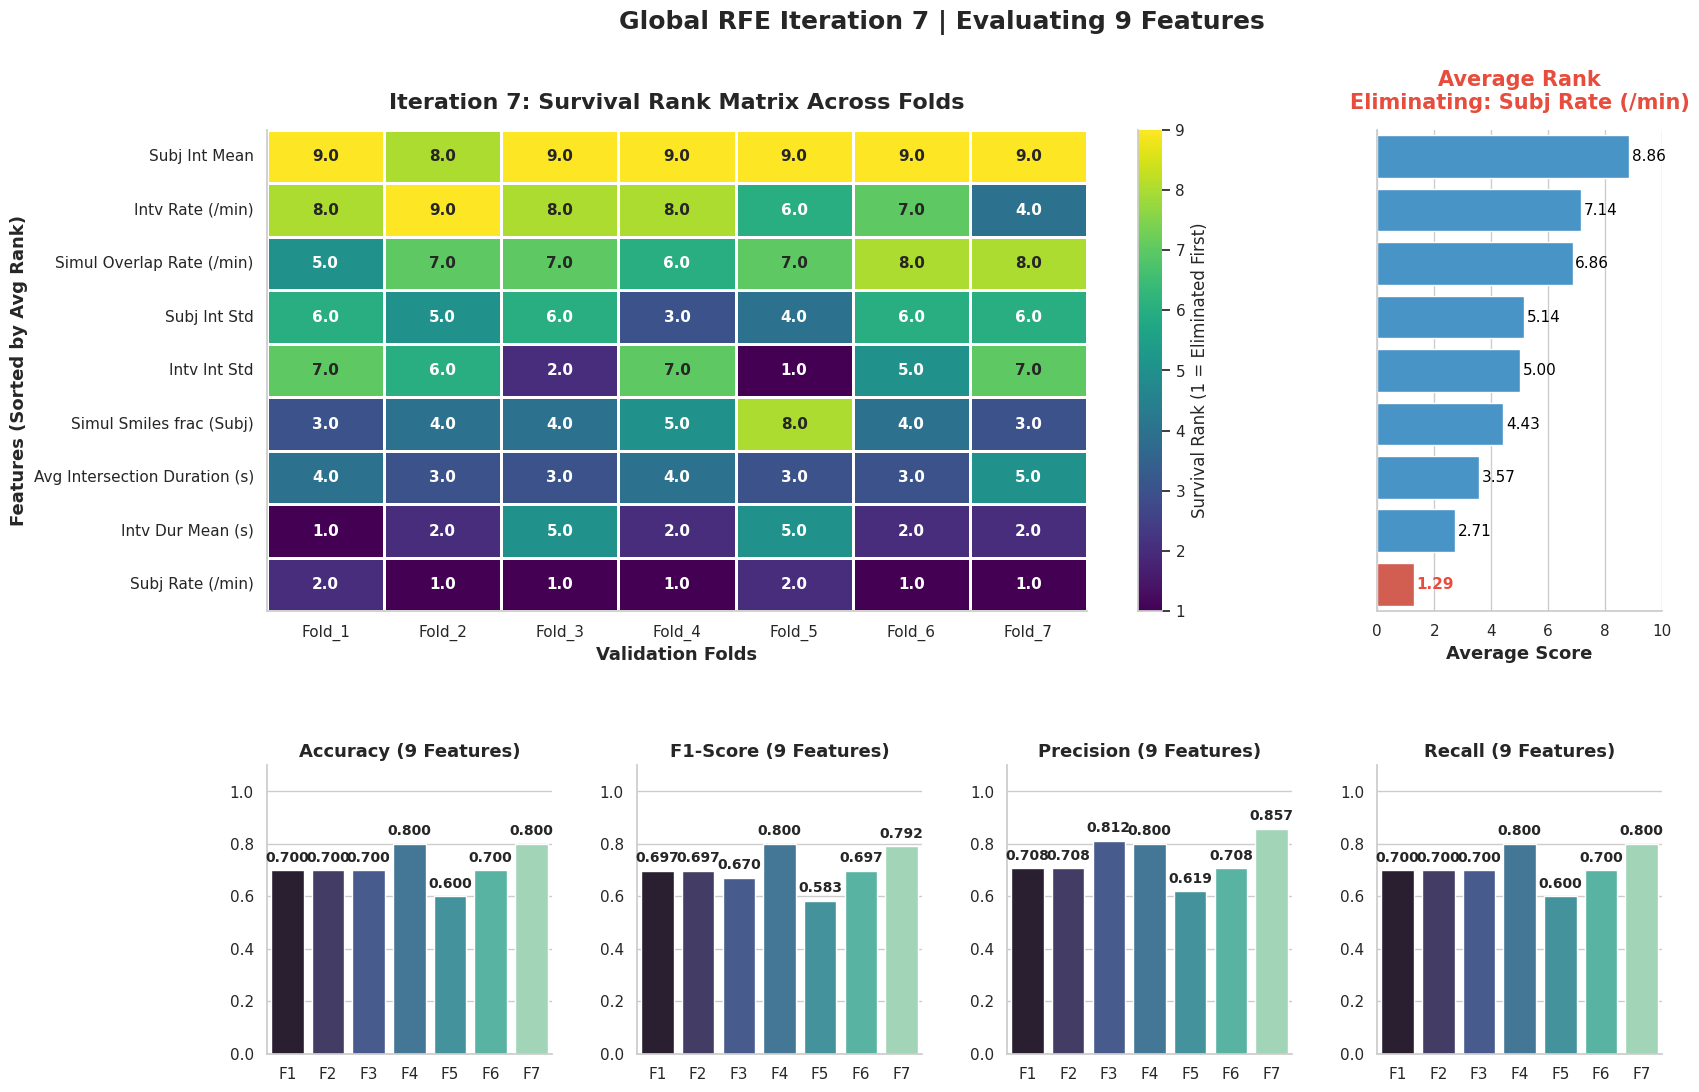

> Eliminating weakest feature: Subject Smile Rate (per min) (Avg Rank: 1.29)

--- Iteration 8 | Evaluating 8 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

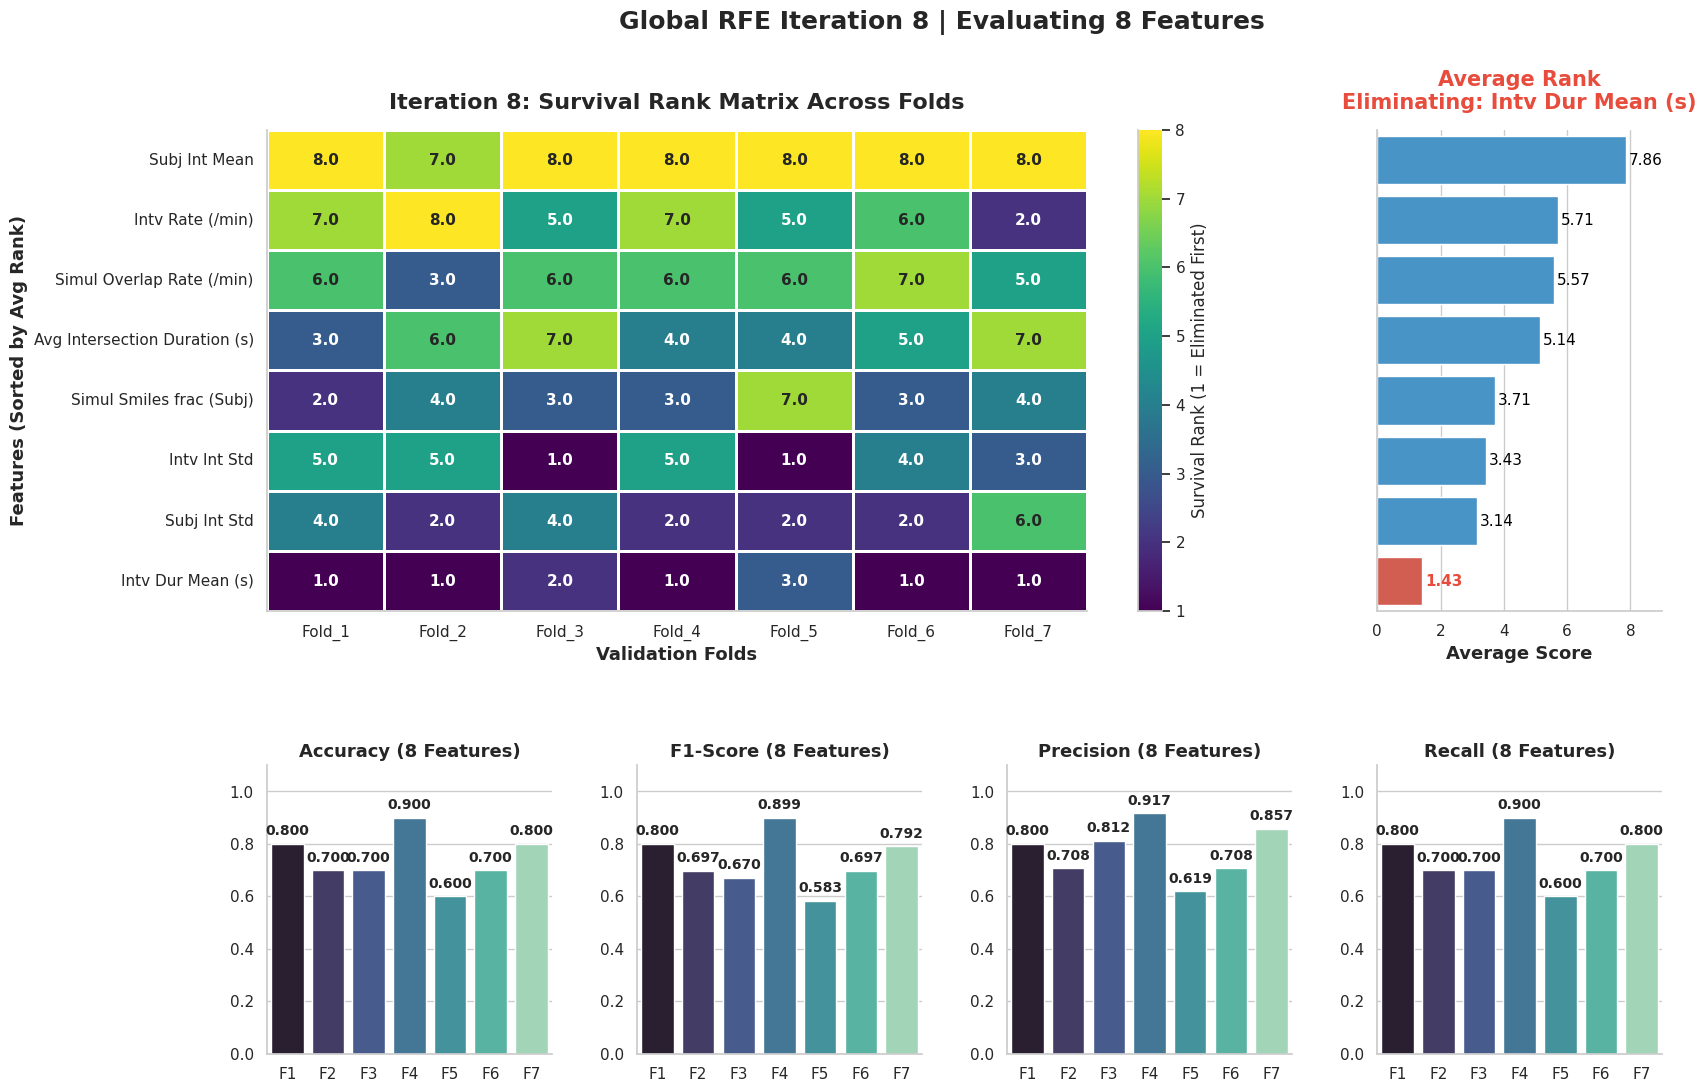

> Eliminating weakest feature: Interviewer Smile Duration Mean (s) (Avg Rank: 1.43)

--- Iteration 9 | Evaluating 7 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

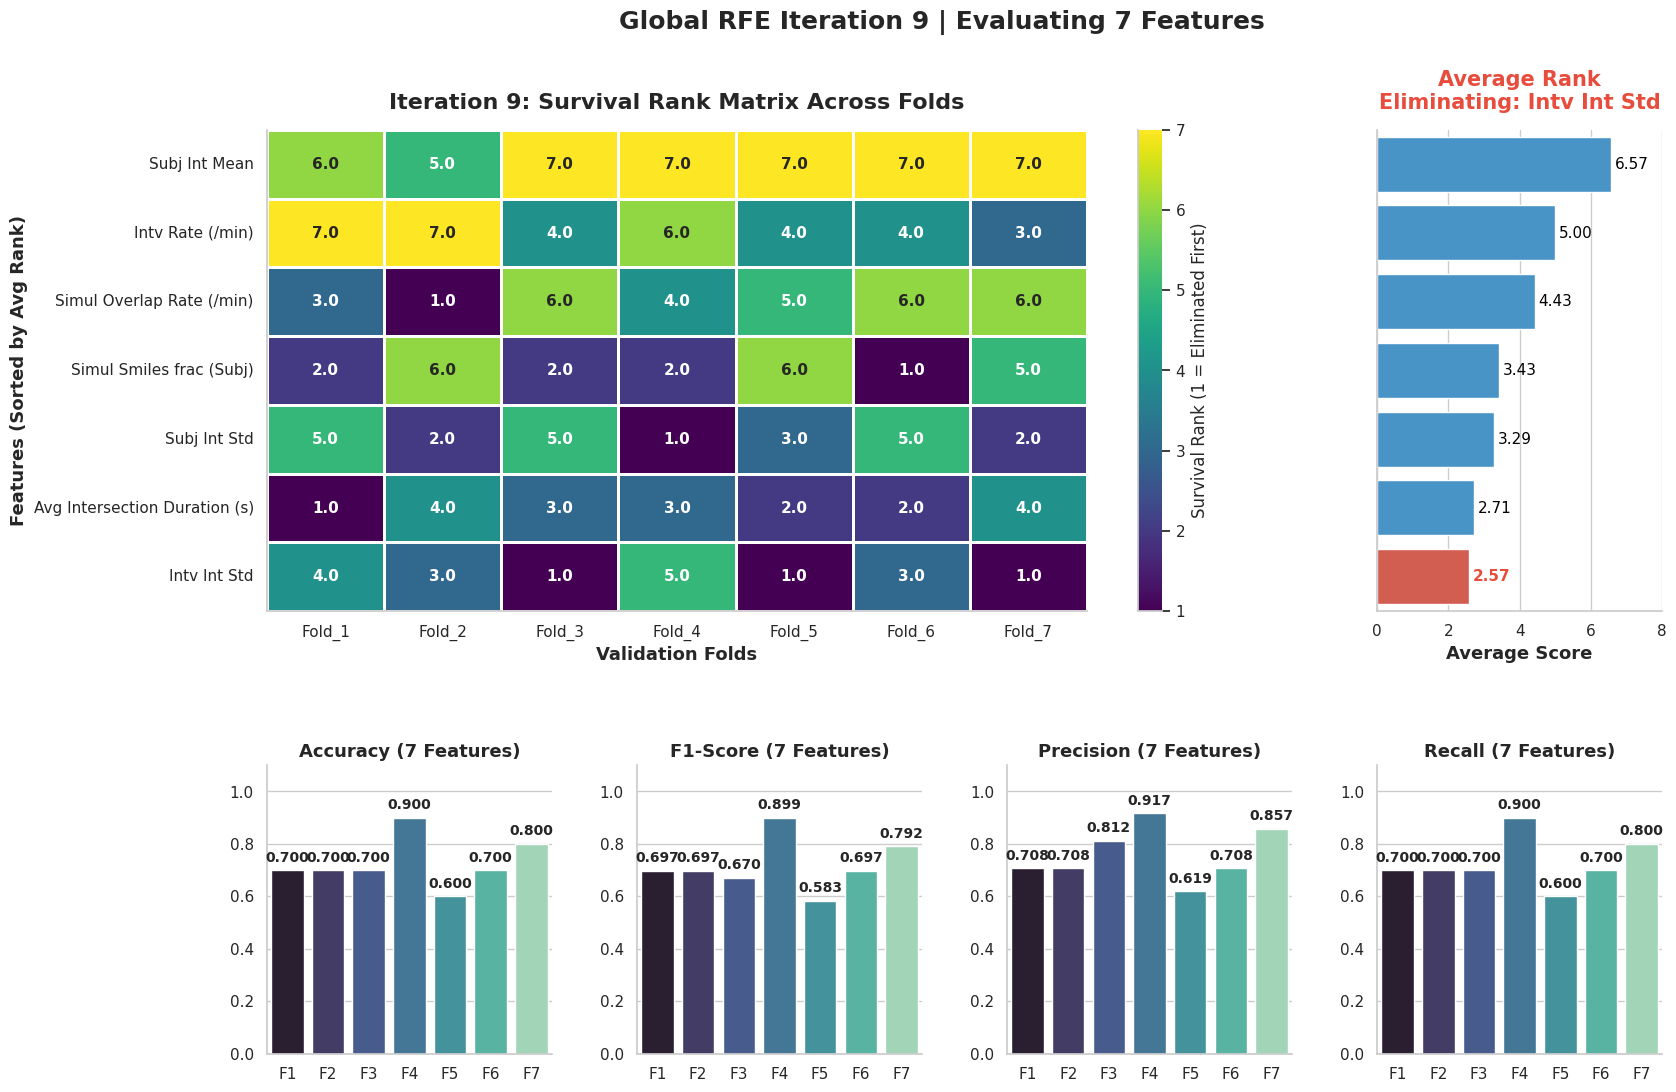

> Eliminating weakest feature: Interviewer Smile Intensity Std (Avg Rank: 2.57)

--- Iteration 10 | Evaluating 6 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

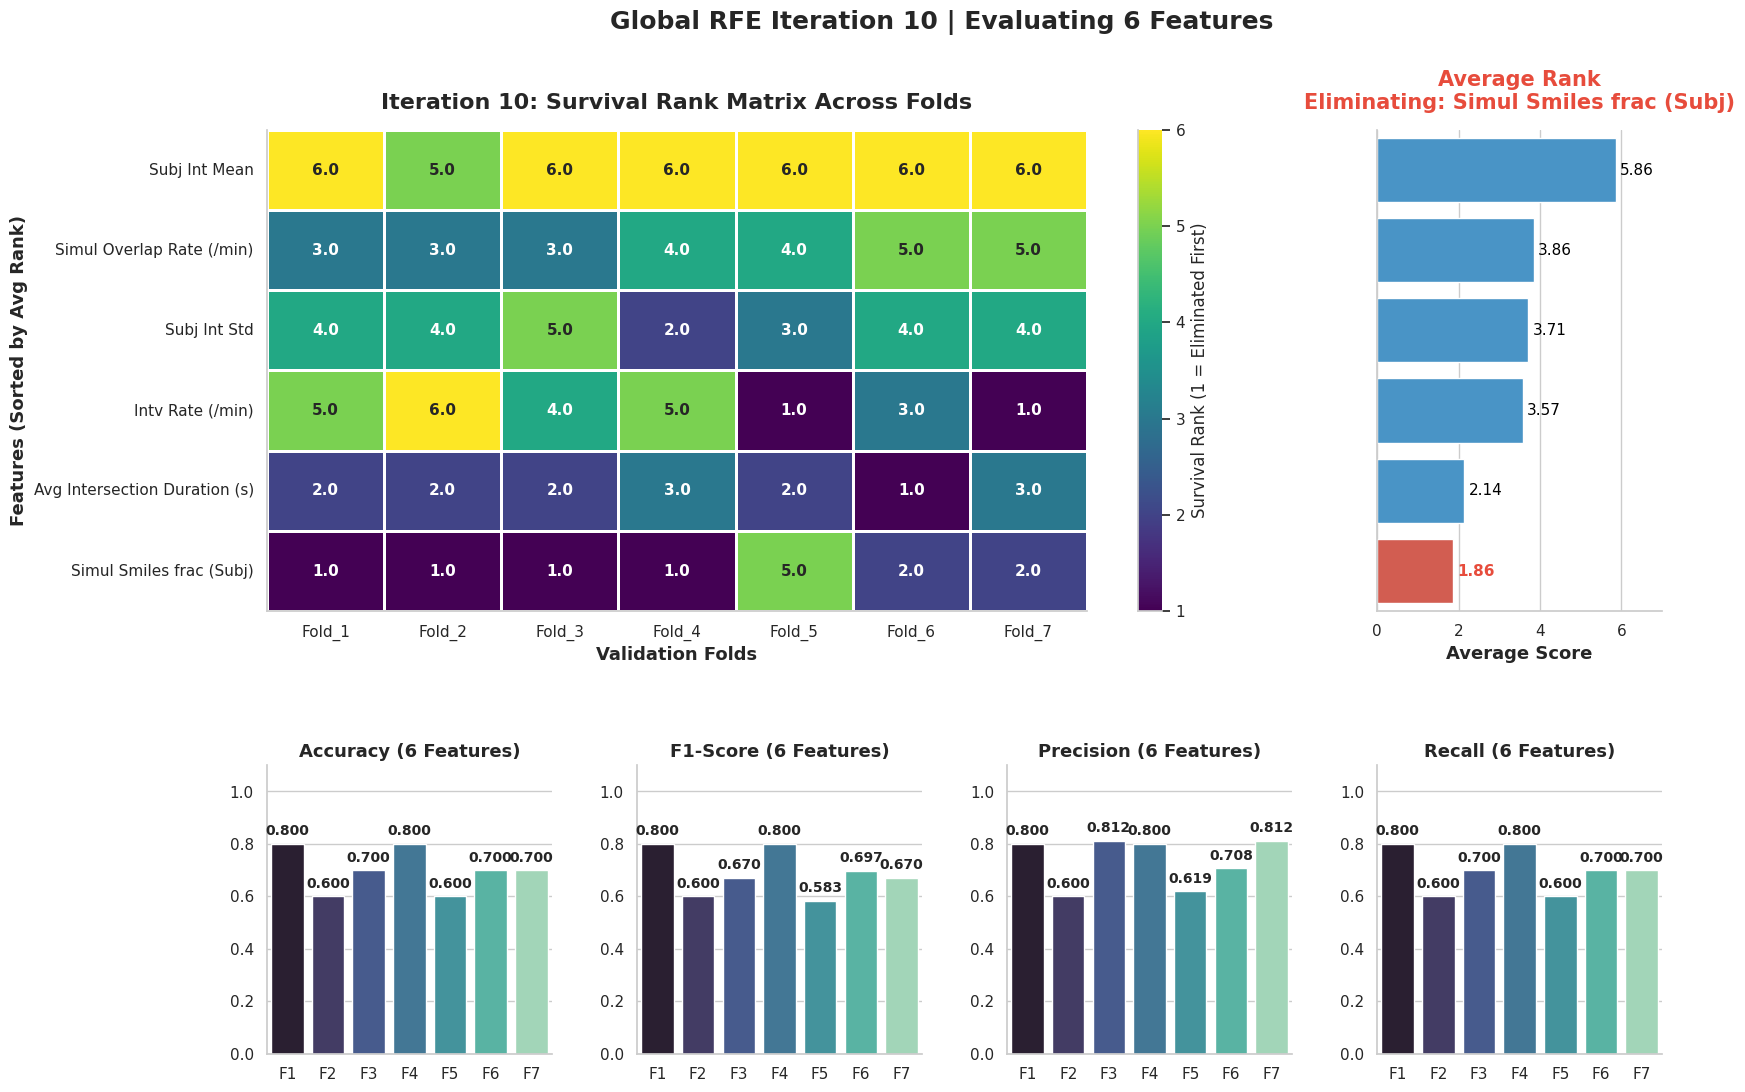

> Eliminating weakest feature: Simultaneous Smiles fraction (Subject) (Avg Rank: 1.86)

--- Iteration 11 | Evaluating 5 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

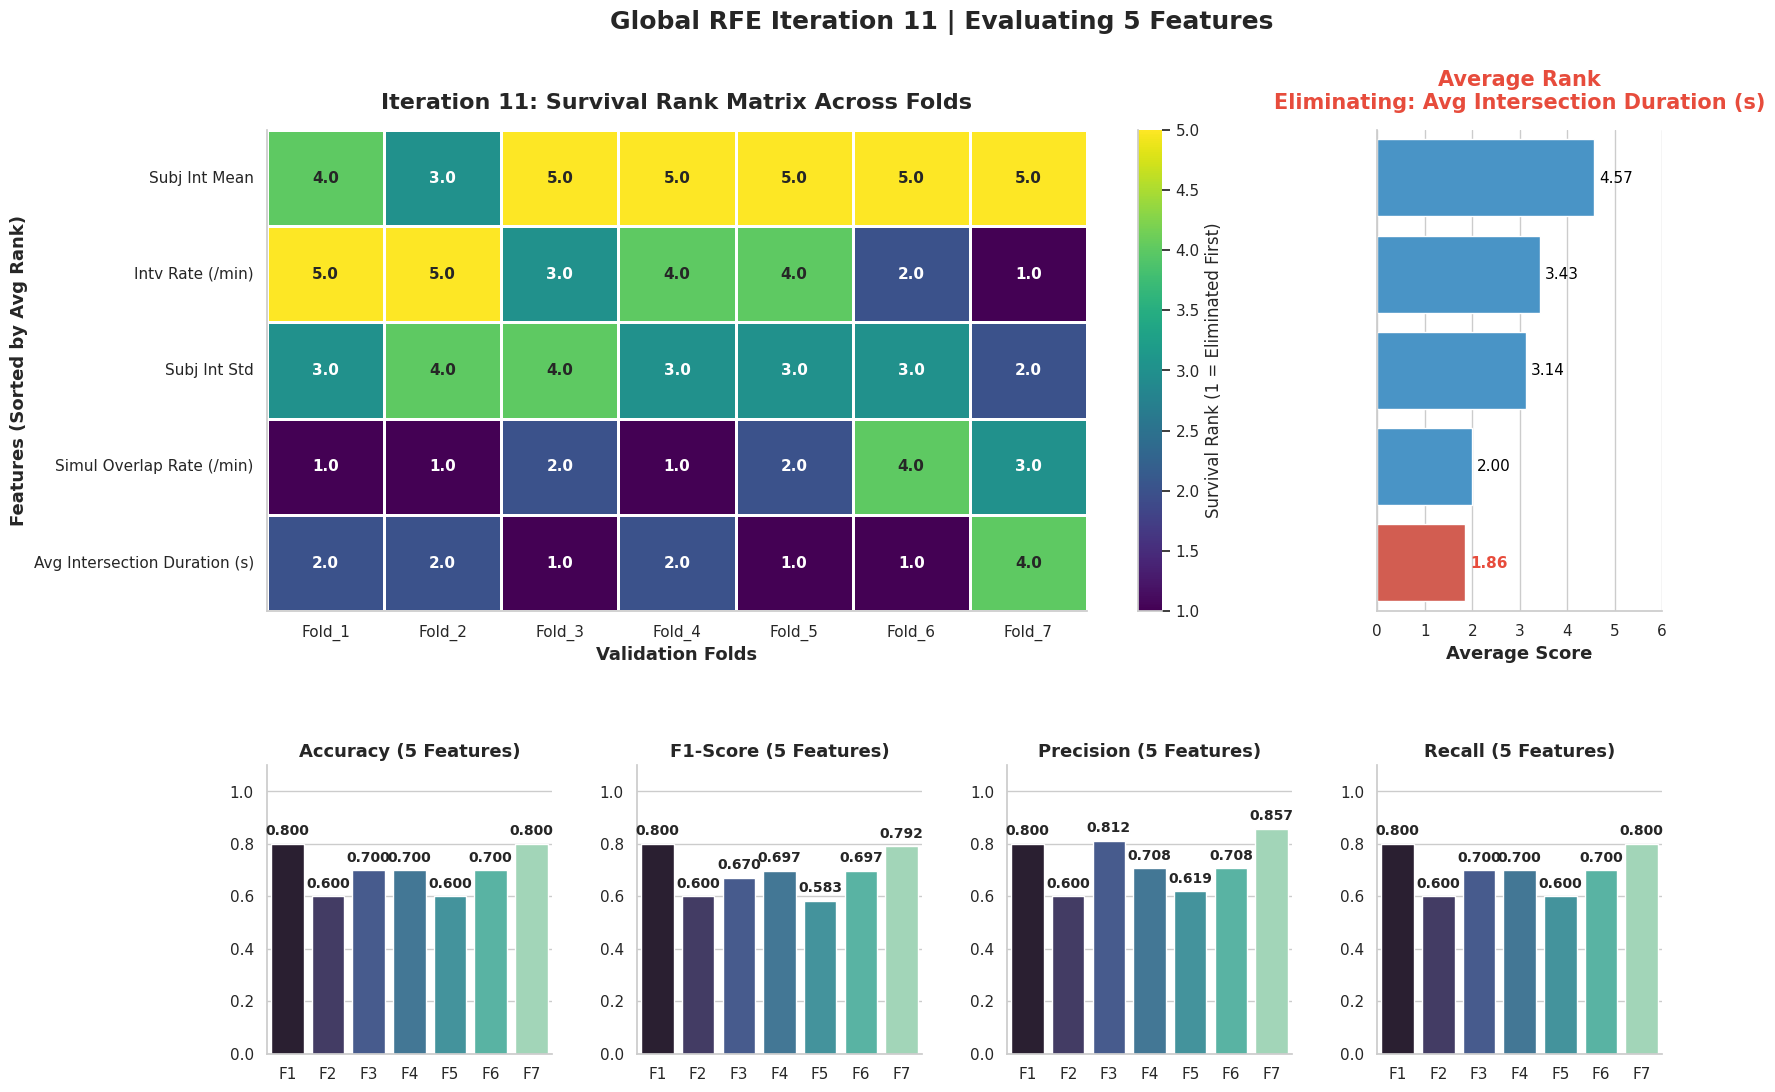

> Eliminating weakest feature: Average Intersection Duration (s) (Avg Rank: 1.86)

--- Iteration 12 | Evaluating 4 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

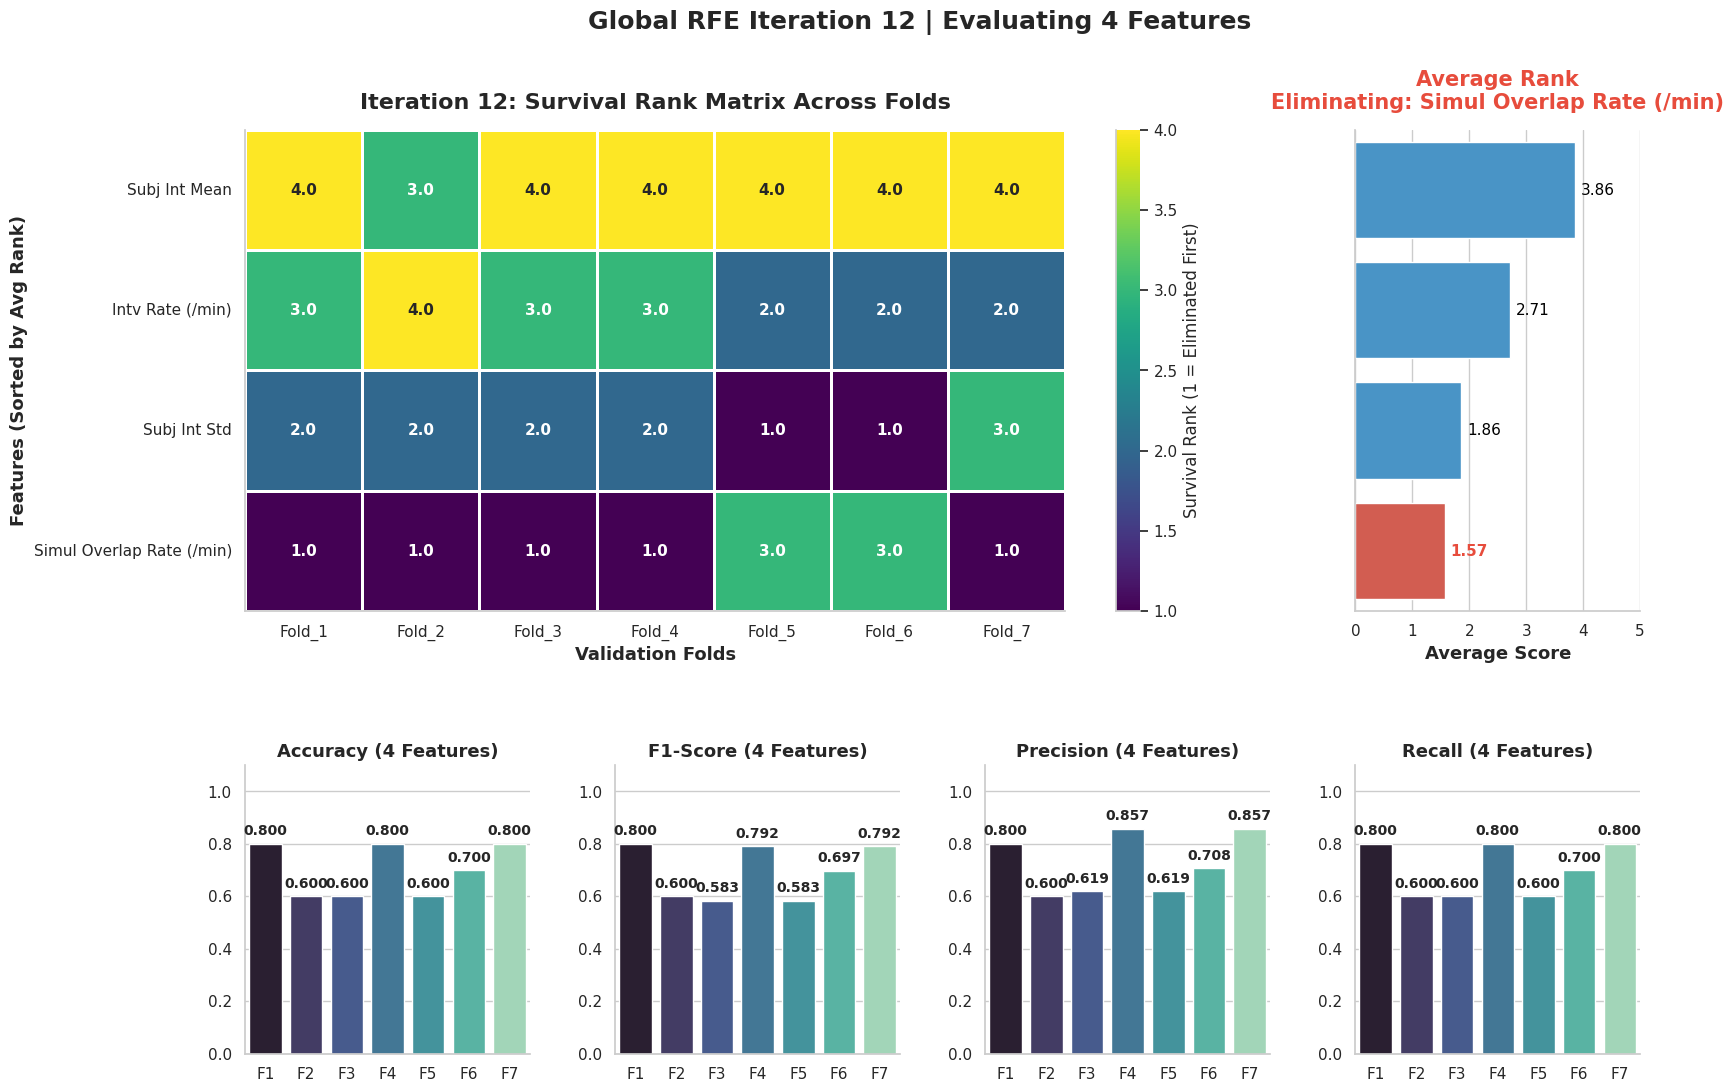

> Eliminating weakest feature: Simultaneous Smiles (Intersections) Rate (per min) (Avg Rank: 1.57)

--- Iteration 13 | Evaluating 3 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

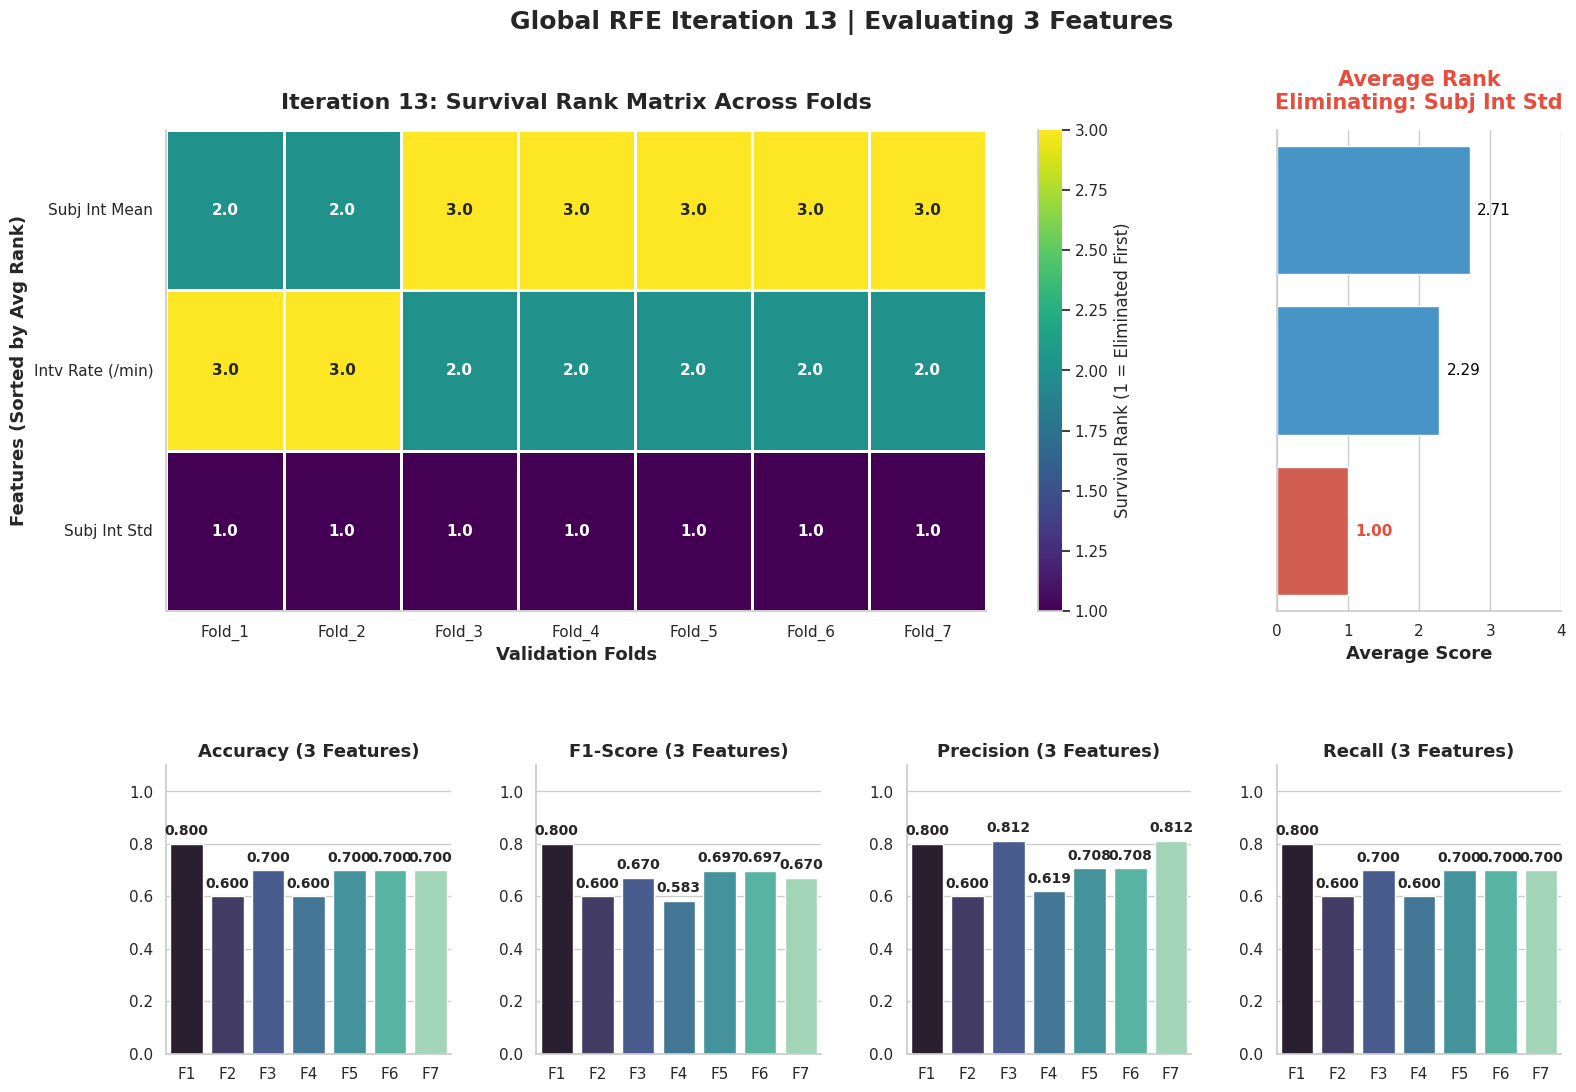

> Eliminating weakest feature: Subject Smile Intensity Std (Avg Rank: 1.00)

--- Iteration 14 | Evaluating 2 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

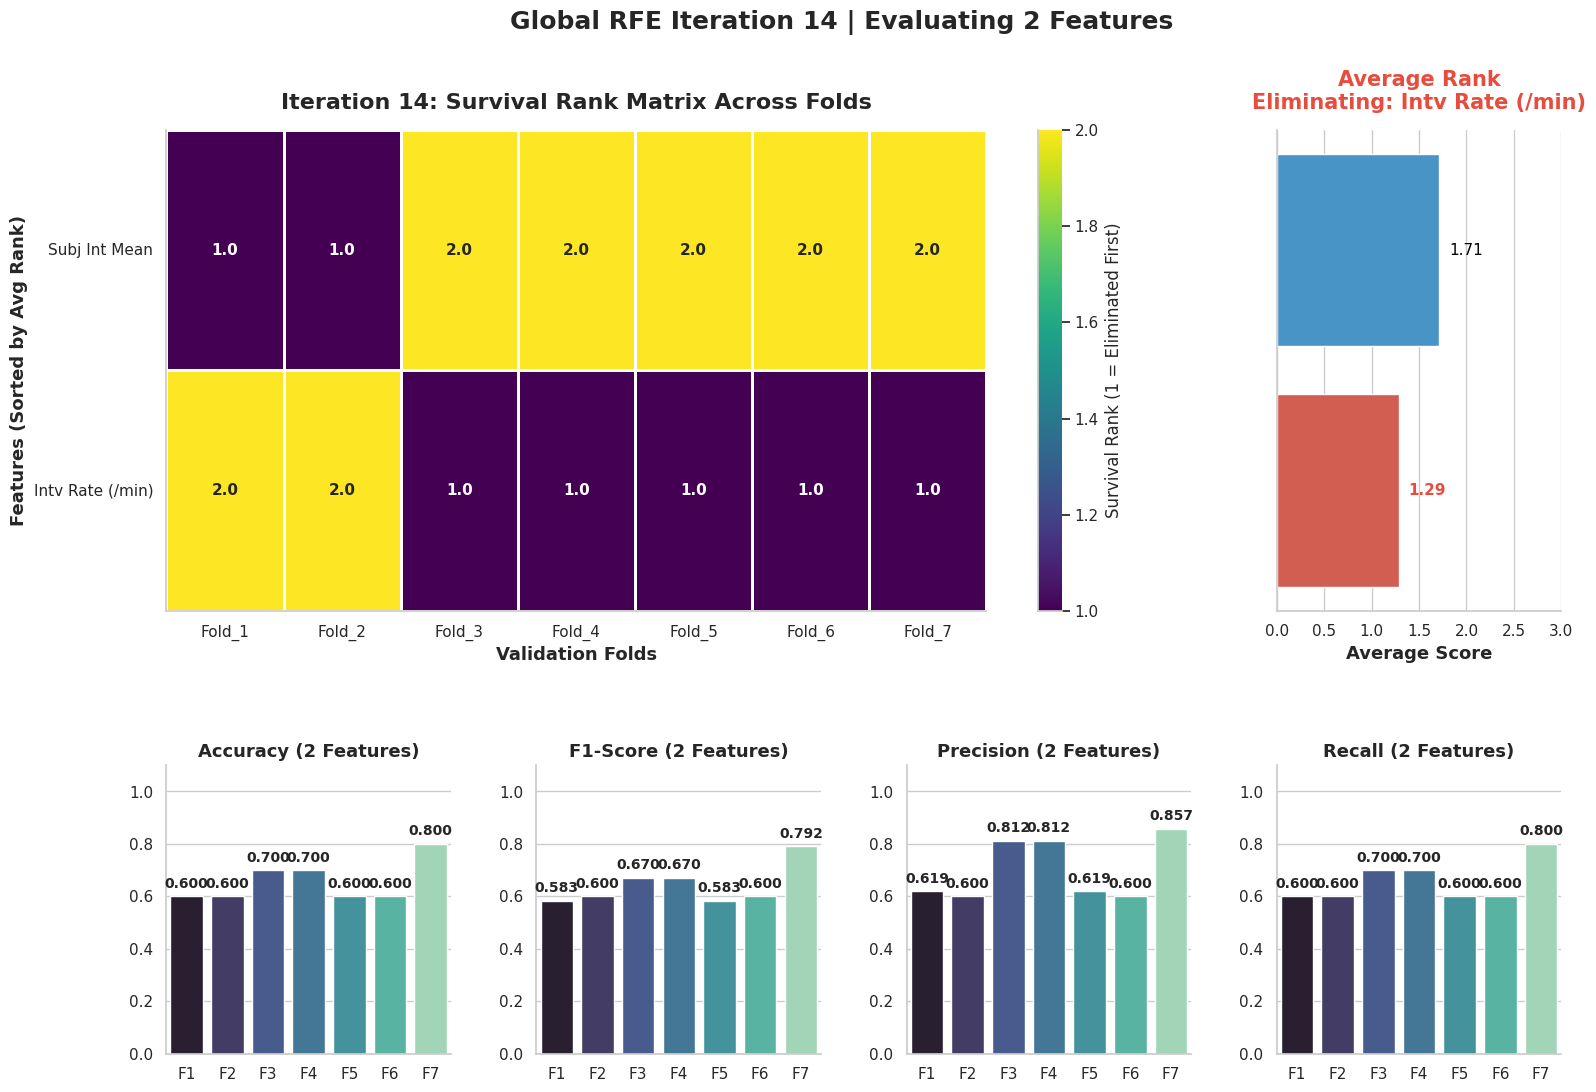

> Eliminating weakest feature: Interviewer Smile Rate (per min) (Avg Rank: 1.29)

RFE COMPLETE. FINAL SURVIVING FEATURE: Subject Smile Intensity Mean

Elimination History:
    Iteration                                    Dropped_Feature  \
0           1                   Interviewer Smile Intensity Mean   
1           2      % of Interviewer's smiles that got a reaction   
2           3          % of Subject's smiles that were reactions   
3           4                    Std of Optimal Delays (s) (>TH)   
4           5                      Mean of Optimal Cosines (>TH)   
5           6                    Subject Smile Duration Mean (s)   
6           7                       Subject Smile Rate (per min)   
7           8                Interviewer Smile Duration Mean (s)   
8           9                    Interviewer Smile Intensity Std   
9          10             Simultaneous Smiles fraction (Subject)   
10         11                  Average Intersection Duration (s)   
11         1

In [31]:
if __name__ == "__main__":
    # ... (Assuming your previous code ran and produced 'fold_best_features') ...
    
    # 1. Create a union of all the best features found across the 7 folds
    all_best_features_set = set()
    for i in range(1, 8):
        all_best_features_set = all_best_features_set.union(fold_best_features[f'Fold_{i}'])
        
    initial_features_list = list(all_best_features_set)
    df = pd.read_csv(DATA_PATH)
    X_scaled, y = prepare_data(df)
    
    print(f"Total Unique Best Features Extracted: {len(initial_features_list)}")
    
    # 2. Run the Global Consensus RFE
    final_survivor, rfe_history_df = consensus_global_rfe_rf(X=X_scaled, y=y, initial_features=initial_features_list, K_FOLDS=7)
    
    # Optional: Display the history of accuracy drops as features were eliminated
    print("\nElimination History:")
    print(rfe_history_df)

# Method2

In [35]:
all_features_set = ["Interviewer Smile Rate (per min)",
"Subject Smile Rate (per min)",
"Interviewer Smile Duration Mean (s)",
"Interviewer Smile Duration Std (s)",
"Subject Smile Duration Mean (s)",
"Interviewer Smile Intensity Mean",
"Interviewer Smile Intensity Std",
"Subject Smile Intensity Mean",
"Subject Smile Intensity Std",
"Simultaneous Smiles fraction (Subject)",
"Simultaneous Smiles (Intersections) Rate (per min)",
"Average Intersection Duration (s)",
"Average Delay of Reaction (s)",
"Std Dev of Delay of Reaction (s)",
"% of Subject's smiles that were reactions",
"% of Interviewer's smiles that got a reaction",
"Mean of Optimal Cosines (>TH)",
"Std of Optimal Cosines (>TH)",
"Std of Optimal Delays (s) (>TH)",
"Gender_M",
]

Total Unique Best Features Extracted: 20

STARTING CONSENSUS GLOBAL RFE (Random Forest | 20 Initial Features)

--- Iteration 1 | Evaluating 20 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

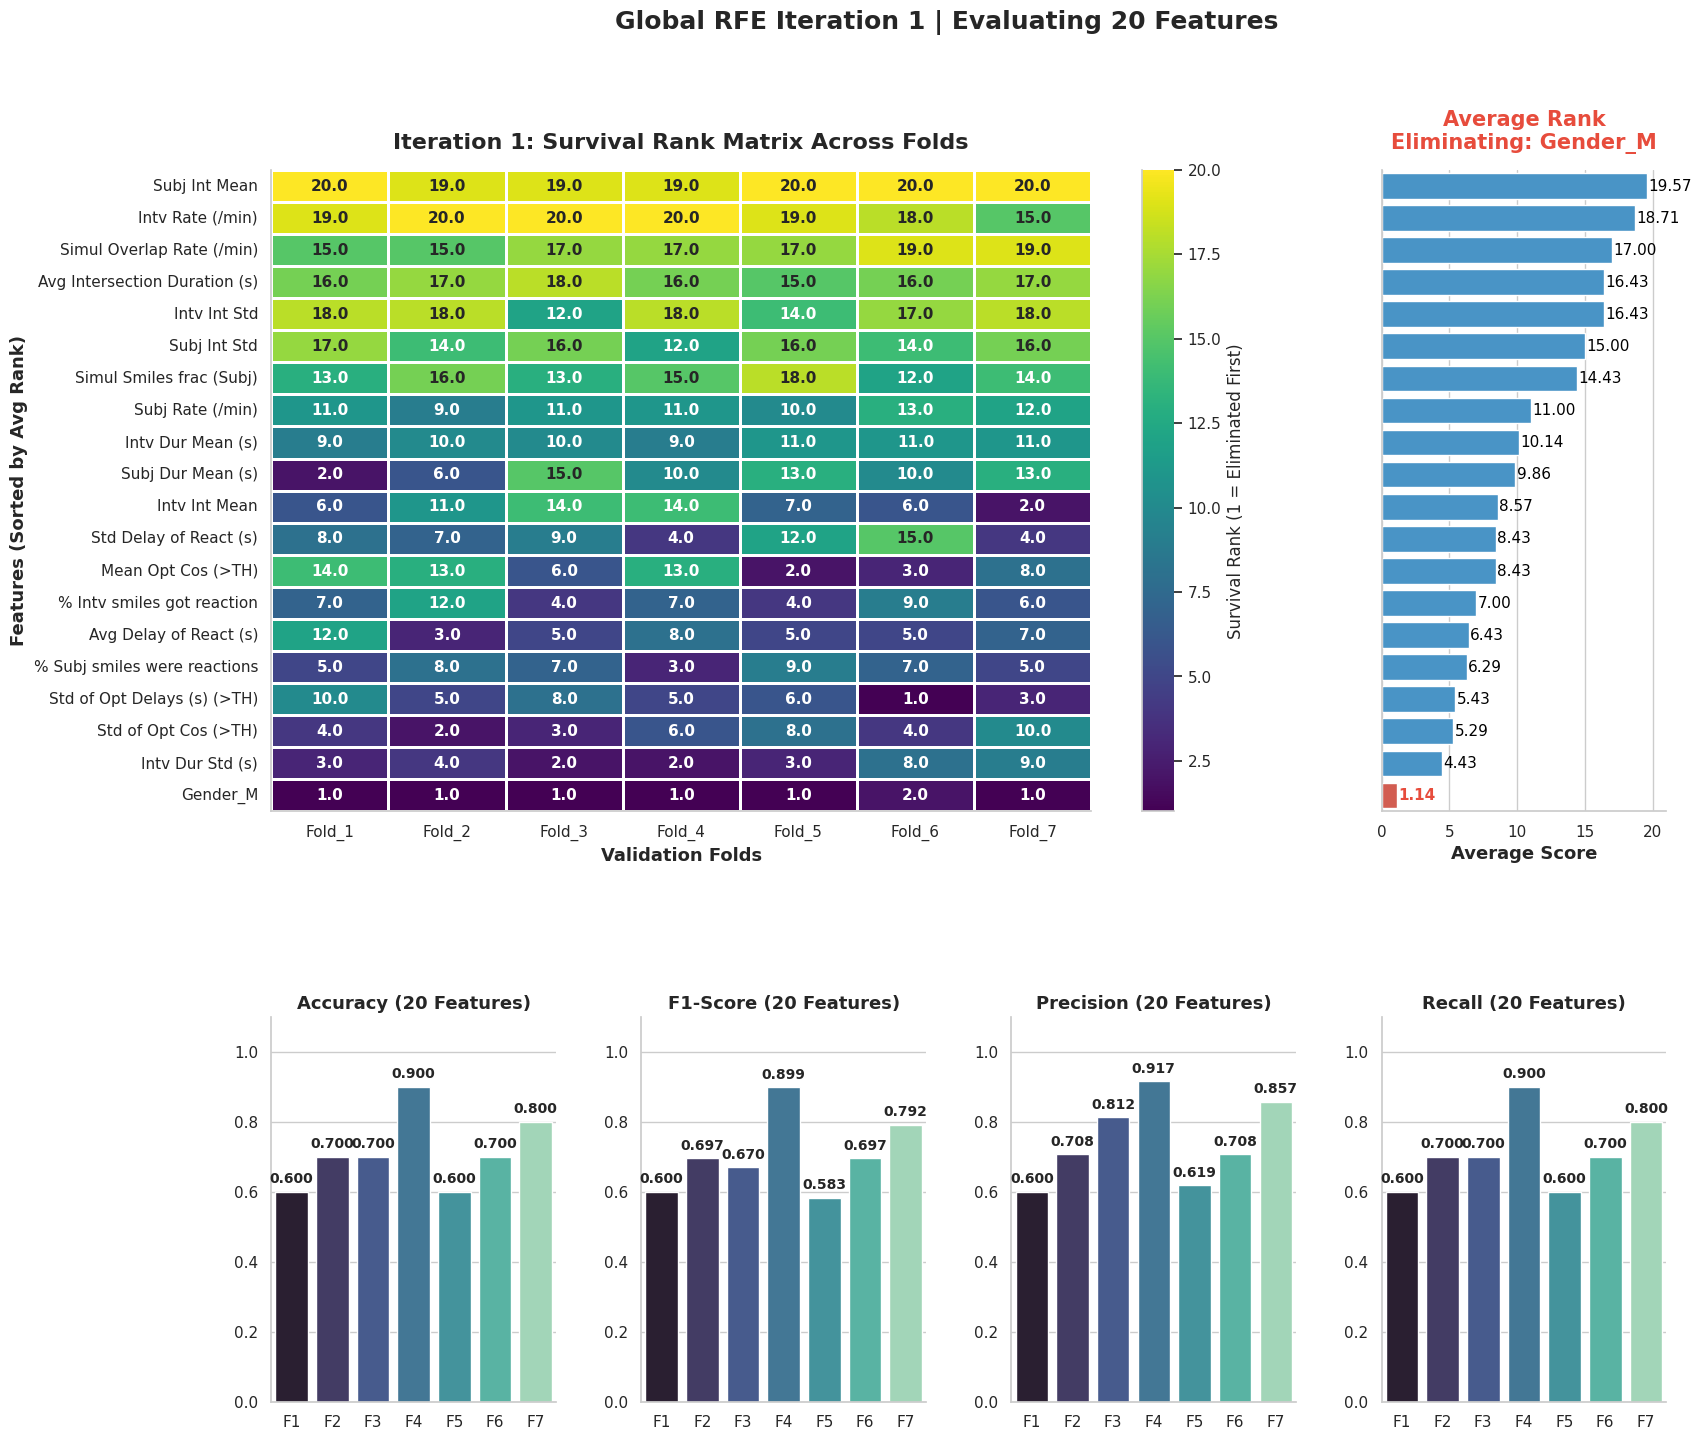

> Eliminating weakest feature: Gender_M (Avg Rank: 1.14)

--- Iteration 2 | Evaluating 19 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

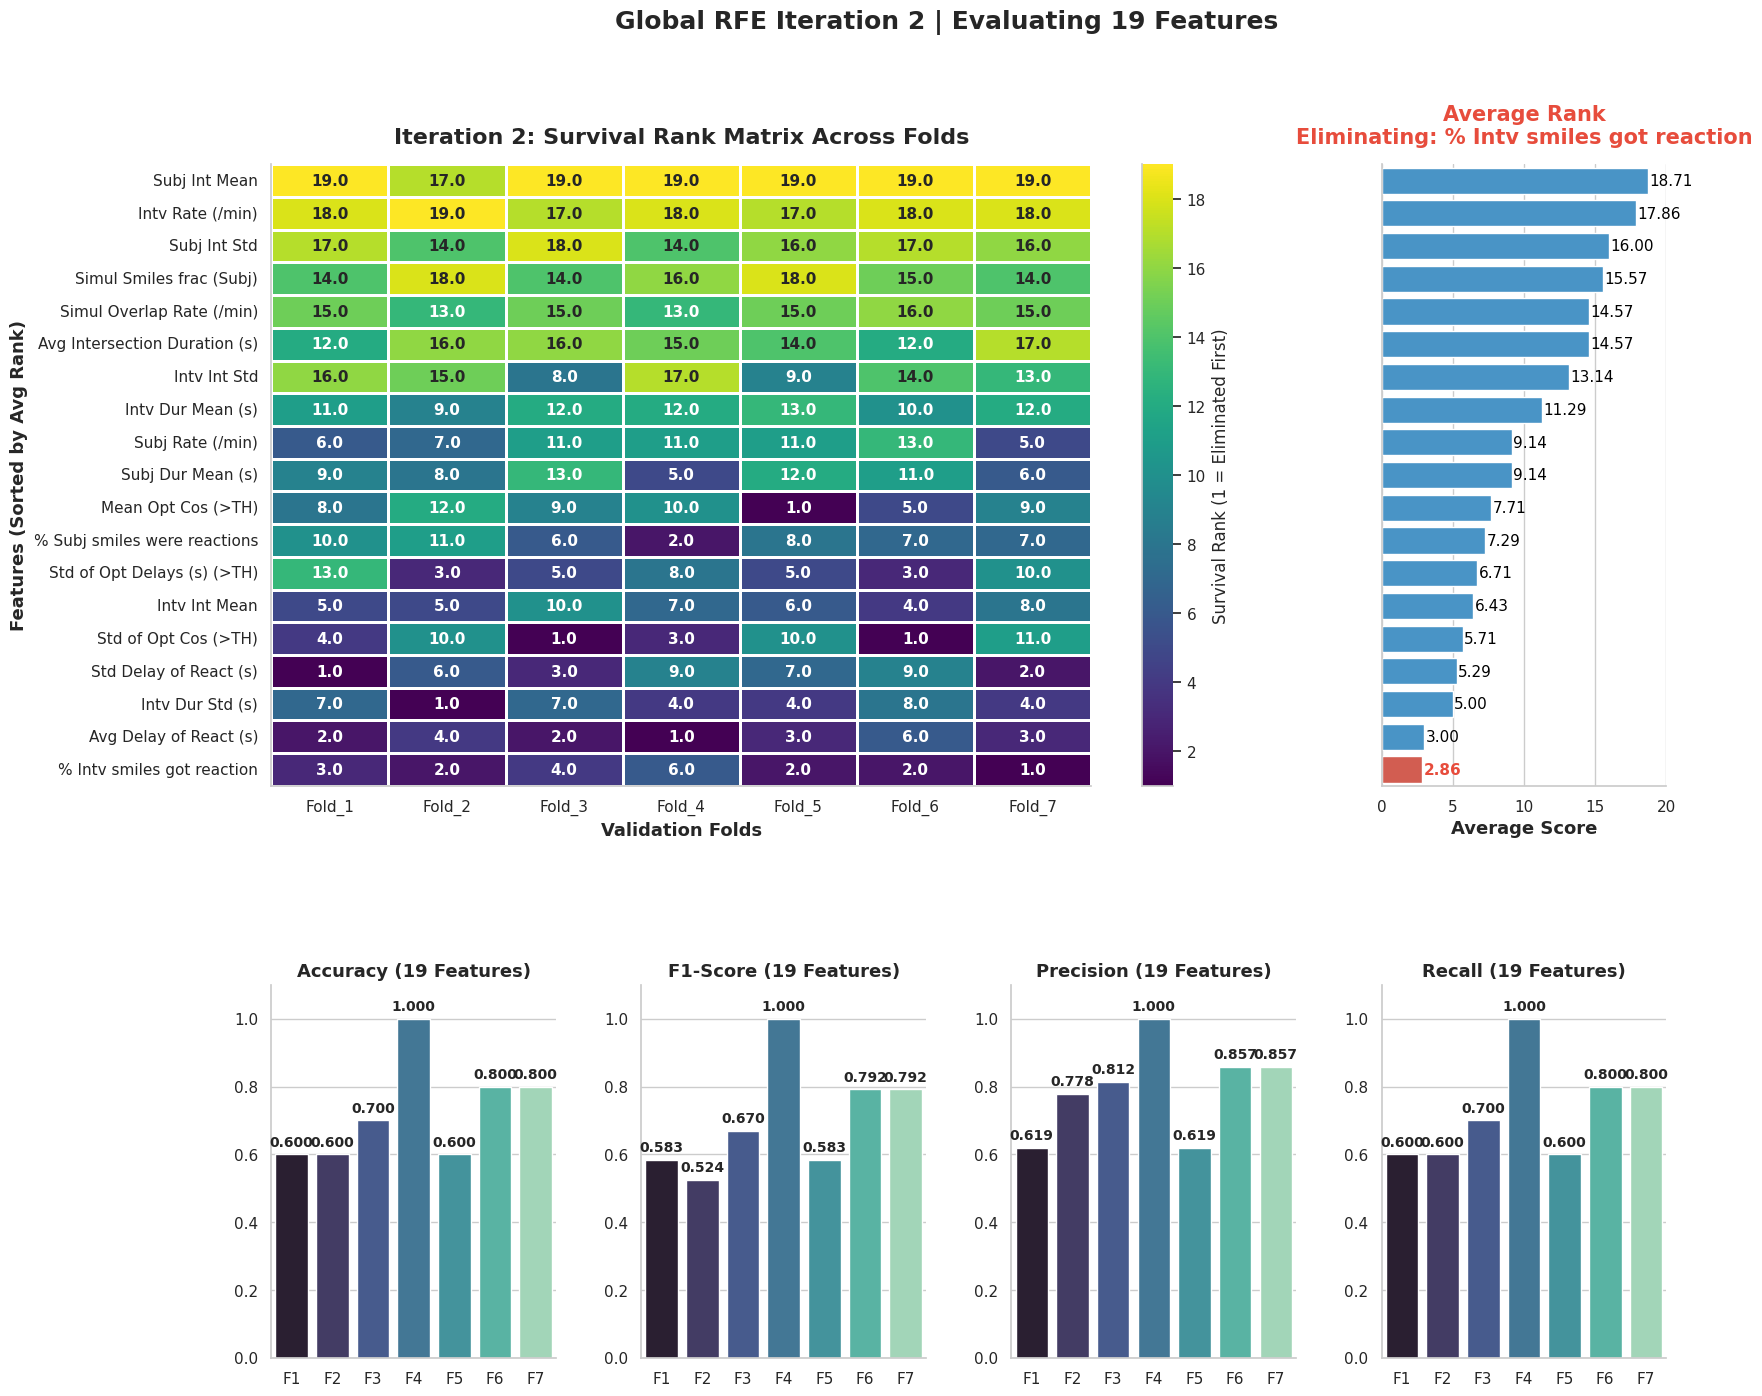

> Eliminating weakest feature: % of Interviewer's smiles that got a reaction (Avg Rank: 2.86)

--- Iteration 3 | Evaluating 18 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

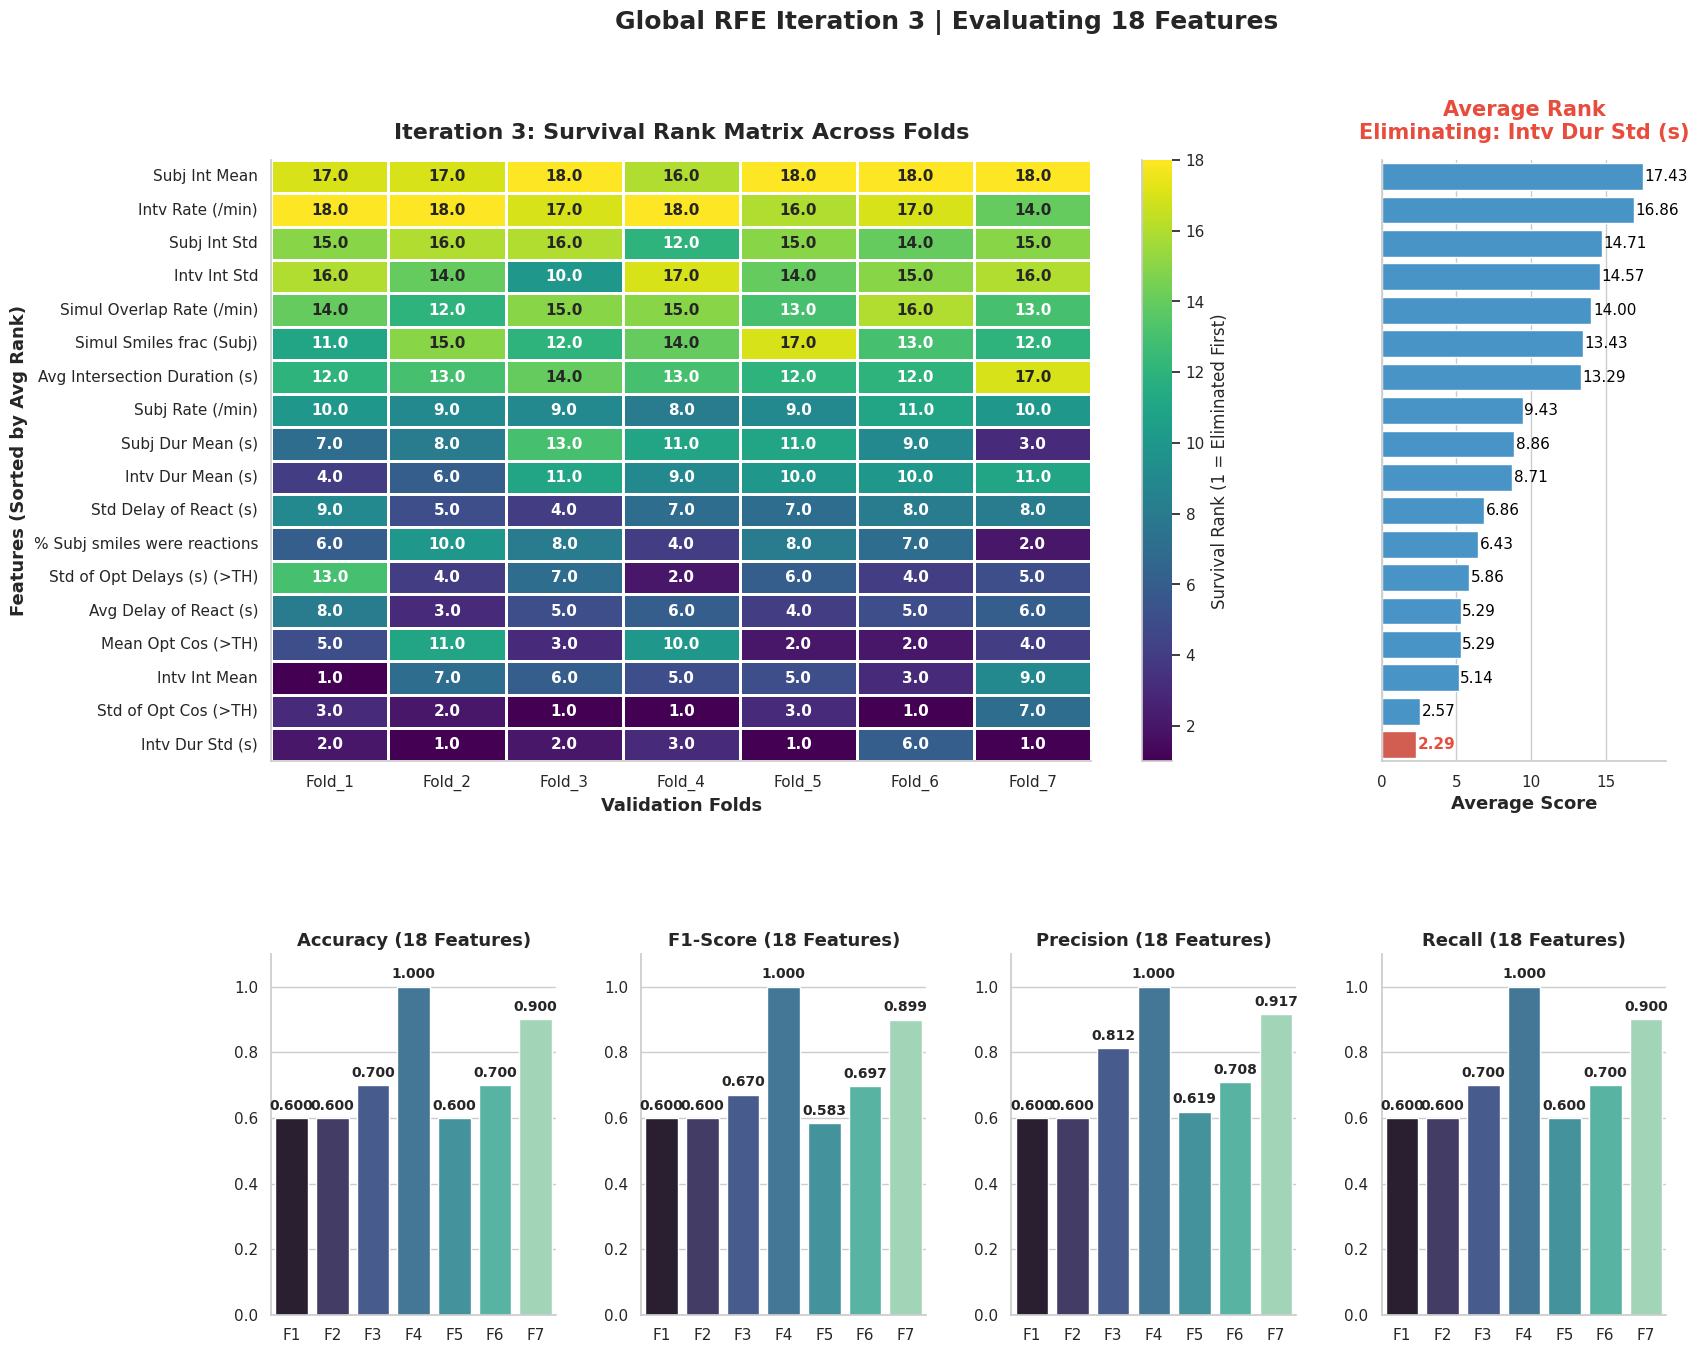

> Eliminating weakest feature: Interviewer Smile Duration Std (s) (Avg Rank: 2.29)

--- Iteration 4 | Evaluating 17 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

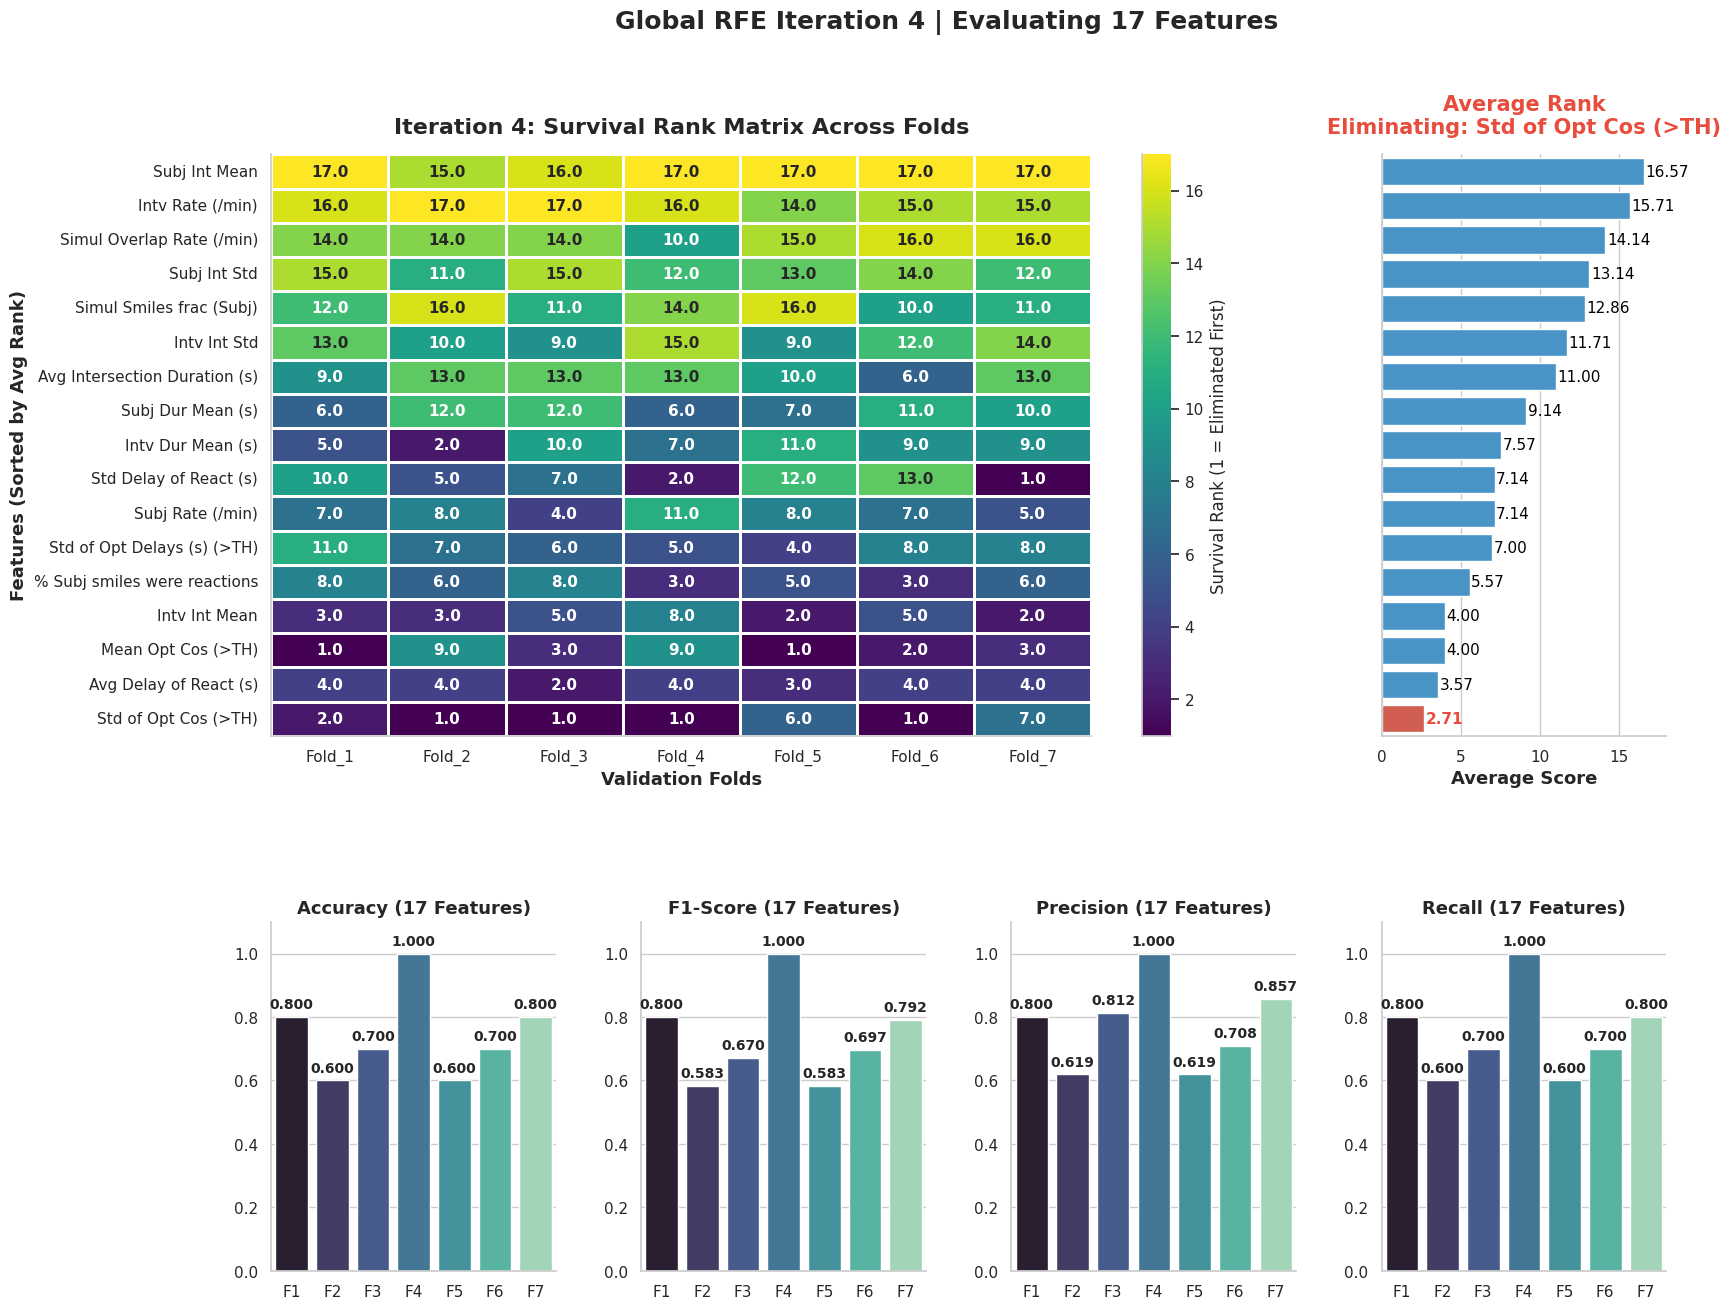

> Eliminating weakest feature: Std of Optimal Cosines (>TH) (Avg Rank: 2.71)

--- Iteration 5 | Evaluating 16 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

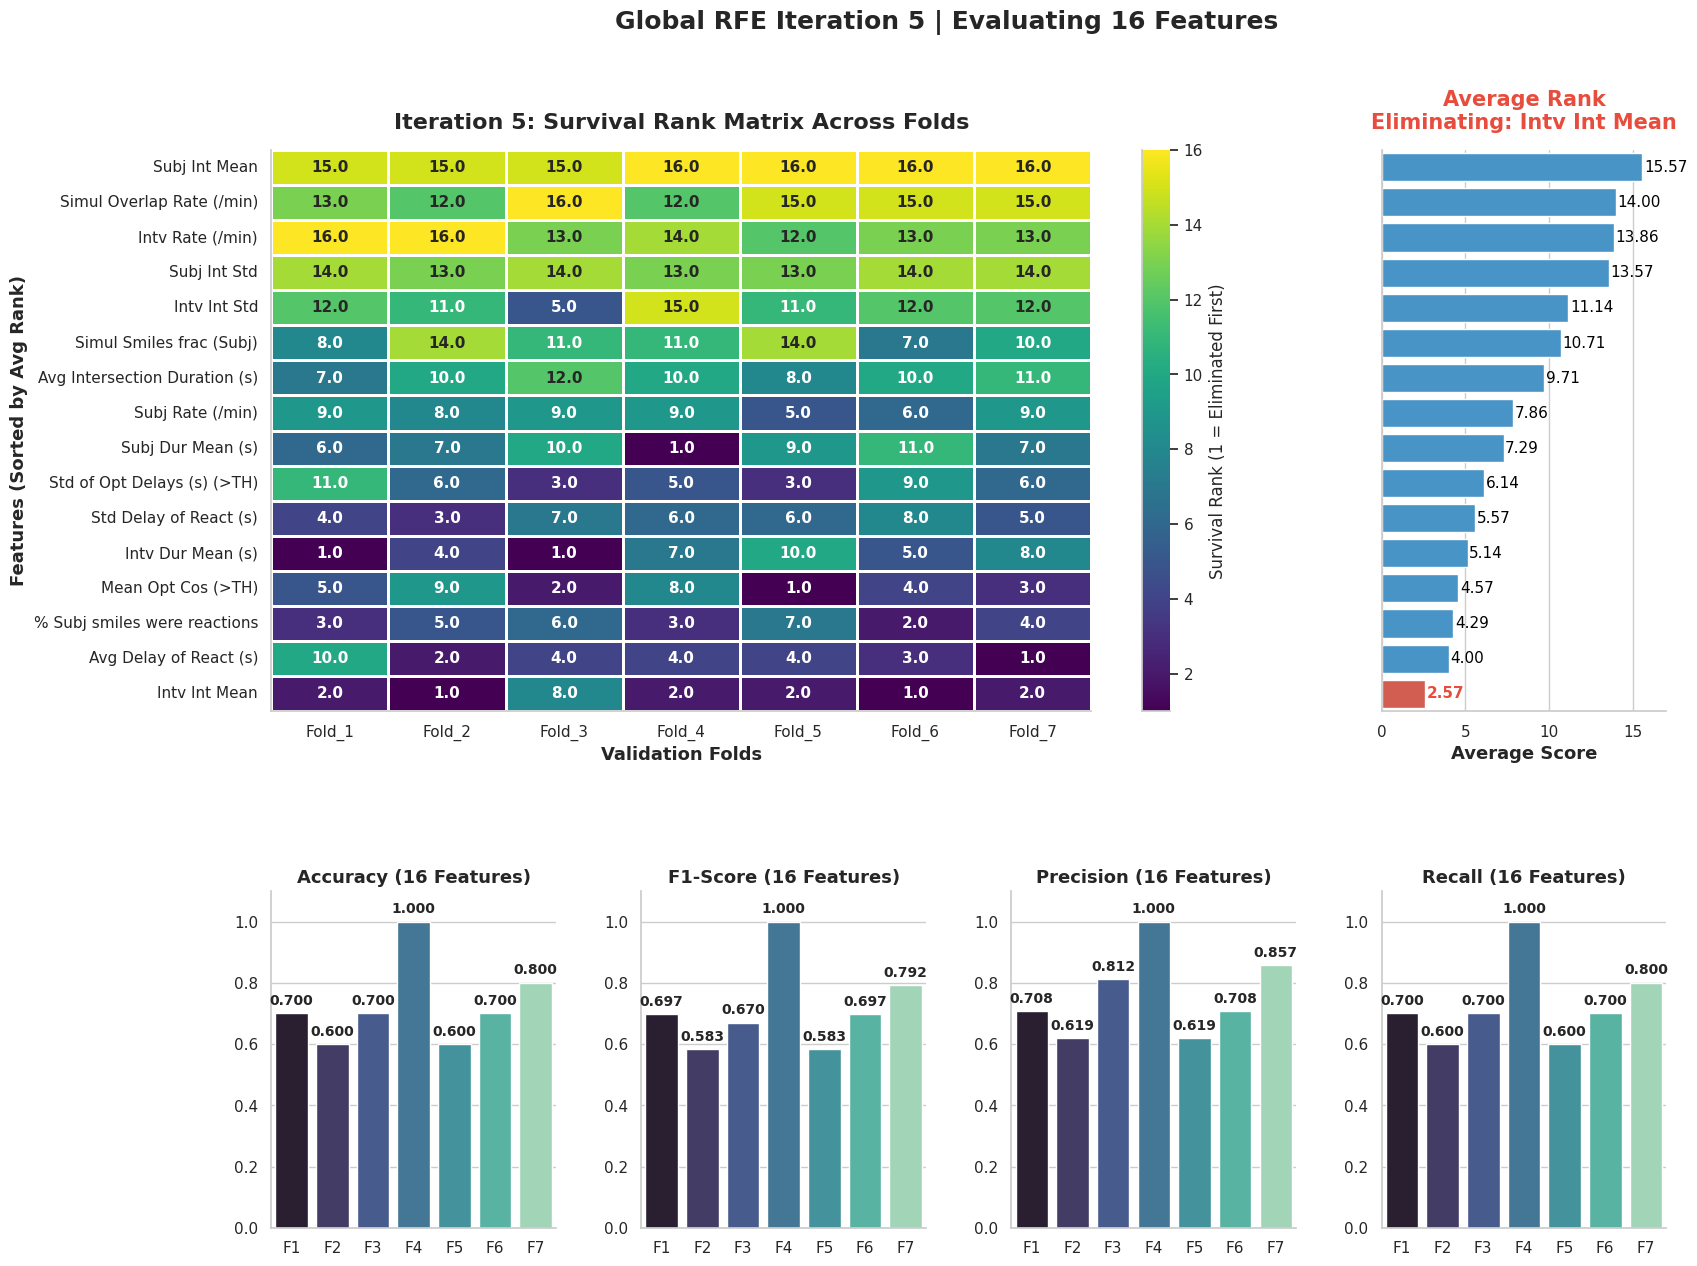

> Eliminating weakest feature: Interviewer Smile Intensity Mean (Avg Rank: 2.57)

--- Iteration 6 | Evaluating 15 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

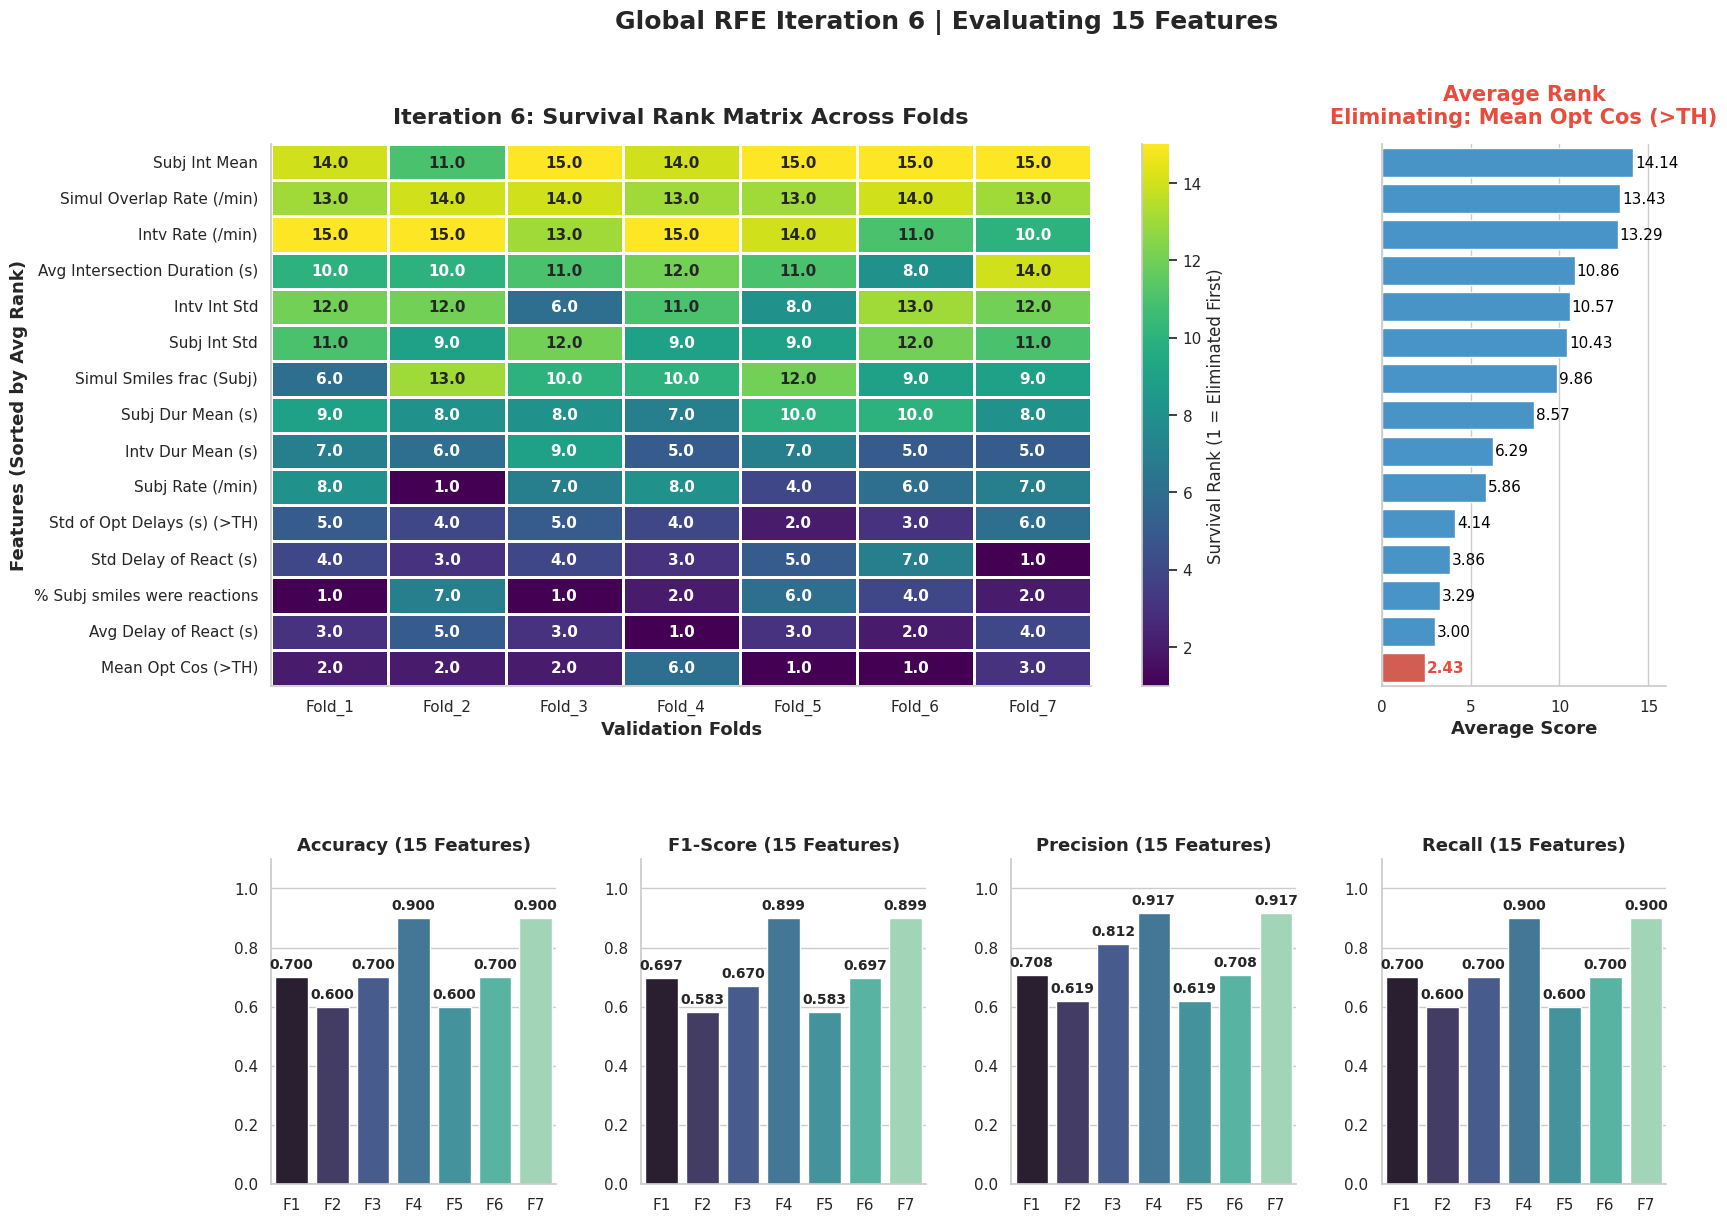

> Eliminating weakest feature: Mean of Optimal Cosines (>TH) (Avg Rank: 2.43)

--- Iteration 7 | Evaluating 14 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

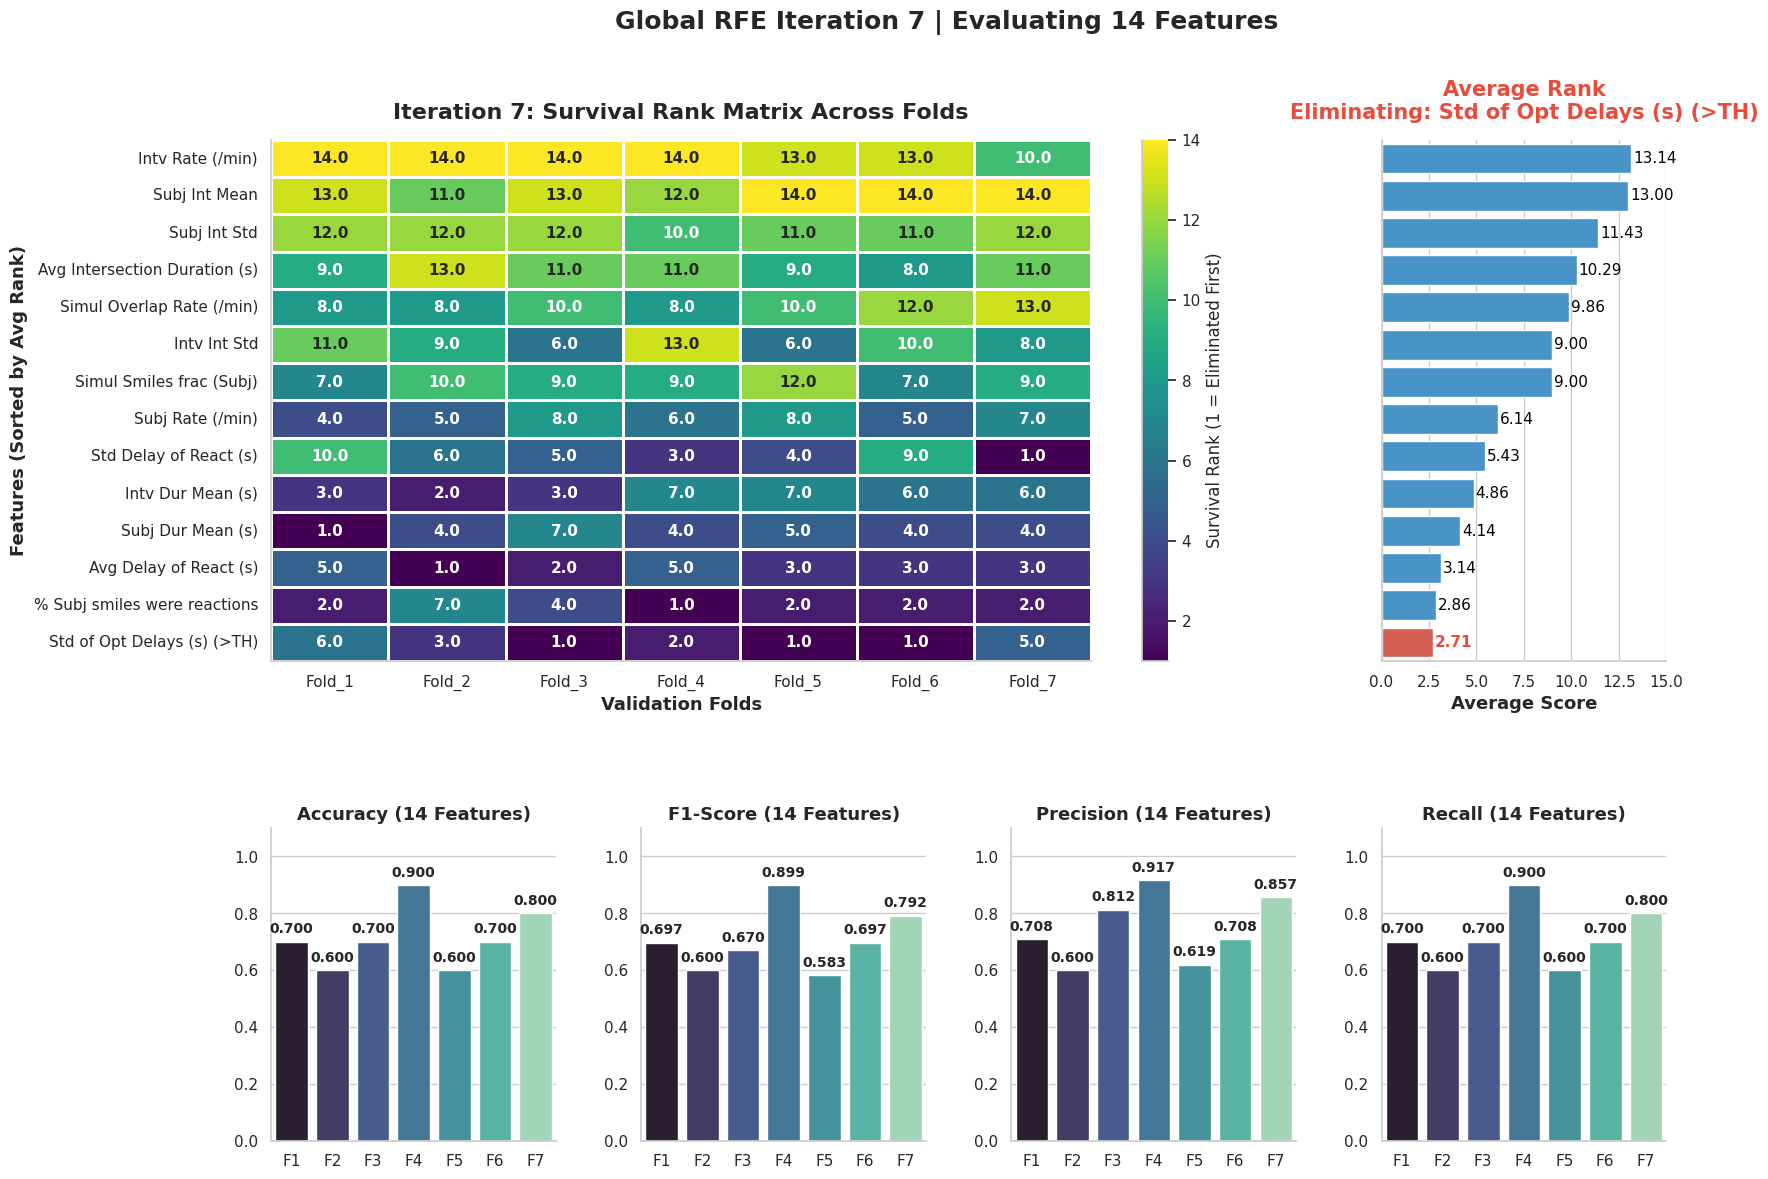

> Eliminating weakest feature: Std of Optimal Delays (s) (>TH) (Avg Rank: 2.71)

--- Iteration 8 | Evaluating 13 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

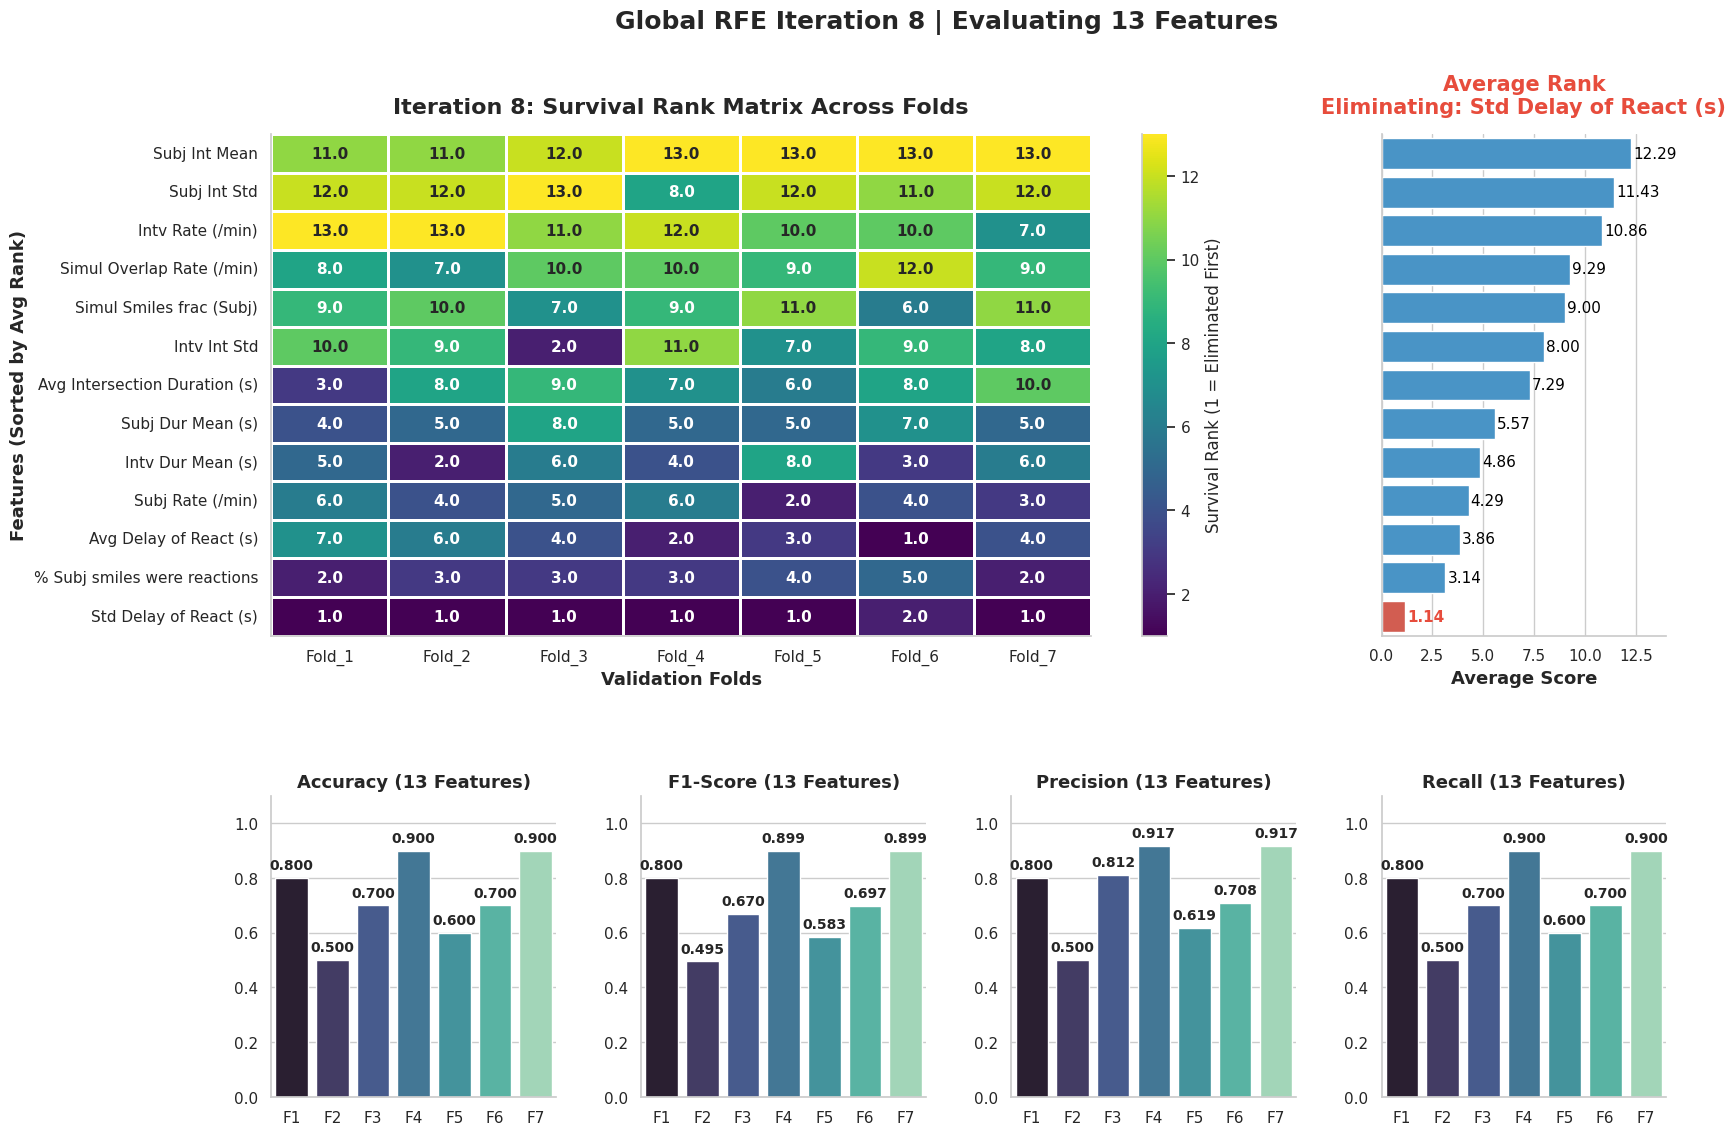

> Eliminating weakest feature: Std Dev of Delay of Reaction (s) (Avg Rank: 1.14)

--- Iteration 9 | Evaluating 12 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

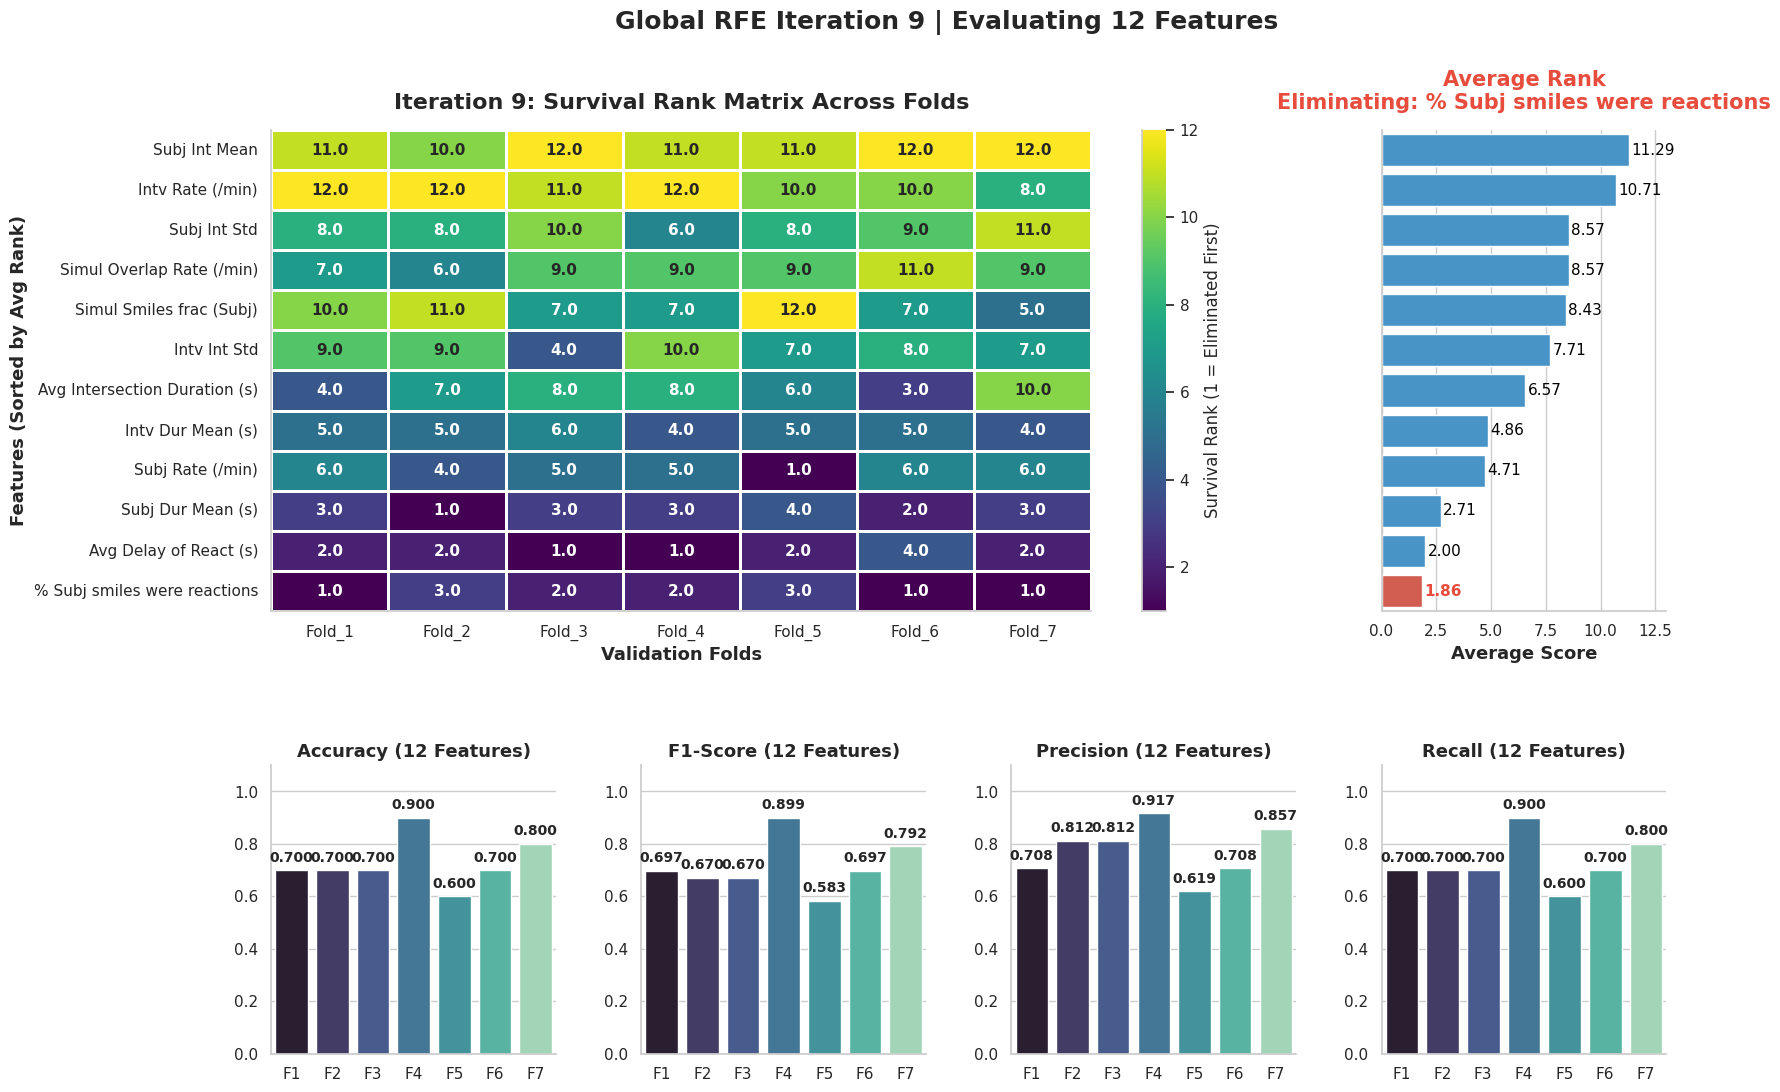

> Eliminating weakest feature: % of Subject's smiles that were reactions (Avg Rank: 1.86)

--- Iteration 10 | Evaluating 11 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

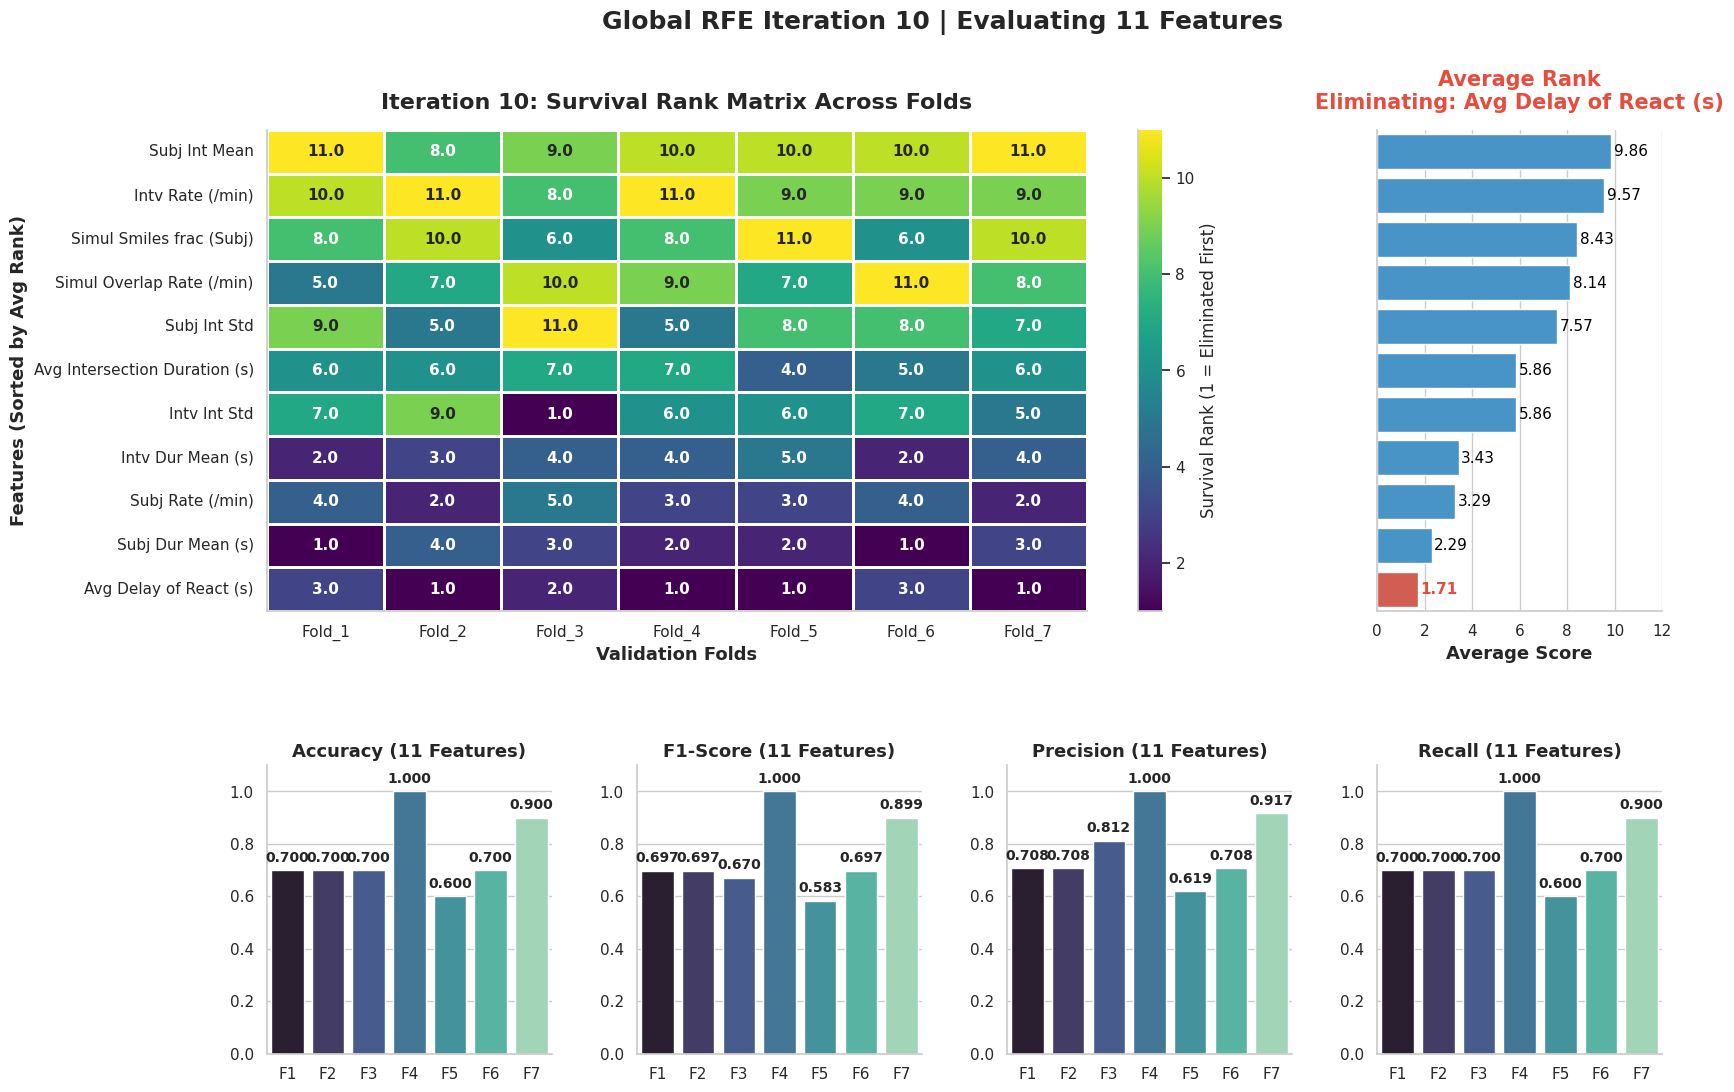

> Eliminating weakest feature: Average Delay of Reaction (s) (Avg Rank: 1.71)

--- Iteration 11 | Evaluating 10 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

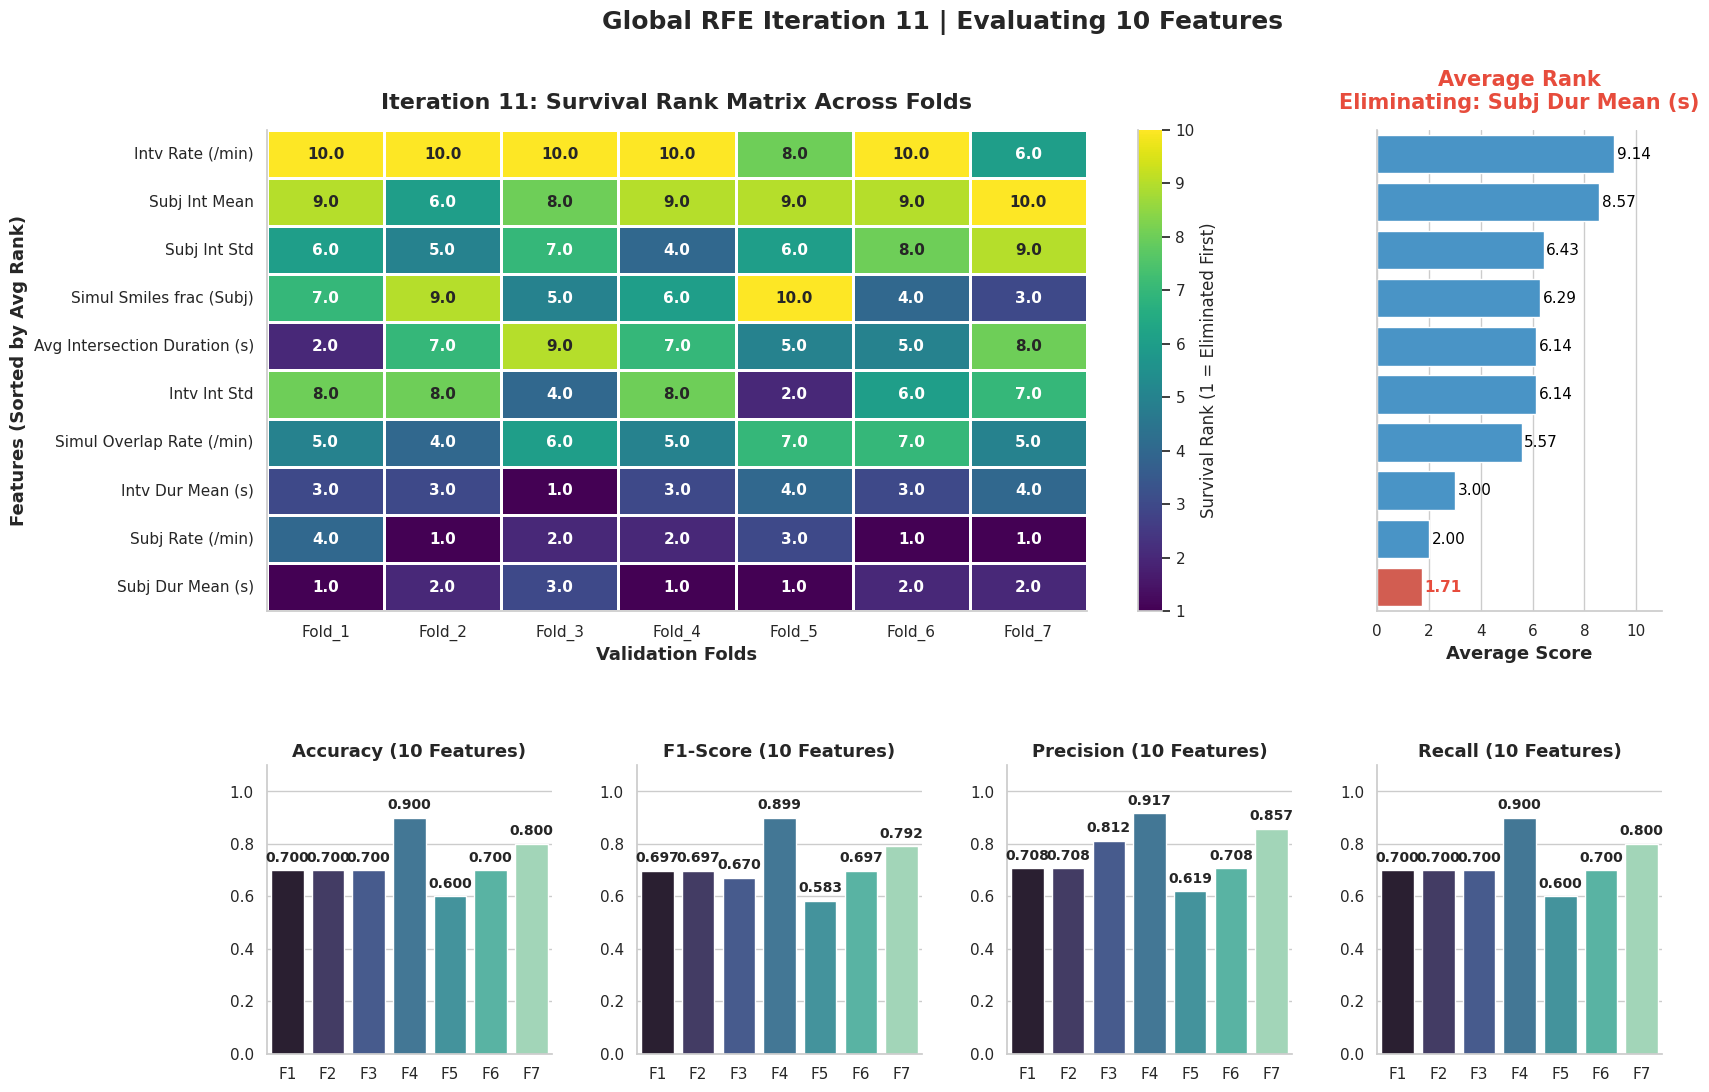

> Eliminating weakest feature: Subject Smile Duration Mean (s) (Avg Rank: 1.71)

--- Iteration 12 | Evaluating 9 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

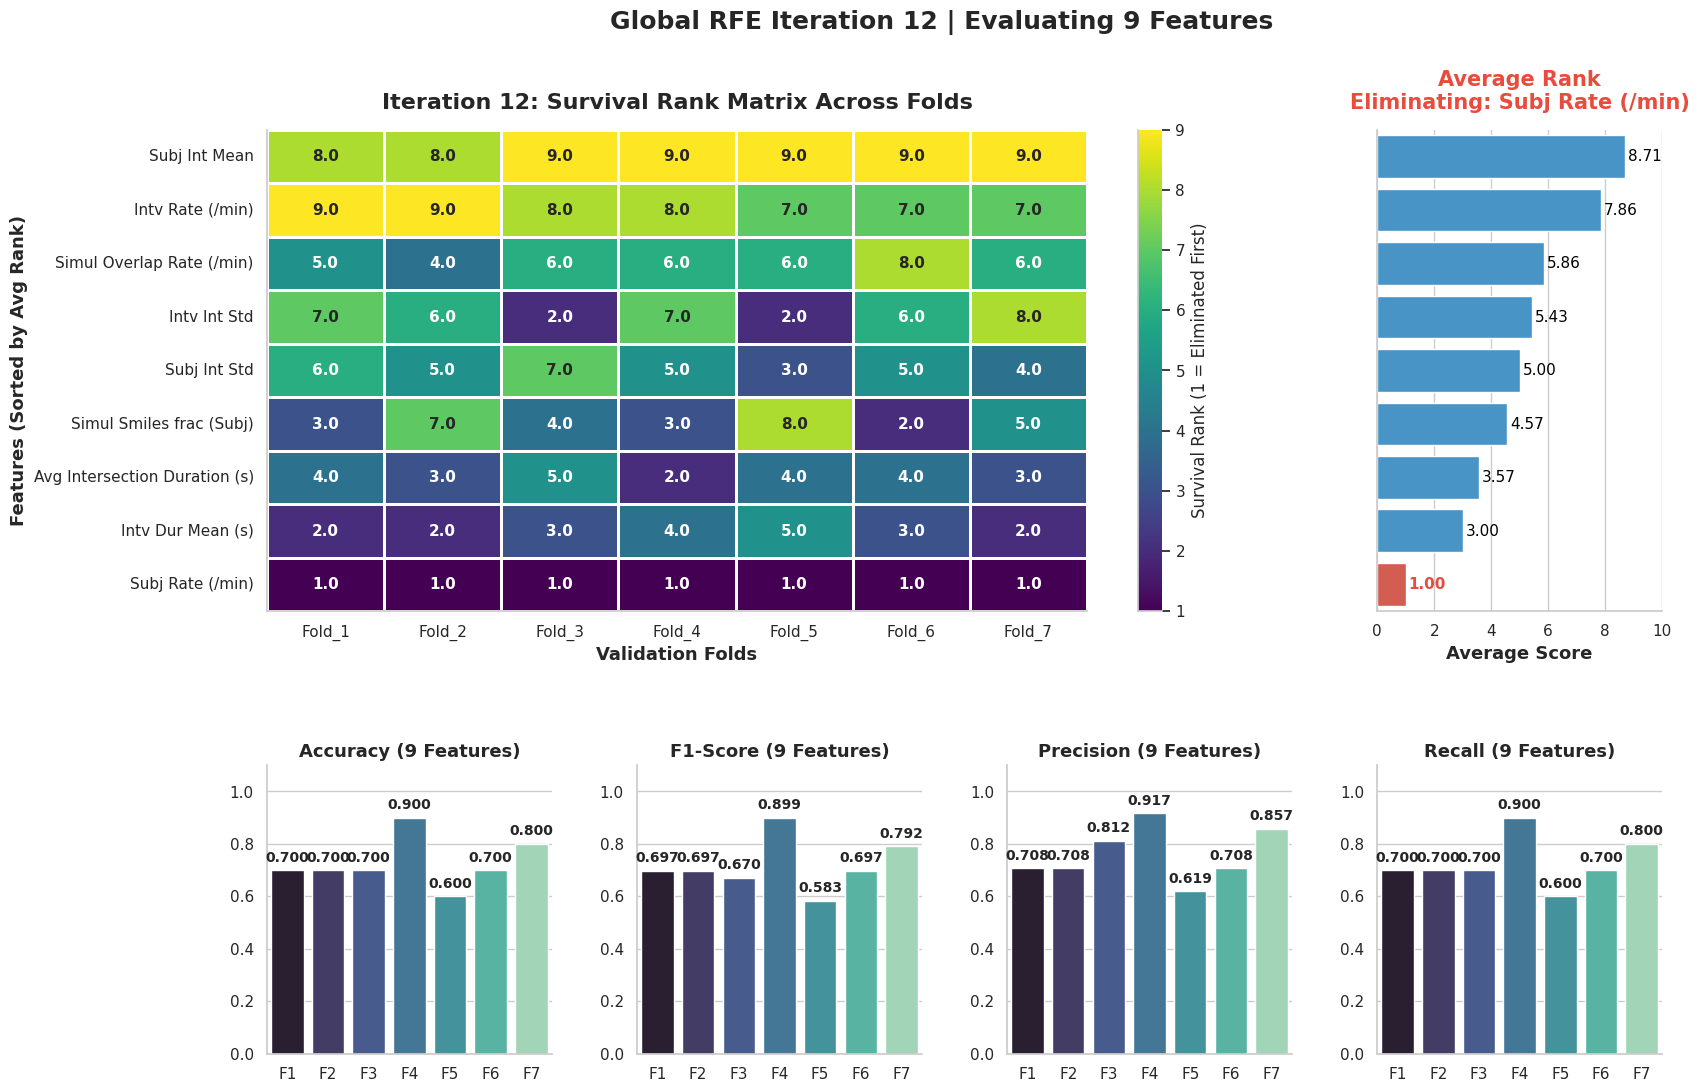

> Eliminating weakest feature: Subject Smile Rate (per min) (Avg Rank: 1.00)

--- Iteration 13 | Evaluating 8 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

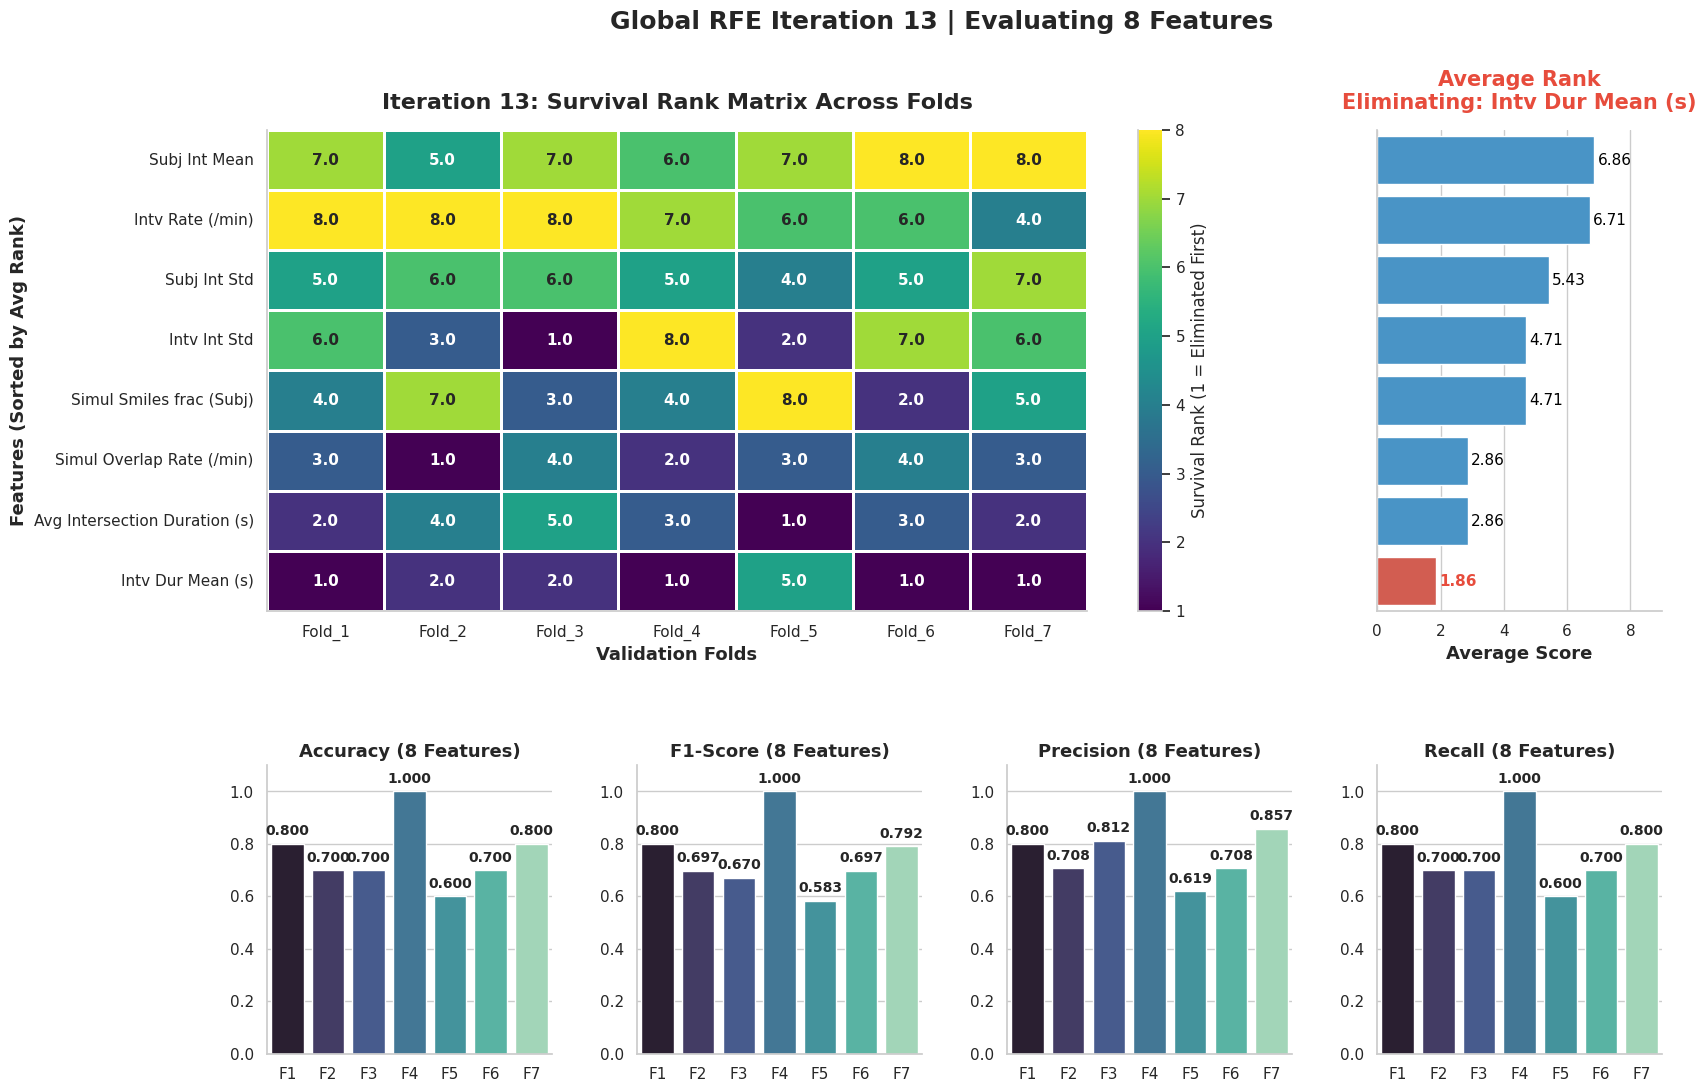

> Eliminating weakest feature: Interviewer Smile Duration Mean (s) (Avg Rank: 1.86)

--- Iteration 14 | Evaluating 7 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

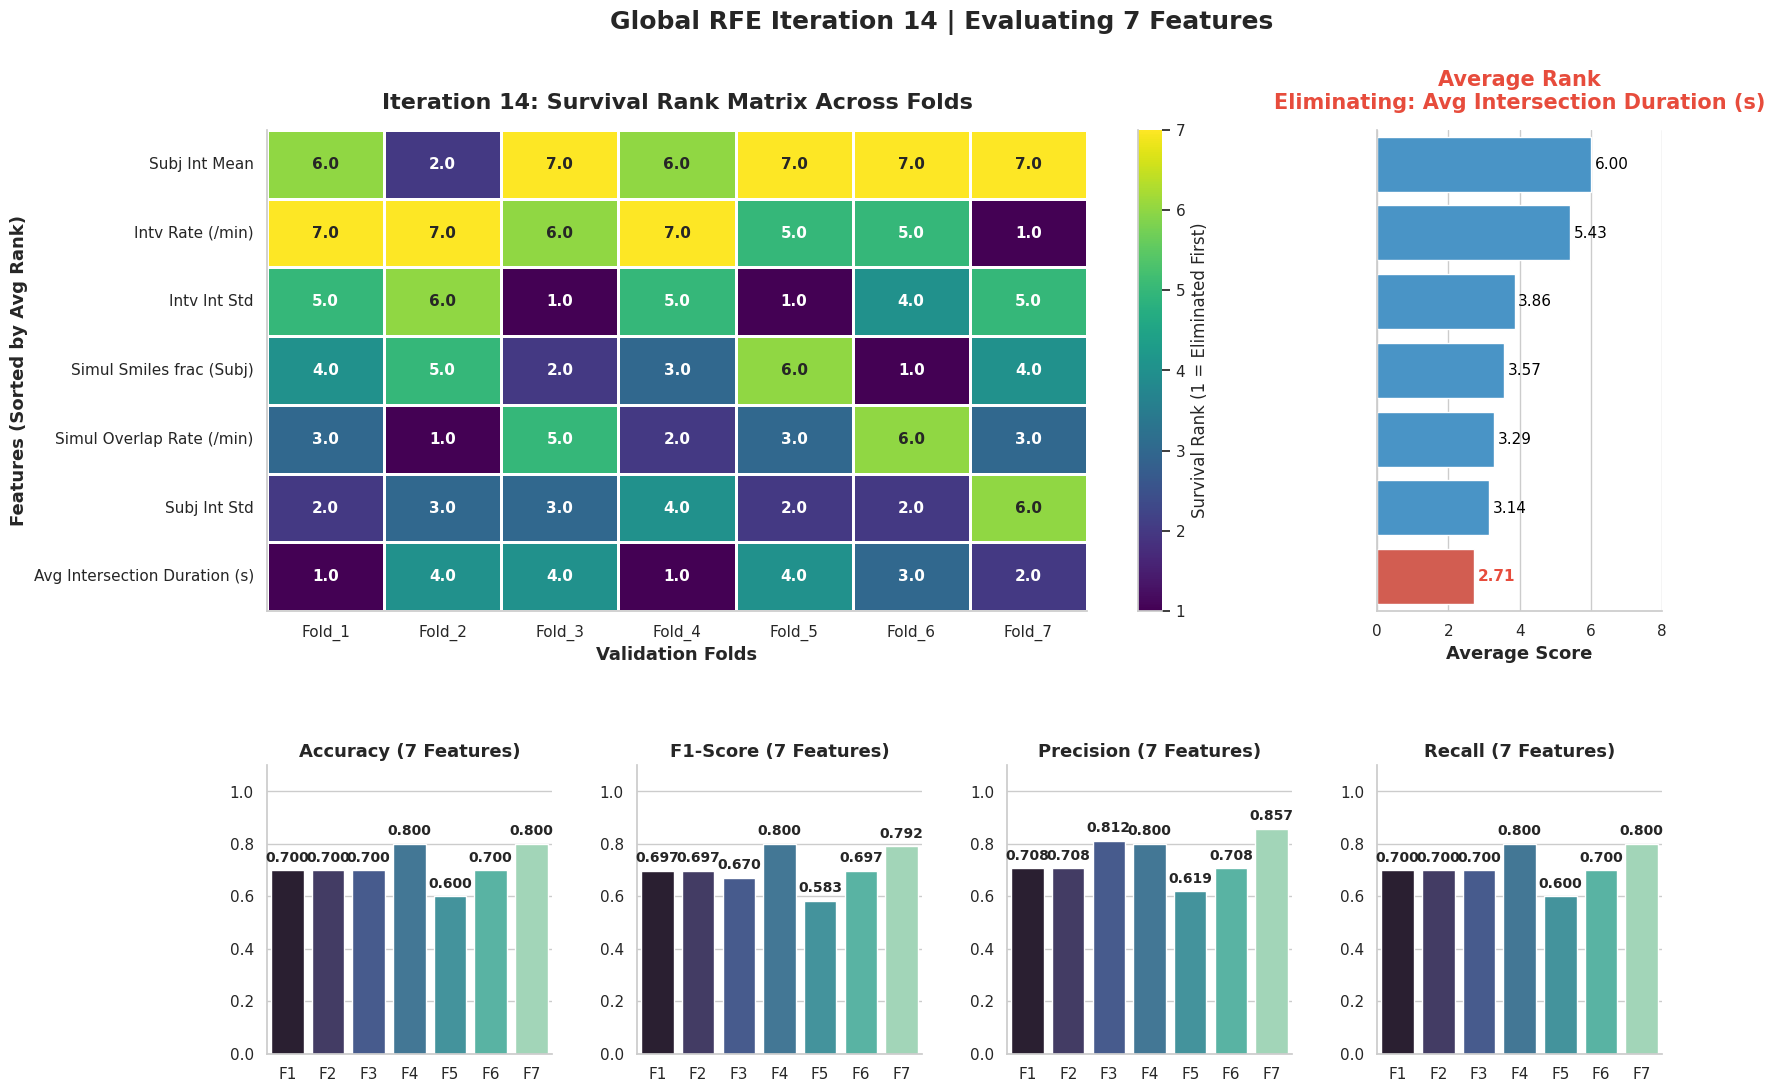

> Eliminating weakest feature: Average Intersection Duration (s) (Avg Rank: 2.71)

--- Iteration 15 | Evaluating 6 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

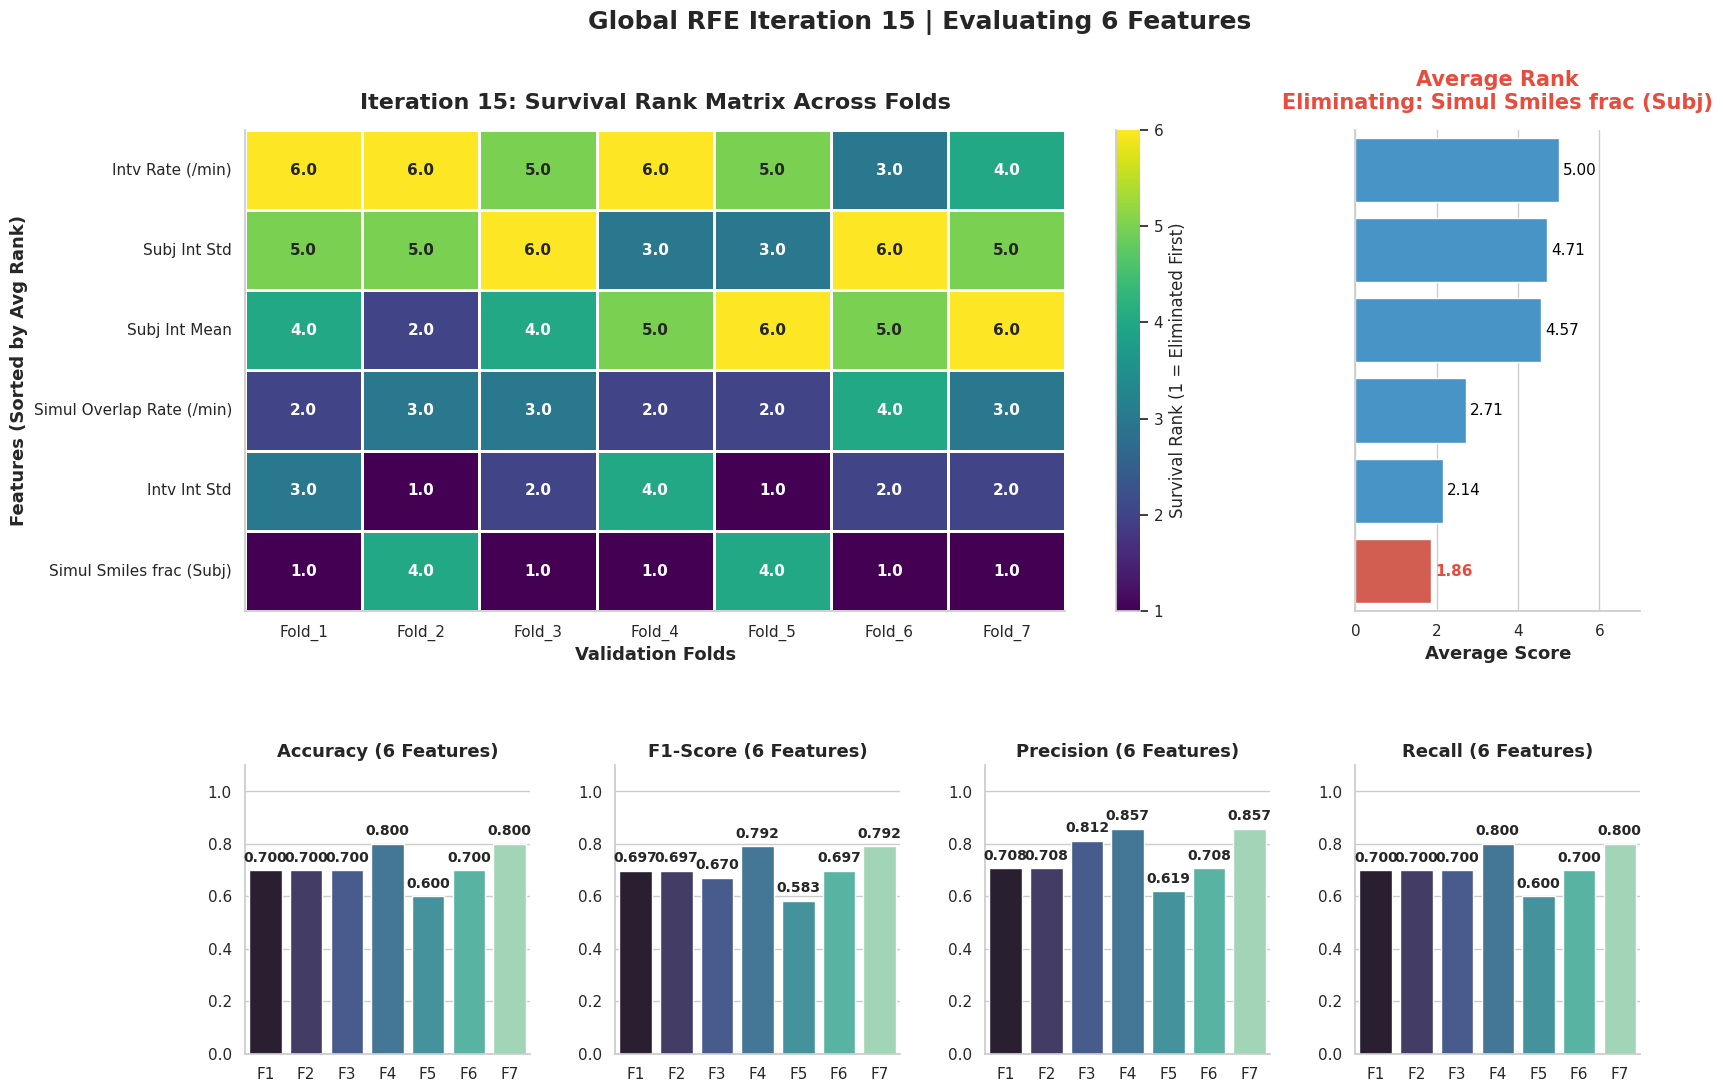

> Eliminating weakest feature: Simultaneous Smiles fraction (Subject) (Avg Rank: 1.86)

--- Iteration 16 | Evaluating 5 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

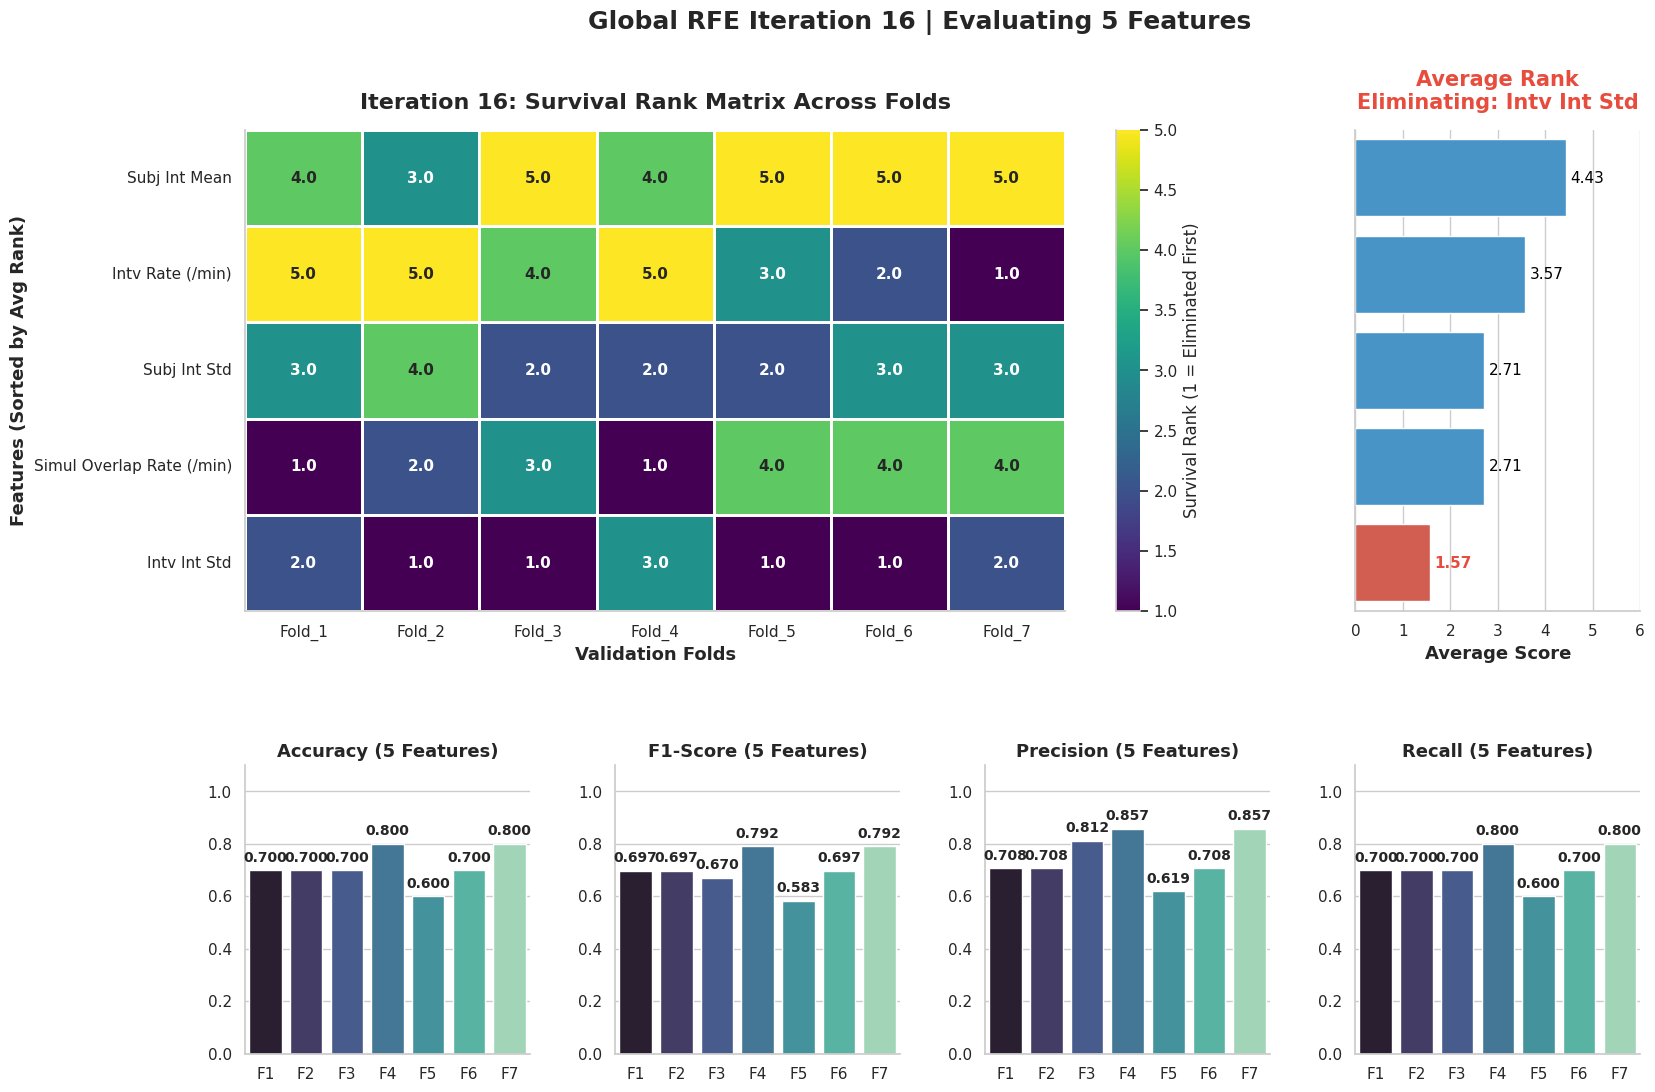

> Eliminating weakest feature: Interviewer Smile Intensity Std (Avg Rank: 1.57)

--- Iteration 17 | Evaluating 4 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

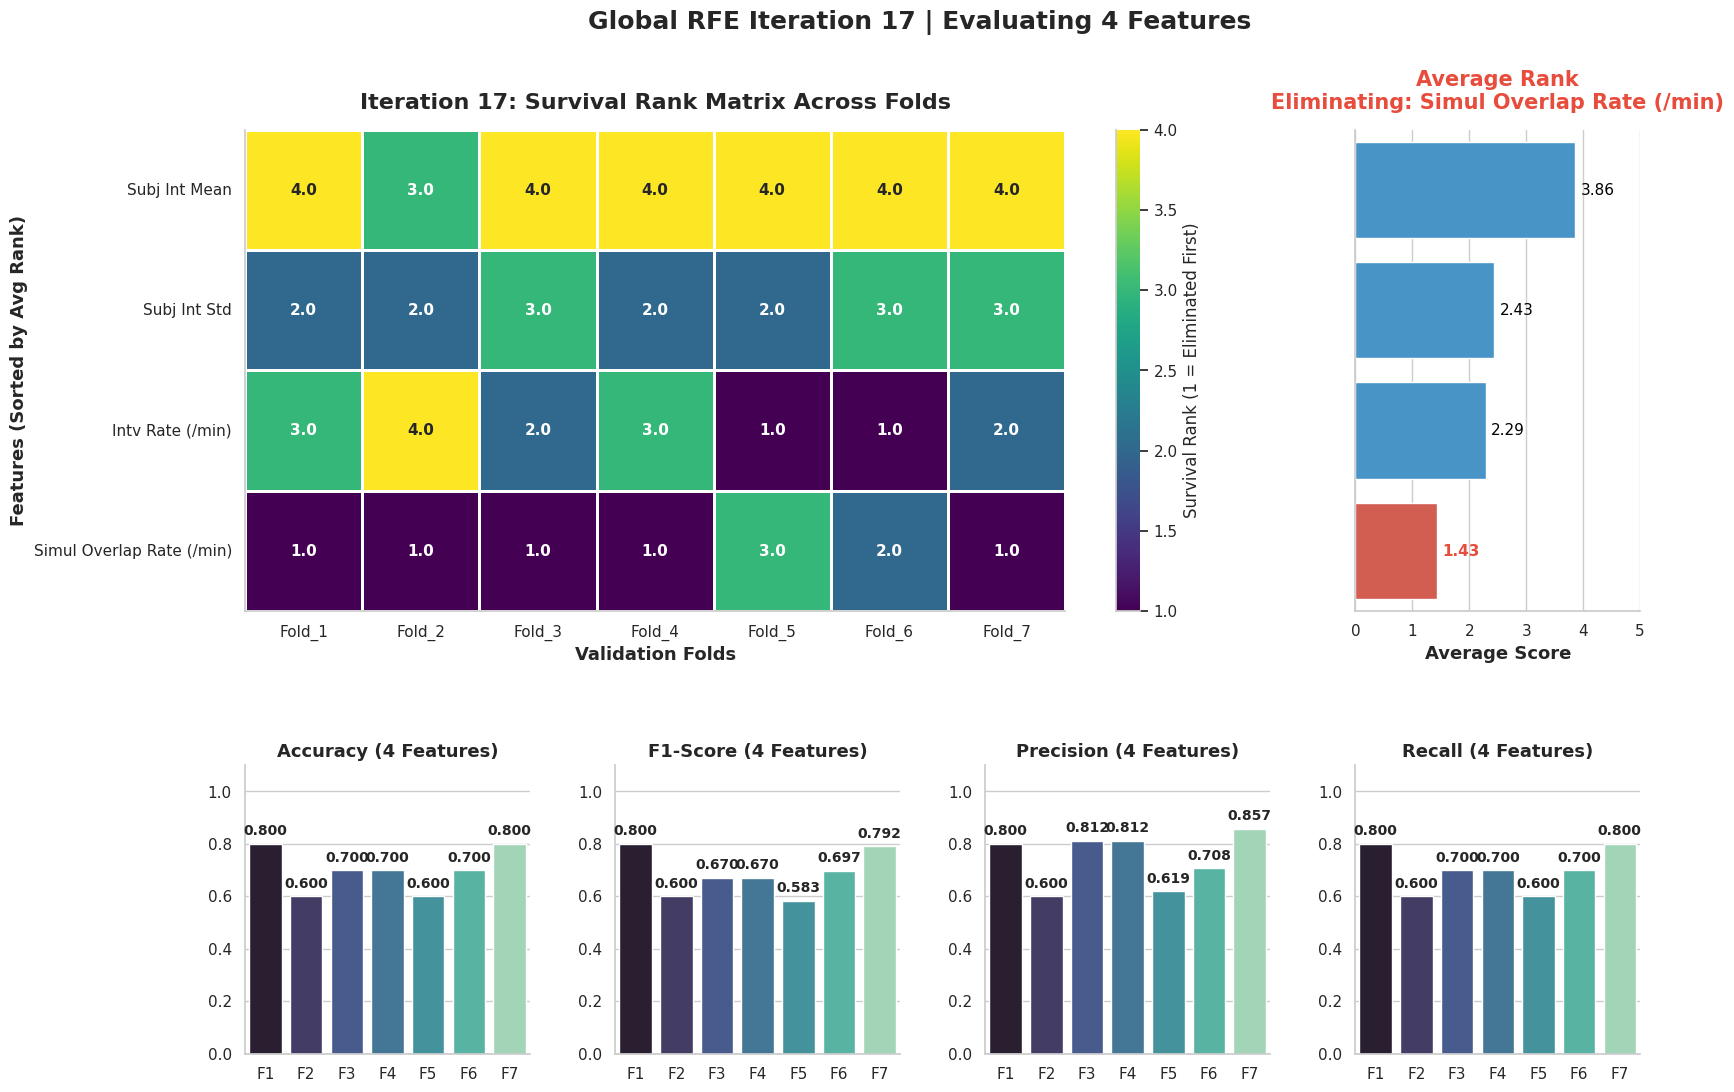

> Eliminating weakest feature: Simultaneous Smiles (Intersections) Rate (per min) (Avg Rank: 1.43)

--- Iteration 18 | Evaluating 3 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

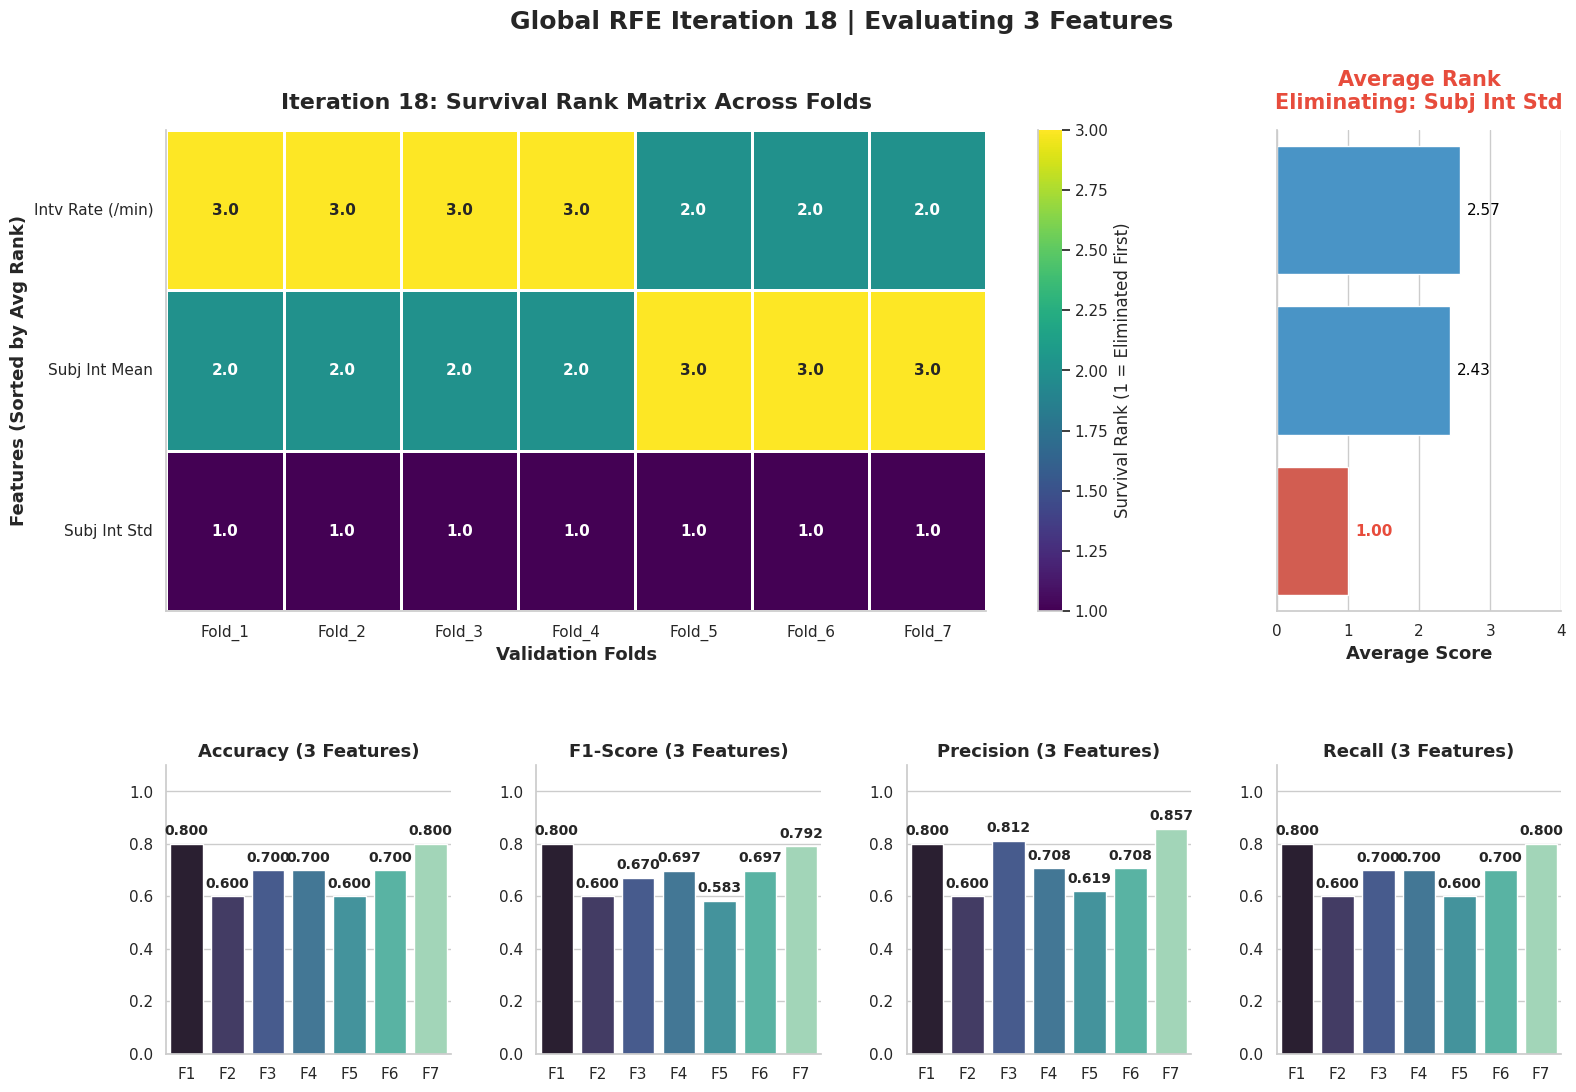

> Eliminating weakest feature: Subject Smile Intensity Std (Avg Rank: 1.00)

--- Iteration 19 | Evaluating 2 Features ---


/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Fold', y=metric_name, data=df_current_metrics, ax=ax, palette='mako')
/tmp/ipykernel_63045/3486710860.py:63: FutureWarning: 

Passing `palette`

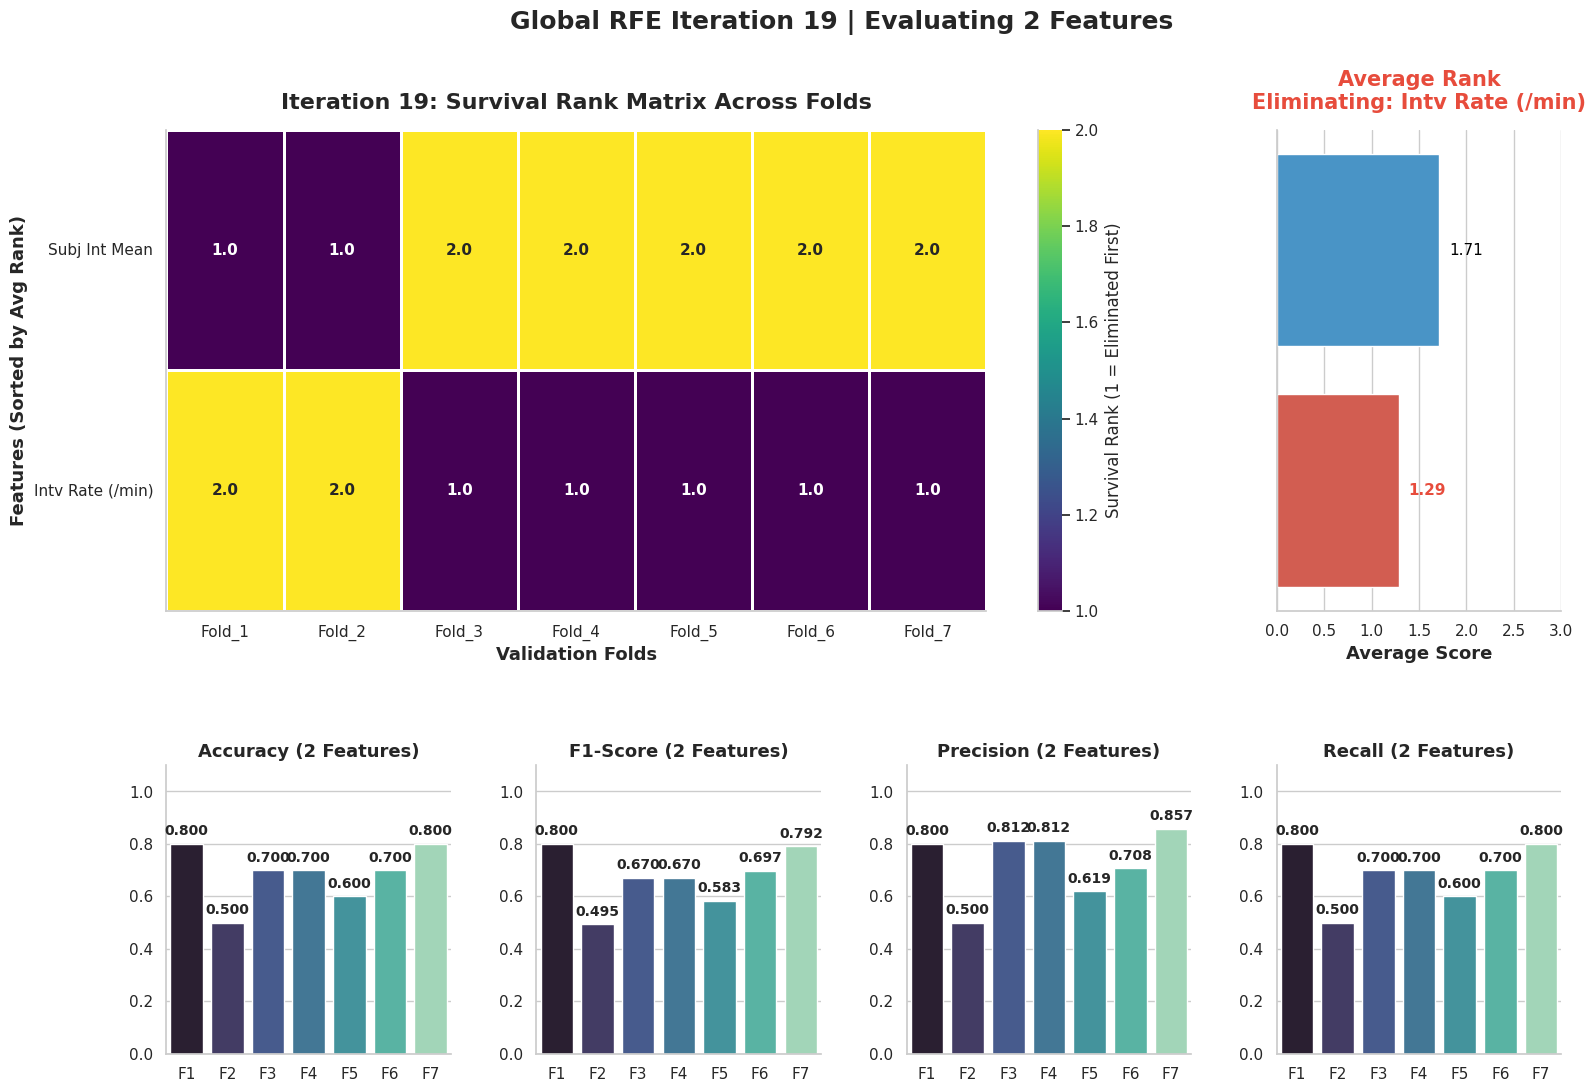

> Eliminating weakest feature: Interviewer Smile Rate (per min) (Avg Rank: 1.29)

RFE COMPLETE. FINAL SURVIVING FEATURE: Subject Smile Intensity Mean

Elimination History:
    Iteration                                    Dropped_Feature  \
0           1                                           Gender_M   
1           2      % of Interviewer's smiles that got a reaction   
2           3                 Interviewer Smile Duration Std (s)   
3           4                       Std of Optimal Cosines (>TH)   
4           5                   Interviewer Smile Intensity Mean   
5           6                      Mean of Optimal Cosines (>TH)   
6           7                    Std of Optimal Delays (s) (>TH)   
7           8                   Std Dev of Delay of Reaction (s)   
8           9          % of Subject's smiles that were reactions   
9          10                      Average Delay of Reaction (s)   
10         11                    Subject Smile Duration Mean (s)   
11         1

In [36]:
if __name__ == "__main__":
    # ... (Assuming your previous code ran and produced 'fold_best_features') ...
    
    print(f"Total Unique Best Features Extracted: {len(all_features_set)}")
    
    # 2. Run the Global Consensus RFE
    final_survivor, rfe_history_df = consensus_global_rfe_rf(X=X_scaled, y=y, initial_features=all_features_set, K_FOLDS=7)
    
    # Optional: Display the history of accuracy drops as features were eliminated
    print("\nElimination History:")
    print(rfe_history_df)

Loaded 70 subjects.
Generating Boxplot Dashboards for 19 features...


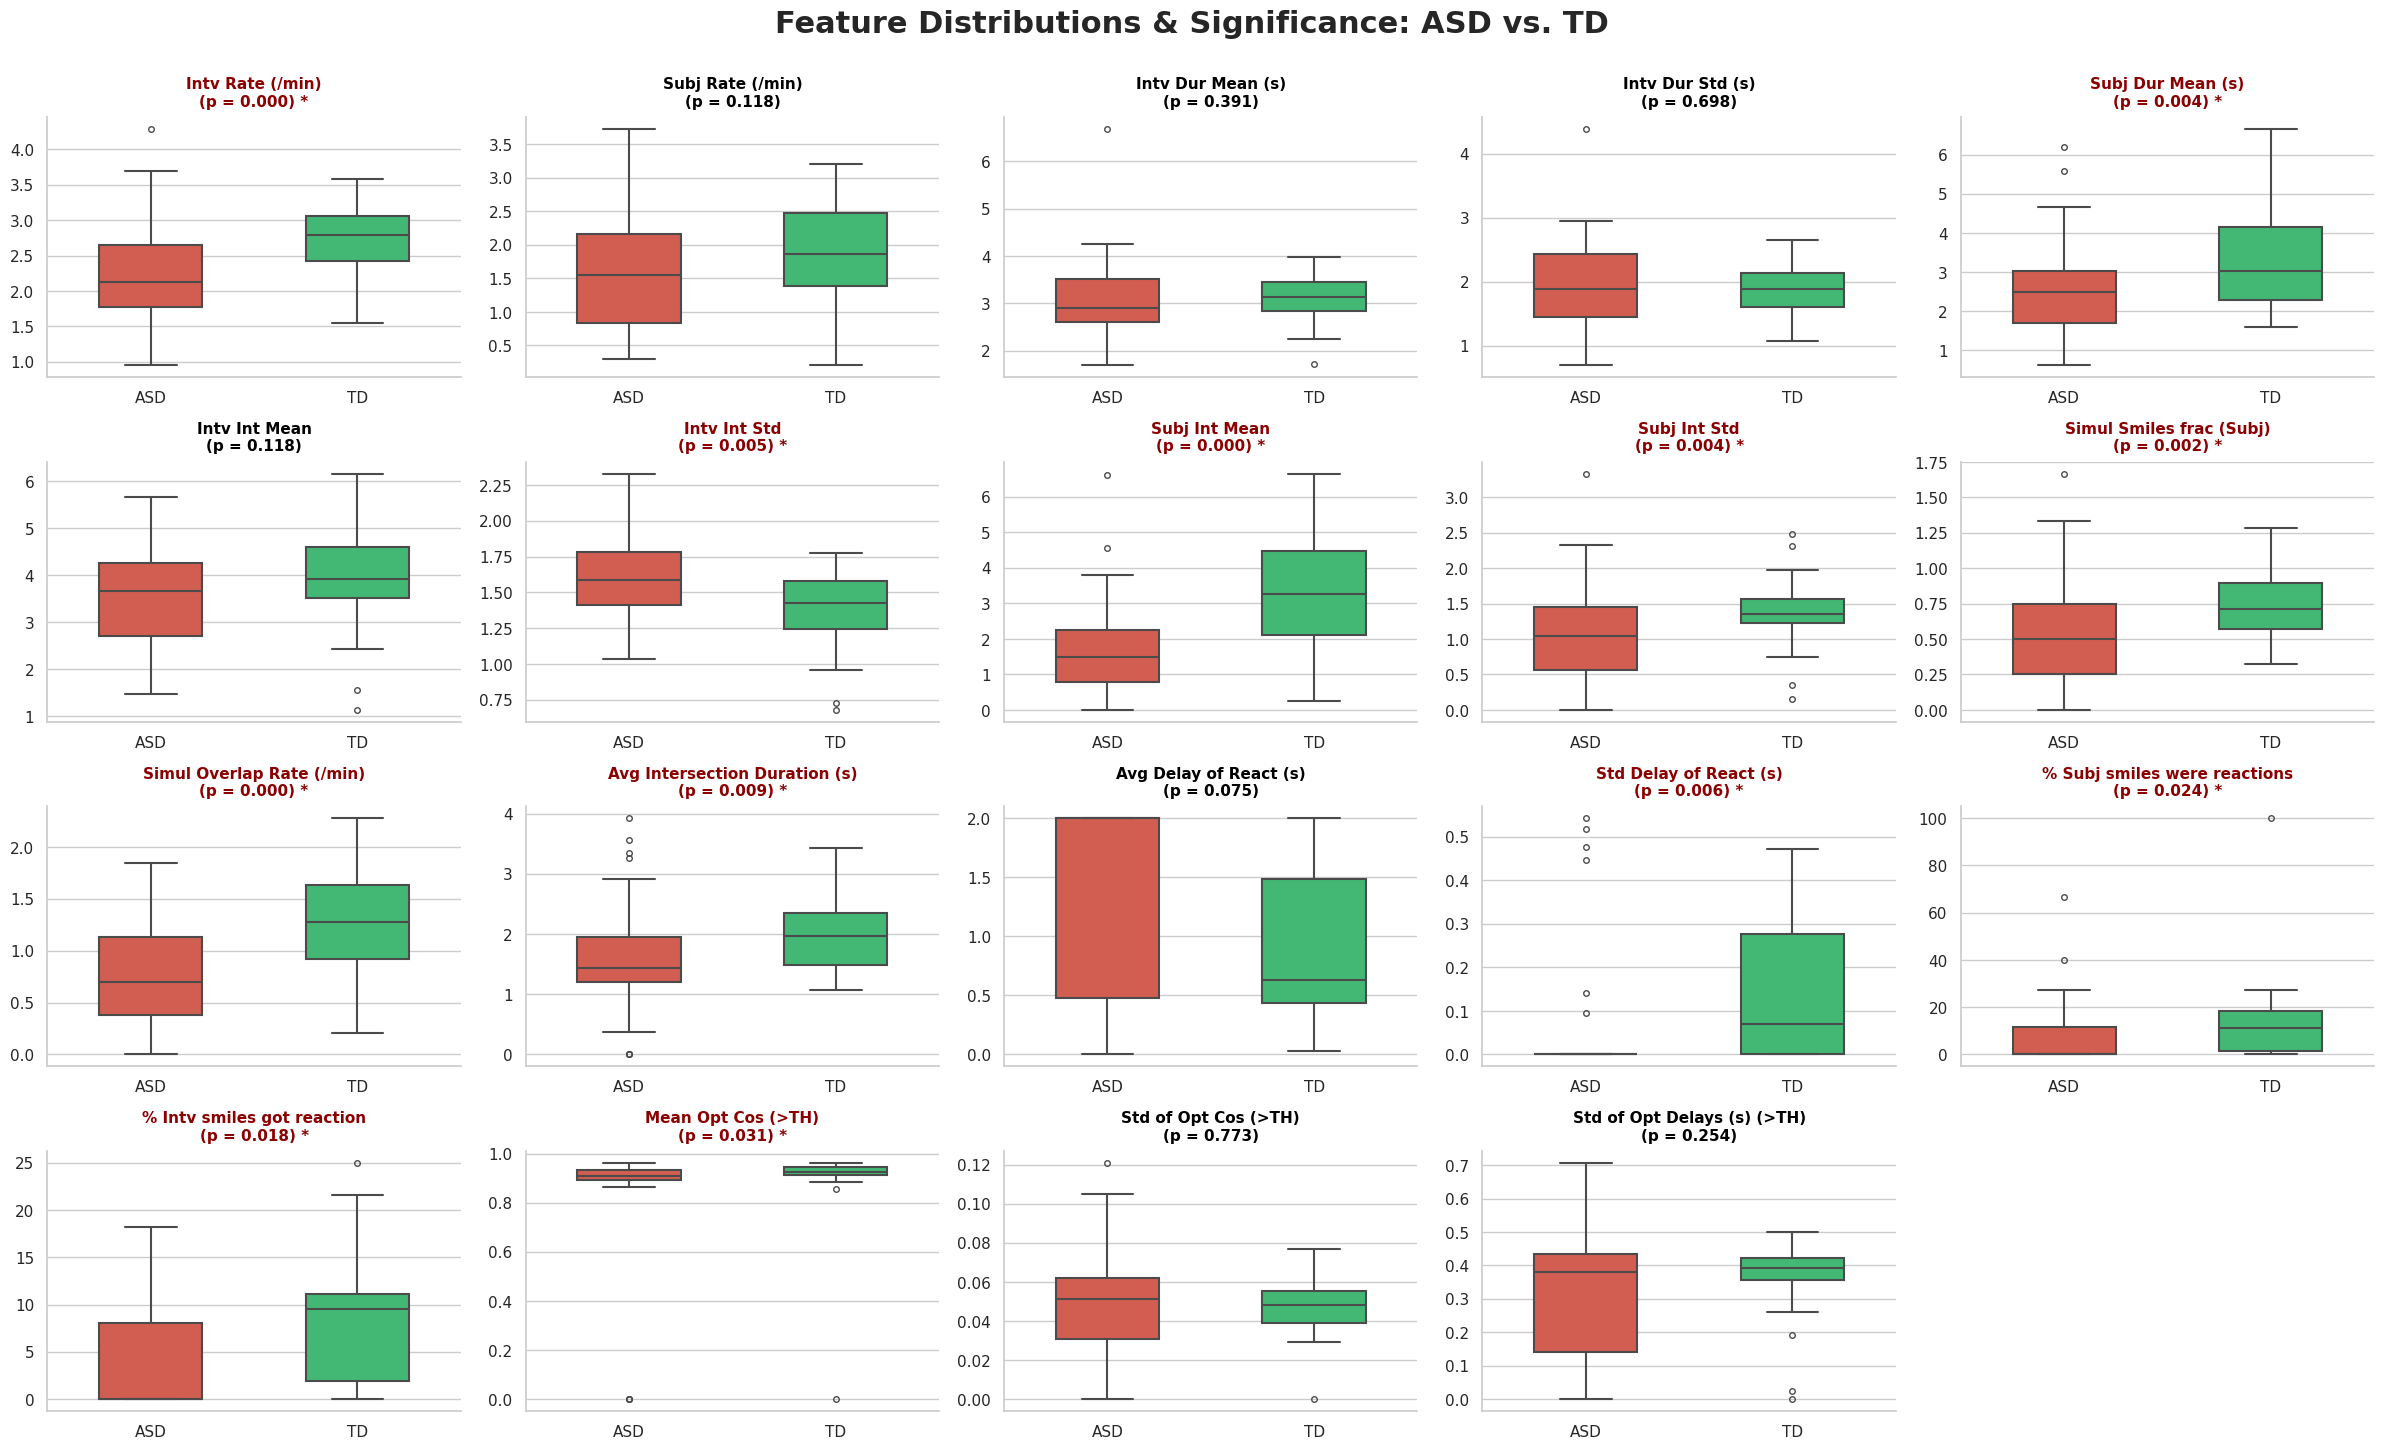

In [38]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# =============================================================================
# 1. Setup & Data Loading
# =============================================================================
df = pd.read_csv(DATA_PATH)

# Explicitly define metadata so we only plot the behavioral features
metadata_cols = ['Subject Number', 'Label', 'Gender']
feature_cols = [col for col in df.columns if col not in metadata_cols]

# Create a readable label column for the grouped plots 
df['Diagnosis'] = df['Label'].map({1: 'ASD', 0: 'TD'})

print(f"Loaded {len(df)} subjects.")
print(f"Generating Boxplot Dashboards for {len(feature_cols)} features...")

# =============================================================================
# 2. Figure 2: Grouped Boxplots (ASD vs. TD) with P-Values
# =============================================================================
# Set a distinct color palette for the two classes
class_palette = {'ASD': '#e74c3c', 'TD': '#2ecc71'}

fig2, axes2 = plt.subplots(5, 5, figsize=(24, 18)) 
fig2.suptitle('Feature Distributions & Significance: ASD vs. TD', fontsize=22, fontweight='bold', y=0.98)

axes2_flat = axes2.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes2_flat[i]
    
    # --- A. Statistical Testing (Mann-Whitney U) ---
    asd_data = df[df['Diagnosis'] == 'ASD'][feature].dropna()
    td_data = df[df['Diagnosis'] == 'TD'][feature].dropna()
    
    # Calculate p-value (ignoring features with no variance or completely empty)
    if len(asd_data) > 0 and len(td_data) > 0:
        _, p_value = stats.mannwhitneyu(asd_data, td_data, alternative='two-sided')
    else:
        p_value = 1.0
        
    # --- B. Plotting ---
    sns.boxplot(
        data=df, 
        x='Diagnosis', 
        y=feature, 
        hue='Diagnosis',
        palette=class_palette, 
        ax=ax, 
        width=0.5, 
        linewidth=1.5, 
        fliersize=4,
        legend=False 
    )
    
    # --- C. Dynamic Title Formatting ---
    # Shorten the feature name so it fits in the grid
    short_name = abbreviate_feature_name(feature)
    
    # Highlight significant features in dark red with an asterisk
    if p_value < 0.05:
        title_text = f"{short_name}\n(p = {p_value:.3f}) *"
        title_color = 'darkred'
    else:
        title_text = f"{short_name}\n(p = {p_value:.3f})"
        title_color = 'black'
        
    ax.set_title(title_text, fontsize=11, fontweight='bold', color=title_color, pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
# Hide the remaining unused subplots
for j in range(i + 1, len(axes2_flat)):
    fig2.delaxes(axes2_flat[j])

sns.despine(fig=fig2)
fig2.tight_layout()
fig2.subplots_adjust(top=0.92)

plt.show()